# Testfunktionen

Das Notebook behandelt beide Bedeutungen des Wortes und rechnet jede Aussage mit numpy, scipy und sympy nach: glatte Funktionen mit kompaktem Träger (Bump-Funktionen) für Glättung, Zerlegungen der Eins, Distributionen und schwache Lösungen, mit ihrem Fourier-Abfall $k^{-3/4}e^{-\sqrt k}$, und Benchmark-Funktionen der Optimierung (Himmelblau, Rosenbrock, Rastrigin, Ackley und acht weitere) mit kritischen Punkten, Einzugsgebieten und einem Vergleich lokaler und globaler Verfahren. Ein Quanten-Zusatz zeigt beide Arten in Quantenalgorithmen: Fenster für die Phasenschätzung, glatte Zeitpläne für adiabatisches Rechnen, Grover-Minimumsuche auf einer diskretisierten Benchmark-Funktion und flache VQE-Landschaften (Barren Plateaus).

Was ist eine Testfunktion, wozu braucht man eine Funktion, die beliebig glatt und trotzdem außerhalb eines Intervalls exakt null ist, wozu eine Funktion, deren Minima man schon kennt, und wo tauchen beide in Quantenalgorithmen auf?

#### **Hintergrund**

Das Wort *Testfunktion* hat zwei Bedeutungen. Gemeinsam ist ihnen nur die Idee: Man untersucht etwas Unbekanntes, indem man es an etwas Bekanntem testet.

**Testfunktionen der Analysis** sind Funktionen $\varphi$, die beliebig oft differenzierbar und außerhalb eines beschränkten Intervalls exakt null sind. Das Standardbeispiel ist die Bump-Funktion
$$\Psi(x) = \begin{cases}e^{-1/(1 - x^2)} & \vert x\vert<1,\\ 0 & \vert x\vert\geq1.\end{cases}$$
Man braucht sie für Objekte, die keine gewöhnlichen Funktionen sind oder sich nicht differenzieren lassen. Die Delta-„Funktion“ hat bei 0 keinen Wert, aber man kann sagen, was sie mit jeder Testfunktion macht: $\langle\delta,\varphi\rangle = \varphi(0)$. Ein Knick hat an der Knickstelle keine Ableitung, aber man kann die Ableitung per partieller Integration auf $\varphi$ schieben; Randterme entstehen nicht, weil $\varphi$ außerhalb eines Intervalls null ist. Beide Eigenschaften sind nötig: Glattheit, damit man beliebig oft ableiten kann, und kompakter Träger, damit alle Integrale endlich sind und nur von einer Umgebung abhängen. Dieselben Funktionen nutzt man zum Glätten (Mollifier), zum Ein- und Ausschalten ohne Störungen (Fenster, Pulse, Zeitpläne) und zum Zusammensetzen lokaler Konstruktionen (Zerlegung der Eins).

**Testfunktionen der Optimierung** (Benchmark-Funktionen) haben eine geschlossene Formel und ein bekanntes globales Minimum und enthalten gezielt eine bestimmte Schwierigkeit: ein schmales gekrümmtes Tal (Rosenbrock), vier gleich tiefe Minima (Himmelblau), ein Gitter aus $11^d$ lokalen Minima (Rastrigin), eine flache Ebene mit einer Nadel (Easom). An ihnen prüft man Optimierungsverfahren: Findet das Verfahren das Minimum, mit wie vielen Funktionsauswertungen, und woran scheitert es? Weil die Lösung bekannt ist, lässt sich Erfolg exakt messen. Bei echten Problemen, etwa beim Training eines neuronalen Netzes oder eines variationellen Quantenalgorithmus, kennt man das Minimum nicht.

Wann man was nutzt:

| Situation | Werkzeug | Warum es funktioniert |
| --- | --- | --- |
| Eine Funktion hat Knicke oder Sprünge, man braucht trotzdem ihre Ableitung | schwache Ableitung | die Ableitung wird per partieller Integration auf $\varphi$ verschoben |
| Punktladung, Punktquelle, Ortseigenzustand $\vert x_0\rangle$ | Distribution $\delta$ | $\langle\delta_{x_0},\varphi\rangle = \varphi(x_0)$; kein Funktionswert nötig |
| Partielle Differentialgleichung mit Knicken oder Stoßwellen | schwache Lösung | die Gleichung muss nur nach Integration gegen jede Testfunktion gelten |
| Funktion oder Daten glätten, ohne den Träger zu verschmieren | Mollifier $\varphi_\varepsilon$ | die Faltung ist $C^\infty$, der Träger wächst nur um $\varepsilon$ |
| Lokale Stücke zu einem Ganzen zusammensetzen (Integrale auf Mannigfaltigkeiten, Fortsetzungen) | Zerlegung der Eins | glatte $\chi_k\geq0$ mit $\sum_k\chi_k = 1$ |
| Ein Signal, einen Puls oder einen Parameter ein- und ausschalten | glatter Übergang, Bump-Fenster | die Fourier-Transformierte fällt schneller als jede Potenz von $1/k$ |
| Ein neues Optimierungsverfahren oder Hyperparameter prüfen | Benchmark-Funktionen | Optimum bekannt, Schwierigkeit gezielt eingebaut |
| Verhalten in schlecht konditionierten Tälern | Rosenbrock, Beale, Booth | Hesse-Matrix mit großer Kondition oder flache Täler |
| Globale gegen lokale Suche | Rastrigin, Ackley, Schwefel, Eggholder | viele lokale Minima, täuschende Struktur |
| Verfahren fair vergleichen | verschobene und gedrehte Varianten (BBOB/COCO) | sonst belohnt man Zufälle: Optimum in der Mitte, Separierbarkeit |

Landkarte:

- **Testfunktionen der Analysis**
  - Bump-Funktion (Exp. 1): glatt, kompakter Träger, aber nicht analytisch; die Ableitungen wachsen wie $C^n(n!)^2$.
  - Glatter Übergang, Plateau, Zerlegung der Eins (Exp. 2): Aus $e^{-1/x}$ baut man Stufen, Plateaus und $\sum_k\chi_k = 1$.
  - Mollifier (Exp. 3): $u\ast\varphi_\varepsilon$ ist glatt; der Fehler ist höchstens $L\varepsilon m_1$ für Lipschitz-stetiges $u$.
  - Distributionen (Exp. 4): $\langle T',\varphi\rangle = -\langle T,\varphi'\rangle$; $H' = \delta$; Sokhotski–Plemelj; Ortseigenzustände.
  - Schwache Lösungen (Exp. 5): $u = F(x - t)$ löst die Wellengleichung auch mit Knick.
  - Fourier-Abfall (Exp. 6): Sprung $1/k$, Knick $1/k^2$, Bump $k^{-3/4}e^{-\sqrt k}$; nie $e^{-a\vert k\vert}$.
- **Testfunktionen der Optimierung**
  - Galerie (Exp. 7): zwölf klassische Funktionen, ihre Minima und Schwierigkeiten, auch als 3D-Flächen.
  - Himmelblau (Exp. 8): vier gleich tiefe Minima, neun kritische Punkte, Einzugsgebiete von Gradient und Newton.
  - Rosenbrock (Exp. 9): Kondition 2508; Gradientenabstieg braucht $3\cdot10^4$ Schritte, Newton 6.
  - Rastrigin, Ackley (Exp. 10): $11^d$ lokale Minima; lokale Suche scheitert exponentiell in $d$; globale Verfahren.
  - Fair vergleichen (Exp. 11): Verschieben und Drehen nimmt Verfahren ihre Vorteile aus Mitte und Separierbarkeit.
- **Quanten-Zusatz**
  - Phasenschätzung mit Fenster (Exp. 12): Die Fehlerverteilung ist die Fourier-Transformierte des Fensters; Bump statt Rechteck.
  - Adiabatische Zeitpläne (Exp. 13): Fehler $\propto T^{-2(k+1)}$, beim glatten Übergang $\sim e^{-4\sqrt T}$.
  - Grover-Minimumsuche (Exp. 14): Dürr–Høyer findet das Minimum von $N$ Werten mit $\approx2.8\sqrt N$ Abfragen.
  - VQE-Landschaften (Exp. 15): ein Sinus pro Parameter; tiefe Schaltkreise sind exponentiell flach (Barren Plateaus).

Das Fundamentallemma (ein Buckel als Testfunktion) wird im Notebook [Variationsrechnung](https://github.com/deltorobarba/science/blob/main/maths/calculus_of_variations.ipynb) für die Euler–Lagrange-Gleichung benutzt, Hauptwerte und Kramers–Kronig stehen im Notebook [Funktionentheorie](https://github.com/deltorobarba/science/blob/main/maths/complexanalysis.ipynb), die Wellengleichung im Notebook [Differentialgleichungen](https://github.com/deltorobarba/science/blob/main/maths/differentialequations.ipynb), Gradient, Hesse-Matrix und kritische Punkte im Notebook [Vektoranalysis](https://github.com/deltorobarba/science/blob/main/maths/vectorcalculus.ipynb).

#### **Nutzen und Anwendungen**

Beide Arten von Testfunktionen sind Werkzeuge: Man interessiert sich selten für sie selbst, sondern für das, was man mit ihnen prüft. Ein Missverständnis vorweg. **Testfunktionen der Analysis** sind außerhalb eines beschränkten Gebiets exakt null; das ist ihr Zweck, denn so entstehen bei der partiellen Integration keine Randterme, und alles bleibt lokal. **Benchmark-Funktionen** sind das gerade nicht: Sie sind überall definierte, stetige Landschaften mit Hängen, Tälern und Wellen, und an jedem Punkt erfährt ein Verfahren etwas über die Richtung bergab. Wäre eine Benchmark-Funktion fast überall konstant, gäbe es dort keinen Gradienten, und jedes Verfahren müsste raten. Easom kommt diesem Extrem am nächsten und ist genau dafür gebaut: Schon im Abstand 4 von $(\pi, \pi)$ ist $\vert f\vert<10^{-7}$, und nur auf 0.1 % des Suchgebiets $[-100, 100]^2$ ist $\vert f\vert>10^{-6}$. Die übrigen Funktionen der Galerie haben fast überall brauchbare Steigungen.

##### *1. Wofür man Testfunktionen der Analysis braucht*

- **Punktquellen und Distributionen.** Die Physik rechnet ständig mit Objekten, die keine Funktionen sind: Punktladungen, Punktmassen, Kraftstöße, Ortseigenzustände. Testfunktionen machen das präzise. $\delta$ ist die Abbildung $\varphi\mapsto\varphi(0)$, und die Green-Funktion des Laplace-Operators erfüllt $\Delta\frac{-1}{4\pi\vert x\vert} = \delta$ im Sinne der Distributionen. In der Quantenmechanik sind Ortseigenzustände Distributionen (Gelfand-Tripel), in der Quantenfeldtheorie werden Felder erst durch Verschmieren mit einer Testfunktion zu Operatoren.
- **Schwache Formulierung und Finite Elemente.** Statt $-\Delta u = f$ punktweise verlangt man $\int\nabla u\cdot\nabla v\,dx = \int fv\,dx$ für alle Testfunktionen $v$. Darauf beruht die Finite-Elemente-Methode, das Arbeitspferd der Struktur- und Strömungssimulation; dort heißen die $v$ ausdrücklich *Testfunktionen* und die Funktionen, aus denen man $u$ zusammensetzt, *Ansatzfunktionen*. Lösungen mit Knicken oder Stößen (Experiment 5) ergeben überhaupt nur in der schwachen Form einen Sinn.
- **Glätten.** In Beweisen nähert man raue Funktionen durch glatte an ($C_c^\infty$ liegt dicht in $L^p$ und in den Sobolev-Räumen) und rechnet mit den glatten weiter. In der Numerik stecken Kerne mit kompaktem Träger in Smoothed Particle Hydrodynamics (jedes Teilchen spürt nur die Nachbarn innerhalb des Trägers), in Kerndichteschätzern und in den Wendland-Kernen, deren Gram-Matrizen dünn besetzt sind. Die Gauß-Unschärfe der Bildverarbeitung ist dieselbe Idee ohne kompakten Träger.
- **Zerlegung der Eins.** Auf Mannigfaltigkeiten setzt sie Integrale, Metriken und Fortsetzungen aus Karten zusammen. In der Numerik ist sie die Grundlage der Partition-of-Unity-Methode und vieler gitterfreier Verfahren, in der Computergrafik das Überblenden von Flächenstücken.
- **Ein- und Ausschalten.** Fenster in der Spektralanalyse (Hann, Tukey, Kaiser; Experimente 6 und 12), Pulsformen in Quantensteuerung und Nachrichtentechnik, glatte Bahnen in Robotik und Animation. Der kubische Zeitplan $3t^2 - 2t^3$ aus Experiment 13 ist die Funktion `smoothstep` der Grafiksprache GLSL, der quintische $6t^5 - 15t^4 + 10t^3$ die Überblendfunktion von Perlins verbessertem Rauschen. Je mehr Ableitungen an den Enden verschwinden, desto weniger Ruck und desto weniger ungewollte Frequenzen; das ist dieselbe Rechnung wie für die adiabatischen Zeitpläne (Theorie, Abschnitt 8).
- **Aufteilen ohne Artefakte.** Wer eine Rechnung in einen Nah- und einen Fernteil zerlegt, braucht eine glatte Trennung, damit beide Teile gutartig bleiben. Bei der Ewald-Summation für Coulomb-Kräfte in Kristallen und in der Molekulardynamik wird der Fernteil im Fourier-Raum berechnet; das geht nur effizient, weil er glatt ist und seine Fourier-Transformierte deshalb schnell abfällt, wie in Experiment 6.

##### *2. Wofür man Benchmark-Funktionen braucht*

Ein Vergleich: Bevor man ein Geländefahrzeug in eine unbekannte Wüste schickt, prüft man es auf genormten Teststrecken mit Schotterhang, Schlammgrube und Eisfläche. Benchmark-Funktionen sind solche Teststrecken für Optimierungsverfahren.

- **Bekannte Wahrheit.** Beim Training eines neuronalen Netzes weiß niemand, ob ein Verlust von 0.042 das Optimum ist oder ob 0.001 erreichbar wäre. Bei einer Benchmark-Funktion sind $x^\ast$ und $f(x^\ast)$ bekannt. Damit lassen sich der Abstand $\Vert\hat x - x^\ast\Vert$, der Fehler $\vert f(\hat x) - f(x^\ast)\vert$ (die *optimality gap*) und die Zahl der Auswertungen bis zu einem Ziel exakt messen. Deshalb sind die Minima meist auf runde Werte wie 0 oder $-1$ gelegt.
- **Gezielte Härtetests.** Verfahren scheitern nicht zufällig, sondern an bestimmten Strukturen der Landschaft:

| Funktion | Landschaft | was sie prüft | hier |
| --- | --- | --- | --- |
| Rosenbrock | langes, flaches, gekrümmtes Tal, Kondition 2508 | Folgt das Verfahren einer gekrümmten Talsohle, ohne quer zum Tal hin und her zu springen? | Exp. 9 |
| Rastrigin | Schale mit einem Gitter aus $11^d$ Mulden (121 in 2D) | Bleibt es in der ersten Mulde hängen, oder sucht es global weiter? | Exp. 10, 11 |
| Himmelblau | vier gleich tiefe Minima, vier Sattel, ein Maximum | Hängt das Ergebnis vom Start ab, und bleibt das Verfahren an Sätteln hängen? | Exp. 8 |
| Ackley | außen fast flach mit feiner Riffelung, innen ein Trichter | Findet es aus einer fast gradientenlosen Zone in die steile Zielregion? | Exp. 10 |
| Easom | Ebene mit einer Nadel | Was tut ein Verfahren ganz ohne Richtungsinformation? | Exp. 7 |
| Schwefel | die nächstbesten Minima weit vom besten | Lässt sich das Verfahren von guten, aber falschen Regionen täuschen? | Exp. 7 |
| Beale, Goldstein–Price | Werte über viele Größenordnungen | Bleibt die Numerik bei großen Wertebereichen stabil? | Exp. 7 |

- **Billig und reproduzierbar.** Ein Trainingslauf oder eine Strömungssimulation dauert Stunden, eine Auswertung von Rosenbrock Mikrosekunden. Man kann ein Verfahren tausendfach mit verschiedenen Startpunkten und Zufallszahlen laufen lassen und Erfolgsraten mit Fehlerbalken angeben; in Experiment 10 sind es $10^5$ Starts in wenigen Sekunden.
- **Fairness braucht Varianten.** Experiment 11 zeigt, dass Standardfunktionen Verfahren belohnen, die in der Mitte starten oder koordinatenweise suchen. Deshalb verschieben, drehen und verrauschen die Testsuiten ihre Funktionen. Und nach dem No-Free-Lunch-Satz gilt jeder Vergleich nur für die Klasse von Funktionen, an der er gemacht wurde.

##### *3. Wo Benchmark-Funktionen eingesetzt werden*

- **Hyperparameter- und Black-Box-Optimierung.** Wenn eine einzige Auswertung ein ganzer Trainingslauf ist, nimmt man Bayessche Optimierung (Gauß-Prozesse, TPE) oder Evolutionsstrategien, etwa in Google Vizier (in Google Cloud als Vertex AI Vizier), Optuna oder Ray Tune. Neue Verfahren dafür prüft man zuerst an Benchmark-Funktionen, wo tausend Läufe fast nichts kosten. Das Vizier-Paper (Golovin et al. 2017, Abschnitt 4.1) vergleicht seine Algorithmen an Beale, Branin, Ellipsoidal, Rastrigin, Rosenbrock, Six-Hump Camel, Sphere und Styblinski–Tang, gemessen an der optimality gap relativ zur Zufallssuche.
- **Evolutionäre Verfahren und Metaheuristiken.** CMA-ES, Differential Evolution, Partikelschwarm-Optimierung und genetische Algorithmen treten auf standardisierten Suiten gegeneinander an: den BBOB-Funktionen der Plattform COCO (mit Workshops auf der Konferenz GECCO) und den jährlichen Suiten des IEEE Congress on Evolutionary Computation (CEC). Beide bestehen aus verschobenen, gedrehten, verrauschten und zusammengesetzten Varianten von Rosenbrock, Rastrigin und anderen.
- **Nichtlineare Programmierung.** Die Entwickler von Lösern wie Ipopt, KNITRO oder `scipy.optimize` prüfen an Sammlungen wie CUTEst (rund 1150 Probleme, viele in variabler Dimension), ob Trust-Region-, Quasi-Newton- und SQP-Verfahren bei schlechter Kondition stabil bleiben. scipy bringt Rosenbrock gleich mit: `scipy.optimize.rosen` samt Gradient und Hesse-Matrix.
- **Simulationsgestützte Konstruktion.** Flügelprofile, Turbinenschaufeln oder Brennkammern werden über Strömungs- und Struktursimulationen optimiert, und jede Auswertung kostet Stunden. Man prüft ein Verfahren und seine Einstellungen deshalb an Testfunktionen, bevor man es an die teure Simulation anschließt; Werkzeuge wie Dakota (Sandia) führen ihre Verfahren an Rosenbrock vor.
- **Physik und Chemie.** Die stabilste Konformation eines Moleküls oder die Struktur eines Kristalls oder Clusters ist das globale Minimum einer zerklüfteten Energielandschaft. Basin-Hopping wurde an Lennard-Jones-Clustern entwickelt (Wales, Doye 1997), und deren beste bekannte Minima, gesammelt in der Cambridge Cluster Database, sind selbst Benchmarks aus der Physik. Rastrigin oder Schwefel sind dafür nur stark vereinfachte Bilder, keine exakten Modelle.
- **Quantenalgorithmen.** Optimierer für VQE und QAOA (SPSA, COBYLA, Adam, natürlicher Quantengradient) werden an klassischen Testfunktionen und an kleinen Molekülen oder MaxCut-Instanzen verglichen. Experiment 15 zeigt, was dort hinzukommt: Messrauschen und Landschaften, die mit der Zahl der Qubits exponentiell flach werden.

##### *4. Warum man ihnen im Deep-Learning-Alltag kaum begegnet*

- **Abstraktionsebene.** Wer ein Modell trainiert, ruft einen fertigen Optimierer auf, etwa `torch.optim.AdamW(params, lr=1e-4)`. Benchmark-Funktionen benutzen die, die Optimierer entwerfen, implementieren und testen, und die Entwickler von Diensten zur Hyperparameter-Suche.
- **Andere Landschaften.** Netze haben Millionen bis Milliarden Parameter. In so vielen Dimensionen sind Sattelpunkte viel häufiger als schlechte lokale Minima (Dauphin et al. 2014): Ein kritischer Punkt ist nur dann ein Minimum, wenn alle Eigenwerte der Hesse-Matrix positiv sind, und das wird mit der Dimension immer unwahrscheinlicher. Experiment 8 zeigt die Folge im Kleinen: Das Newton-Verfahren landet schon bei Himmelblau in 36 % der Fälle in einem Sattel.
- **Rauschen.** Minibatch-Gradienten schwanken statistisch, klassische Benchmark-Funktionen sind exakt; BBOB hat für diesen Fall eine eigene verrauschte Suite.
- **Andere Benchmarks.** Im Deep Learning bewertet man das ganze System an Datensätzen und Aufgaben (ImageNet, GLUE, MMLU, SWE-bench), nicht den Optimierer an einer Formel.

##### *5. Eine Brücke zwischen beiden Bedeutungen: eine Benchmark-Funktion glätten*

Faltet man eine Koordinate von Rastrigin, $g(t) = t^2 - 10\cos2\pi t + 10$, mit einer Gauß-Funktion der Breite $\sigma$ (ein Mollifier ohne kompakten Träger), bleibt die Schale fast gleich, und die Riffelung wird gedämpft:
$$\mathbb E\big[g(t + \sigma Z)\big] = t^2 + \sigma^2 + 10 - 10\,e^{-2\pi^2\sigma^2}\cos2\pi t,\qquad Z\sim\mathcal N(0, 1),$$
weil $\mathbb E[\cos(2\pi(t + \sigma Z))] = \cos(2\pi t)\,e^{-2\pi^2\sigma^2}$. Für $\sigma = 0.3$ hat die geglättete Funktion noch alle 11 lokalen Minima, für $\sigma = 0.4$ drei, ab $\sigma\approx0.45$ nur noch eines, und ab $\sigma = 0.52$ ist sie konvex, weil dann $g'' = 2 + 40\pi^2e^{-2\pi^2\sigma^2}\cos2\pi t$ überall positiv ist. Daraus wird ein Verfahren: zuerst die stark geglättete Funktion minimieren, dann $\sigma$ schrittweise verkleinern und jeweils vom letzten Minimum aus weitersuchen (*graduated non-convexity*, Gauß-Homotopie). Dieselbe Glättung steckt in gradientenfreien Verfahren: Aus Funktionswerten an zufällig gestörten Punkten schätzt man den Gradienten der geglätteten Funktion (Nesterov, Spokoiny 2017), und Evolutionsstrategien tun im Kern dasselbe. Bei Rastrigin klappt das so gut, weil das globale Minimum in der Mitte der Schale liegt. Bei der täuschenden Schwefel-Funktion verschiebt starkes Glätten ($\sigma = 100$ bis $150$) das Minimum der geglätteten Funktion an den gegenüberliegenden Rand, nach $x\approx-470$ bis $-500$, weit weg vom wahren Minimum bei 421.

##### *Zum Weiterlesen*

- [Test functions for optimization](https://en.wikipedia.org/wiki/Test_functions_for_optimization) (Wikipedia): gut zwanzig Testfunktionen mit Formel, Suchgebiet, Minimum und 3D-Bild, dazu Testfunktionen für Optimierung mit Nebenbedingungen und mit mehreren Zielen.
- [Bump function](https://en.wikipedia.org/wiki/Bump_function) und [Himmelblau's function](https://en.wikipedia.org/wiki/Himmelblau%27s_function) (Wikipedia).
- S. Surjanovic, D. Bingham: [Virtual Library of Simulation Experiments: Optimization Test Problems](https://www.sfu.ca/~ssurjano/optimization.html), Formeln und Code für viele weitere Funktionen.
- [COCO](https://github.com/numbbo/coco): die Plattform mit den BBOB-Funktionen.
- D. Golovin, B. Solnik, S. Moitra, G. Kochanski, J. Karro, D. Sculley: *Google Vizier: A service for black-box optimization*, KDD 2017, S. 1487 (Abschnitt 4.1: Benchmark-Funktionen).
- Y. N. Dauphin, R. Pascanu, C. Gulcehre, K. Cho, S. Ganguli, Y. Bengio: *Identifying and attacking the saddle point problem in high-dimensional non-convex optimization*, NeurIPS 2014, arXiv:1406.2572.
- N. I. M. Gould, D. Orban, Ph. L. Toint: *CUTEst: a constrained and unconstrained testing environment with safe threads for mathematical optimization*, Comput. Optim. Appl. 60, 545 (2015).
- J. M. Melenk, I. Babuška: *The partition of unity finite element method: basic theory and applications*, Comput. Methods Appl. Mech. Eng. 139, 289 (1996).
- J. J. Monaghan: *Smoothed particle hydrodynamics*, Rep. Prog. Phys. 68, 1703 (2005).
- K. Perlin: *Improving noise*, ACM Trans. Graph. 21, 681 (2002).
- A. Blake, A. Zisserman: *Visual Reconstruction*, MIT Press 1987 (graduated non-convexity).
- Y. Nesterov, V. Spokoiny: *Random gradient-free minimization of convex functions*, Found. Comput. Math. 17, 527 (2017).

#### **Theorie**

##### *1. Testfunktionen*

Der **Träger** $\mathrm{supp}\,\varphi$ ist der Abschluss der Menge, auf der $\varphi\neq0$ ist. Der Raum der Testfunktionen ist $\mathcal D(\mathbb R^n) = C_c^\infty(\mathbb R^n)$: beliebig oft differenzierbar mit kompaktem Träger. Beispiele sind $\Psi$ von oben (Träger $[-1, 1]$), ihre Verschiebungen und Streckungen $\Psi((x - a)/r)$, ihre Produkte mit beliebigen glatten Funktionen und in $n$ Dimensionen $\Psi(\vert x\vert)$. Normiert und gestaucht: $\varphi = \Psi/\int\Psi$ mit $\int\Psi\,dx = 0.443994$, und $\varphi_\varepsilon(x) = \varphi(x/\varepsilon)/\varepsilon$ mit Träger $[-\varepsilon, \varepsilon]$ und Integral 1.

Eine Folge $\varphi_j$ konvergiert in $\mathcal D$ gegen $\varphi$, wenn alle Träger in einer festen beschränkten Menge liegen und alle Ableitungen gleichmäßig konvergieren. Größer ist der **Schwartz-Raum** $\mathcal S$: glatt, und $x^a\varphi^{(b)}$ ist für alle $a, b$ beschränkt. Die Gauß-Funktion liegt in $\mathcal S$, aber nicht in $\mathcal D$, weil sie nirgends exakt null ist.

**Glatt, aber nicht analytisch.** Alle Ableitungen von $\Psi$ verschwinden bei $\pm1$, die Taylor-Reihe um 1 ist also null, obwohl $\Psi$ links davon positiv ist. Das muss so sein: Eine analytische Funktion, die auf einem Intervall null ist, ist überall null (Identitätssatz). Quantitativ wächst $\max\vert\Psi^{(n)}\vert$ wie $C^n(n!)^2$ (**Gevrey-Klasse 2**), während analytische Funktionen $\vert f^{(n)}\vert\leq C^{n+1}n!$ erfüllen. Nach dem Satz von Denjoy–Carleman enthält die Klasse mit der Schranke $C^{n+1}(n!)^s$ genau für $s>1$ Funktionen mit kompaktem Träger.

##### *2. Bausteine aus einer Bump-Funktion*

Mit $f(x) = e^{-1/x}$ für $x>0$ und $f(x) = 0$ sonst:
- **glatter Übergang** $S(x) = \dfrac{f(x)}{f(x) + f(1 - x)}$, gleich 0 für $x\leq0$ und 1 für $x\geq1$;
- **Plateau** $\chi(x) = S\big(\frac{b - \vert x\vert}{b - a}\big)$, gleich 1 auf $[-a, a]$ und 0 außerhalb von $(-b, b)$;
- **Zerlegung der Eins** $\chi_k(x) = \dfrac{\psi(x - k)}{\sum_j\psi(x - j)}$ mit einer Bump-Funktion $\psi$, deren Träger breiter als 1 ist; dann ist $\sum_k\chi_k\equiv1$.

Auf Mannigfaltigkeiten ist die Zerlegung der Eins das Werkzeug, mit dem man in Karten Definiertes (Integrale, Metriken, Fortsetzungen) zu globalen Objekten zusammensetzt.

##### *3. Mollifier*

$(u\ast\varphi_\varepsilon)(x) = \int u(x - y)\varphi_\varepsilon(y)\,dy$. Für jede lokal integrierbare Funktion $u$ ist das $C^\infty$, der Träger liegt in $\mathrm{supp}\,u + [-\varepsilon, \varepsilon]$, für stetiges $u$ konvergiert $u\ast\varphi_\varepsilon\to u$ gleichmäßig auf beschränkten Mengen, für $u\in L^p$ ($p<\infty$) in $L^p$. Ist $u$ Lipschitz-stetig mit Konstante $L$, gilt $\vert u\ast\varphi_\varepsilon - u\vert\leq L\varepsilon m_1$ mit $m_1 = \int\vert z\vert\varphi(z)\,dz$.

##### *4. Distributionen*

Eine **Distribution** ist eine lineare Abbildung $T:\mathcal D\to\mathbb C$, die stetig ist: Aus $\varphi_j\to\varphi$ in $\mathcal D$ folgt $T(\varphi_j)\to T(\varphi)$. Jede lokal integrierbare Funktion $u$ definiert eine, $\langle u, \varphi\rangle = \int u\varphi\,dx$. Andere sind keine Funktionen: $\langle\delta,\varphi\rangle = \varphi(0)$, $\langle\delta',\varphi\rangle = -\varphi'(0)$, der Hauptwert $\langle\mathrm P\tfrac1x,\varphi\rangle = \lim_{\varepsilon\to0}\int_{\vert x\vert>\varepsilon}\frac{\varphi(x)}x\,dx$.

**Ableitung:** $\langle T',\varphi\rangle = -\langle T,\varphi'\rangle$. Für glatte $u$ ist das die partielle Integration, für alle anderen ist es die Definition. Jede Distribution ist deshalb beliebig oft differenzierbar. Beispiele: $H' = \delta$ (Heaviside-Funktion), $\vert x\vert' = \mathrm{sign}\,x$, $\mathrm{sign}' = 2\delta$.

**Grenzwerte:** $\varphi_\varepsilon\to\delta$, und die **Sokhotski–Plemelj-Formel** $\lim_{\varepsilon\to0^+}\frac1{x\pm i\varepsilon} = \mathrm P\frac1x\mp i\pi\delta$ steckt in den Kramers–Kronig-Relationen und in jeder retardierten Green-Funktion. Genauer ist $\langle\varphi_\varepsilon, g\rangle - g(0) = \tfrac12g''(0)\,\varepsilon^2m_2 + O(\varepsilon^4)$ mit $m_2 = \int z^2\varphi(z)\,dz$, während die Norm $\Vert\varphi_\varepsilon\Vert_2 = \Vert\varphi\Vert_2/\sqrt\varepsilon$ wächst: Der Grenzwert $\delta$ liegt nicht in $L^2$, so wie ein Ortseigenzustand nicht normierbar ist. Sokhotski–Plemelj sieht man an $\frac1{x + i\varepsilon} = \frac x{x^2 + \varepsilon^2} - i\frac\varepsilon{x^2 + \varepsilon^2}$: Der Imaginärteil ist $-\pi$ mal eine Lorentz-Kurve mit Fläche 1, die gegen $\delta$ geht; der Realteil wird zum Hauptwert.

**Fundamentallemma:** Ist $\int u\varphi\,dx = 0$ für alle Testfunktionen, dann ist $u = 0$ (fast überall). Testfunktionen reichen also aus, um Funktionen zu unterscheiden.

**Temperierte Distributionen** $\mathcal S'$ (stetige lineare Funktionale auf $\mathcal S$) erlauben die Fourier-Transformation, etwa $\hat\delta = 1$ und $\hat1 = 2\pi\delta$.

##### *5. Schwache Lösungen*

Statt $Lu = 0$ punktweise verlangt man $\langle u, L^\ast\varphi\rangle = 0$ für alle Testfunktionen, mit dem formal adjungierten Operator $L^\ast$. Für die Wellengleichung $\square u = u_{tt} - u_{xx} = 0$ ist $\square^\ast = \square$. In den Lichtkegelkoordinaten $\xi = x - t$, $\eta = x + t$ ist $\square = -4\partial_\xi\partial_\eta$. Deshalb ist jede Welle $u = F(x - t)$ eine schwache Lösung, auch mit Knick oder Sprung: $\iint u\,\square\varphi$ enthält das Integral einer $\eta$-Ableitung einer Funktion mit kompaktem Träger. Mit der falschen Geschwindigkeit, $u = F(x - ct)$, ist $\square u = (c^2 - 1)F''(x - ct)$. Für das Dreieck $F = \max(0, 1 - \vert\xi\vert)$ ist $F'' = \delta_{-1} - 2\delta_0 + \delta_1$, also $\langle u, \square\varphi\rangle = (c^2 - 1)\int\big[\varphi(ct - 1, t) - 2\varphi(ct, t) + \varphi(ct + 1, t)\big]dt$: Es kommt nur auf $\varphi$ entlang dreier Geraden an. Jede klassische Lösung ist auch eine schwache; umgekehrt sind schwache Lösungen mit Knicken oder Sprüngen erlaubt, etwa Stoßwellen in der Gasdynamik. Die Finite-Elemente-Methode geht direkt von der schwachen Form aus.

##### *6. Glattheit und Fourier-Abfall*

$\hat\varphi(k) = \int\varphi(x)e^{-ikx}dx$. Je glatter $\varphi$, desto schneller fällt $\hat\varphi$:

| Funktion auf $[-1, 1]$ | Glattheit | $\hat\varphi(k)$ | Abfall |
| --- | --- | --- | --- |
| Rechteck | Sprung | $2\sin k/k$ | $1/k$ |
| Dreieck $1 - \vert x\vert$ | Knick | $4\sin^2(k/2)/k^2$ | $1/k^2$ |
| Hann $\cos^2(\pi x/2)$ | zweite Ableitung springt | $\pi^2\sin k/(k(\pi^2 - k^2))$ | $1/k^3$ |
| Bump $\Psi$ | $C^\infty$ | $\approx2\sqrt{2\pi}\,e^{-1/4}(2k)^{-3/4}e^{-\sqrt k}\cos(k - \sqrt k - 3\pi/8)$ | schneller als jede Potenz |
| Gauß $e^{-x^2}$ (auf ganz ℝ) | analytisch | $\sqrt\pi\,e^{-k^2/4}$ | Gauß |

**Paley–Wiener–Schwartz:** Hat $\varphi$ seinen Träger in $[-R, R]$, ist $\hat\varphi$ eine ganze Funktion mit $\vert\hat\varphi(\zeta)\vert\leq C_N(1 + \vert\zeta\vert)^{-N}e^{R\vert\mathrm{Im}\,\zeta\vert}$ für jedes $N$, und umgekehrt. Folge: Eine Funktion mit kompaktem Träger kann keine Fourier-Transformierte haben, die wie $e^{-a\vert k\vert}$ fällt. $e^{-\sqrt k}$ ist ein Kompromiss zwischen kompaktem Träger und schnellem Abfall; $e^{-\vert k\vert^\alpha}$ ist für jedes $\alpha<1$ erreichbar (Gevrey-Klasse $1/\alpha$). Eine Funktion und ihre Fourier-Transformierte können deshalb nicht beide kompakten Träger haben.

Woher die Potenzen kommen: $n$-malige partielle Integration ohne Randterme gibt $\vert\hat\varphi(k)\vert\leq\Vert\varphi^{(n)}\Vert_1/\vert k\vert^n$. Ein Sprung von $\varphi$ hinterlässt einen Randterm der Ordnung $1/k$, ein Knick einen der Ordnung $1/k^2$, ein Sprung der zweiten Ableitung einen der Ordnung $1/k^3$. Für die Bump-Funktion liefert die **Sattelpunktmethode** die Formel der Tabelle: Für großes $k$ heben sich die Schwingungen im Inneren auf, und es zählen nur die Ränder, wo $\Psi$ extrem flach ist. Der Sattelpunkt liegt im Abstand $\sim1/\sqrt{2k}$ vom Rand, und dort ist $e^{-1/(2u)}$ von der Größe $e^{-\sqrt k}$.

##### *7. Testfunktionen der Optimierung*

Gesucht ist $\min f(x)$ über einem Quader $\Omega\subset\mathbb R^d$. Ein **lokales Minimum** ist der kleinste Wert in einer Umgebung, das **globale** der kleinste überhaupt. An einem inneren Minimum ist $\nabla f = 0$ und die **Hesse-Matrix** $\nabla^2f$ positiv semidefinit; **kritische Punkte** mit Eigenwerten beider Vorzeichen sind **Sattelpunkte**. Die **Kondition** $\kappa = \lambda_{\max}/\lambda_{\min}$ der Hesse-Matrix am Minimum bestimmt, wie langsam der Gradientenabstieg dort wird. Mit festem Schritt $\eta$ schrumpft die Abweichung in Richtung des Eigenvektors $i$ pro Schritt um den Faktor $1 - \eta\lambda_i$; stabil ist das nur für $\eta<2/\lambda_{\max}$, und die langsame Richtung braucht etwa $\ln(10^6)/(\eta\lambda_{\min})$ Schritte, um sich um $10^{-6}$ zu verkleinern. Bei Rosenbrock ist die Hesse-Matrix am Minimum $\begin{pmatrix}802 & -400\\ -400 & 200\end{pmatrix}$ mit den Eigenwerten $1001.6$ und $0.3994$: $\kappa = 2508$, Stabilität nur für $\eta<0.001997$, und bei $\eta = 0.001$ rund $34\,600$ Schritte. Das **Newton-Verfahren** springt zum Minimum der quadratischen Näherung und konvergiert nahe dem Minimum quadratisch, unabhängig von $\kappa$; Momentum verbessert die Rate auf etwa $1 - 2/\sqrt\kappa$. Das **Einzugsgebiet** eines Minimums ist die Menge der Startpunkte, von denen ein Verfahren dorthin läuft.

Benchmark-Funktionen stellen gezielt ein: **Modalität** (Zahl der lokalen Minima), **Separierbarkeit** ($f(x) = \sum_ig_i(x_i)$, dann zerfällt das Problem in $d$ eindimensionale), **Kondition**, **Täler und Plateaus**, **Täuschung** (die nächstbesten Minima liegen weit vom besten entfernt) und **Skalierbarkeit** in der Dimension $d$.

| Funktion | $f$ | Gebiet | globales Minimum | Schwierigkeit |
| --- | --- | --- | --- | --- |
| Booth | $(x + 2y - 7)^2 + (2x + y - 5)^2$ | $[-10, 10]^2$ | $f(1, 3) = 0$ | keine: konvex, quadratisch, $\kappa = 9$ |
| Rosenbrock | $(1 - x)^2 + 100(y - x^2)^2$ | $[-2, 2]\times[-1, 3]$ | $f(1, 1) = 0$ | schmales gekrümmtes Tal, $\kappa = 2508$ |
| Beale | $(1.5 - x + xy)^2 + (2.25 - x + xy^2)^2 + (2.625 - x + xy^3)^2$ | $[-4.5, 4.5]^2$ | $f(3, 0.5) = 0$ | flache Täler, steile Ränder |
| Himmelblau | $(x^2 + y - 11)^2 + (x + y^2 - 7)^2$ | $[-5, 5]^2$ | $f = 0$ an vier Stellen, darunter $(3, 2)$ | vier gleich tiefe Minima |
| Six-Hump Camel | $(4 - 2.1x^2 + x^4/3)x^2 + xy + (4y^2 - 4)y^2$ | $[-3, 3]\times[-2, 2]$ | $f(\pm0.0898, \mp0.7126) = -1.0316$ | zwei globale und vier lokale Minima |
| Goldstein–Price | $[1 + (x + y + 1)^2(19 - 14x + 3x^2 - 14y + 6xy + 3y^2)]$ $\times[30 + (2x - 3y)^2(18 - 32x + 12x^2 + 48y - 36xy + 27y^2)]$ | $[-2, 2]^2$ | $f(0, -1) = 3$ | Werte über sechs Größenordnungen |
| Styblinski–Tang | $\tfrac12\sum_i(x_i^4 - 16x_i^2 + 5x_i)$ | $[-5, 5]^d$ | $x_i = -2.903534$, $f = -39.16617\,d$ | separabel, $2^d$ lokale Minima |
| Rastrigin | $10d + \sum_i(x_i^2 - 10\cos2\pi x_i)$ | $[-5.12, 5.12]^d$ | $f(0) = 0$ | $11^d$ lokale Minima, separabel |
| Ackley | $-20e^{-0.2\sqrt{\sum_ix_i^2/d}} - e^{\sum_i\cos(2\pi x_i)/d} + 20 + e$ | $[-32.768, 32.768]^d$ | $f(0) = 0$ | außen fast flach mit vielen kleinen Mulden, innen ein Trichter |
| Easom | $-\cos x\cos y\,e^{-(x - \pi)^2 - (y - \pi)^2}$ | $[-100, 100]^2$ | $f(\pi, \pi) = -1$ | Nadel in einer Ebene: der Gradient ist fast überall null |
| Schwefel | $418.9829\,d - \sum_ix_i\sin\sqrt{\vert x_i\vert}$ | $[-500, 500]^d$ | $x_i = 420.9687$, $f\approx0$ | täuschend: das zweitbeste Minimum liegt weit entfernt |
| Eggholder | $-(y + 47)\sin\sqrt{\vert x/2 + y + 47\vert} - x\sin\sqrt{\vert x - y - 47\vert}$ | $[-512, 512]^2$ | $f(512, 404.2319) = -959.6407$ | zerklüftet, Minimum am Rand |

**Kritische Punkte zählen.** Bei Himmelblau ist $f = A^2 + B^2$ mit $A = x^2 + y - 11$ und $B = x + y^2 - 7$; die Minima sind die vier Schnittpunkte der Parabeln $A = 0$ und $B = 0$, aus $x^4 - 22x^2 + x + 114 = (x - 3)(x^3 + 3x^2 - 13x - 38) = 0$. $\nabla f = 0$ sind zwei Gleichungen dritten Grades; nach dem Satz von **Bézout** gibt es höchstens $3\cdot3 = 9$ isolierte Lösungen. Der Satz von **Poincaré–Hopf** verbindet ihre Typen: Zeigt $\nabla f$ am Rand einer großen Scheibe nach außen, ist $\#\text{Minima} - \#\text{Sattel} + \#\text{Maxima} = 1$. Mit vier Minima und neun reellen Lösungen bleiben vier Sattelpunkte und ein Maximum. **Rastrigin** ist separabel, $f = \sum_ig(x_i)$ mit $g(t) = t^2 - 10\cos2\pi t + 10$; $g$ hat nahe jeder ganzen Zahl in $[-5, 5]$ ein lokales Minimum, $f$ also $11^d$. Der Gradientenfluss erreicht das globale Minimum nur, wenn jede Koordinate in $(-b, b)$ mit $b\approx0.5025$ startet, bei gleichverteiltem Start also mit der Wahrscheinlichkeit $p_1^d$, $p_1 = 2b/10.24 = 0.098$: exponentiell klein in $d$.

**Verfahren.** Lokal mit Gradient: **Gradientenabstieg** $x\leftarrow x - \eta\nabla f$; **Momentum** (Heavy Ball) $v\leftarrow\beta v - \eta\nabla f$, $x\leftarrow x + v$; **Adam** (gleitende Mittel von Gradient und quadriertem Gradient, Schrittweite pro Koordinate normiert); **Newton** $x\leftarrow x - (\nabla^2f)^{-1}\nabla f$; **BFGS** (Quasi-Newton: eine Näherung der inversen Hesse-Matrix aus Gradientendifferenzen). Lokal ohne Gradient: **Nelder–Mead** (ein Simplex aus $d + 1$ Punkten, der gespiegelt, gestreckt und zusammengezogen wird). Global: **Multistart** (viele lokale Suchen von Zufallspunkten), **Basin-Hopping** (Sprung, lokale Suche, Annahme nach Metropolis), **Dual Annealing** (verallgemeinertes Simulated Annealing mit schweren Sprungverteilungen und sinkender Temperatur), **Differential Evolution** (eine Population, neue Kandidaten aus Differenzen zweier Mitglieder, koordinatenweise gekreuzt).

**Messgrößen.** Erfolgsrate (Anteil der Läufe mit $f - f^\ast<10^{-6}$ oder ähnlich), Zahl der Funktionsauswertungen bis zum Ziel, und deren Verteilung über viele Läufe und Funktionen (Datenprofile der Plattform COCO mit den BBOB-Funktionen). **No Free Lunch** (Wolpert, Macready 1997): Über alle denkbaren Funktionen gemittelt ist kein Verfahren besser als ein anderes; ein Vergleich gilt nur für die Klasse von Funktionen, an der er gemacht wurde. Deshalb sucht man Benchmark-Funktionen mit den Eigenschaften der echten Probleme aus.

##### *8. Quanten-Zusatz*

**Ortseigenzustände sind Distributionen.** $\vert x_0\rangle$ hat keine endliche Norm, $\langle x_0\vert x_1\rangle = \delta(x_0 - x_1)$. Sauber formuliert man das mit dem **Gelfand-Tripel** $\mathcal S\subset L^2\subset\mathcal S'$: Die Schwartz-Funktionen sind die gutartigen Zustände, und $\langle x_0\vert$ ist die Distribution $\psi\mapsto\psi(x_0)$. In der Quantenfeldtheorie sind Felder operatorwertige Distributionen; einen Operator erhält man erst, wenn man das Feld mit einer Testfunktion verschmiert, $\phi(f) = \int f(x)\phi(x)\,dx$ (Wightman-Axiome).

**Phasenschätzung mit Fenster.** Für $U\vert\psi\rangle = e^{2\pi i\theta}\vert\psi\rangle$ bereitet man ein Register aus $m$ Qubits ($N = 2^m$) im Zustand $\sum_xw_x\vert x\rangle$ vor, wendet kontrolliert $U^x$ an und dann die inverse Quanten-Fourier-Transformation. Das Ergebnis $y$ hat die Wahrscheinlichkeit
$$P(y) = \Big\vert\frac1{\sqrt N}\sum_{x=0}^{N-1}w_xe^{2\pi ix(\theta - y/N)}\Big\vert^2 .$$
Das Standardverfahren nimmt $w_x = 1/\sqrt N$, ein Rechteckfenster. Ein glattes Fenster ist eine diskrete Testfunktion, und $P(y)$ ist im Wesentlichen das Betragsquadrat seiner Fourier-Transformierten: Mit $w_x\propto W\big((x + \tfrac12)/N\big)$ ist die Summe eine Riemann-Summe für $\hat W$ an der Stelle $2\pi N(\theta - y/N)$. Beim Rechteck ist sie geometrisch, $P(y) = \frac{\sin^2(\pi N\Delta)}{N^2\sin^2(\pi\Delta)}$ mit $\Delta = \theta - y/N$, und die Wahrscheinlichkeit, mehr als $k$ Gitterpunkte danebenzuliegen, fällt nur wie $2\sin^2(\pi N\theta)/(\pi^2k)$. Glatte Fenster haben Schwänze wie ihre Fourier-Transformierten (Abschnitt 6): Hann wie $k^{-5}$, Bump schneller als jede Potenz. Der Preis ist ein breiteres Hauptmaximum.

**Adiabatisches Rechnen.** $H(s)$ wird in der Zeit $T$ von $H(0)$ (Grundzustand leicht herzustellen) nach $H(1)$ (Grundzustand = Lösung) verändert, mit $s = s(t/T)$. Der Zeitplan $s(\tau)$ bestimmt den Fehler: Der Übergang in angeregte Zustände ist ein oszillierendes Integral über $s'(\tau)$, und wie bei der Fourier-Transformation entscheidet die Glattheit von $s$ an den Enden über den Abfall in $T$. In erster Ordnung ist die Amplitude im angeregten Zustand am Ende $c_1\approx-\int_0^1s'(\tau)M(s)\,e^{iT\Phi(\tau)}d\tau$ mit $M = \langle1\vert\partial_s0\rangle$ und der aufintegrierten Lücke $\Phi$. Partielle Integration erzeugt **Randterme**: Verschwinden $s', \dots, s^{(k)}$ an beiden Enden, ist die Fehlerwahrscheinlichkeit $P = \vert c_1\vert^2 = O(T^{-2(k+1)})$, also $T^{-2}$ für den linearen, $T^{-4}$ für den kubischen ($3\tau^2 - 2\tau^3$) und $T^{-6}$ für den quintischen Zeitplan ($6\tau^5 - 15\tau^4 + 10\tau^3$), jeweils mal einer Schwingung $\sin^2$ oder $\cos^2(T\Phi/2)$. Beim glatten Zeitplan $S(\tau)$ verschwinden alle Randterme, und ein Sattelpunkt wie in Abschnitt 6 gibt $P\sim e^{-4\sqrt T}$. Dasselbe Prinzip steckt in der Pulsformung: Ein Rechteckpuls regt über die $1/k$-Schwänze seines Spektrums auch benachbarte Übergänge an, beim Transmon etwa den Übergang nach $\vert2\rangle$; glatte Einhüllende unterdrücken das.

**Grover und Minimumsuche.** Grover findet eines von $M$ markierten Elementen unter $N$ mit $O(\sqrt{N/M})$ Abfragen eines Orakels. Dürr und Høyer finden so das Minimum einer Tabelle mit $O(\sqrt N)$ Abfragen: eine Schwelle wählen, alle kleineren Werte markieren, einen davon mit Grover finden, die Schwelle senken. Eine diskretisierte Benchmark-Funktion ist eine solche Tabelle. Genauer: Mit $\sin^2\vartheta = M/N$ dreht jede Grover-Iteration den Zustand um den Winkel $2\vartheta$; nach $j$ Iterationen findet man ein markiertes Element mit der Wahrscheinlichkeit $\sin^2((2j + 1)\vartheta)$, jedes markierte gleich wahrscheinlich. Kennt man $M$ nicht, wählt man $j$ zufällig und vergrößert den Bereich nach jedem Fehlschlag um den Faktor $6/5$ (Boyer, Brassard, Høyer, Tapp). Bei Dürr–Høyer wird das Element vom Rang $r$ mit der Wahrscheinlichkeit $1/r$ irgendwann Schwelle; die erwartete Zahl der Schwellen ist deshalb $H_N = 1 + \tfrac12 + \dots + \tfrac1N\approx\ln N + 0.577$, die erwartete Zahl der Abfragen $O(\sqrt N)$.

**Variationelle Algorithmen.** VQE und QAOA minimieren $E(\theta) = \langle\psi(\theta)\vert H\vert\psi(\theta)\rangle$ über die Parameter eines Schaltkreises: Die Energielandschaft ist selbst eine Testfunktion für Optimierer, nur ohne bekanntes Minimum. Für Gatter $e^{-i\theta P/2}$ mit einem Pauli-Operator $P$ ist $E$ in jedem einzelnen Parameter ein Sinus, und der Gradient folgt exakt aus zwei Auswertungen (**Parameter-Shift-Regel**). Denn $e^{-i\theta P/2} = \cos(\theta/2)\mathbb 1 - i\sin(\theta/2)P$ macht $E(\theta) = a + b\cos\theta + c\sin\theta$, und $\big(E(\theta + \tfrac\pi2) - E(\theta - \tfrac\pi2)\big)/2 = E'(\theta)$ gilt exakt, nicht nur näherungsweise wie ein Differenzenquotient. Für tiefe, zufällig initialisierte Schaltkreise ist die Landschaft exponentiell flach in der Zahl der Qubits (**Barren Plateaus**): wie Easom, nur ohne dass man wüsste, wo die Nadel liegt. Quantitativ: Für Haar-zufällige Zustände der Dimension $D = 2^n$ folgt aus dem **Lemma von Schur** $\mathbb E\big[\langle\psi\vert O\vert\psi\rangle^2\big] = \frac{(\mathrm{Tr}\,O)^2 + \mathrm{Tr}\,O^2}{D(D + 1)}$, für $O = Z_1Z_2$ also $\mathrm{Var}\,E = 1/(2^n + 1)$. Ein Schaltkreis, der tief genug ist, um sich wie ein solcher Zufallszustand zu verhalten (ein **2-Design**), hat deshalb exponentiell kleine Schwankungen von Energie und Gradient (McClean et al. 2018). Um eine Steigung vom Messrauschen zu unterscheiden, braucht man dann etwa $2^n$ Wiederholungen.

#### **Code**

Werkzeuge: $e^{-1/x}$, die Bump-Funktion, der glatte Übergang und der Mollifier; die zwölf Benchmark-Funktionen mit Suchgebiet, Bildausschnitt und tabelliertem Minimum; ein Zähler für Funktionsauswertungen. Was nur ein Experiment braucht (Optimierer, Phasenschätzung, adiabatische Zeitentwicklung, Grover-Suche, Zustandsvektor-Simulator), steht dort.

In [1]:
# numpy, scipy, matplotlib und sympy sind in Colab vorinstalliert; installiert wird nichts.
import math
import time
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from matplotlib.colors import ListedColormap
from scipy.integrate import quad, solve_ivp, trapezoid
from scipy.optimize import brentq, minimize, differential_evolution, dual_annealing, basinhopping
from scipy.stats import special_ortho_group

rng = np.random.default_rng(2026)


def f_exp(x):
    """f(x) = e^(−1/x) für x > 0, sonst 0: glatt, alle Ableitungen bei 0 sind null."""
    x = np.asarray(x, dtype=float)
    pos = x > 0
    return np.where(pos, np.exp(-1 / np.where(pos, x, 1.0)), 0.0)


def bump(x):
    """Standard-Bump-Funktion Ψ(x) = e^(−1/(1 − x²)) für |x| < 1, sonst 0."""
    return f_exp(1 - np.asarray(x, dtype=float) ** 2)


def glatter_uebergang(x):
    """S(x) = f(x) / (f(x) + f(1 − x)): 0 für x ≤ 0, 1 für x ≥ 1, dazwischen glatt."""
    x = np.asarray(x, dtype=float)
    return f_exp(x) / (f_exp(x) + f_exp(1 - x))


PSI_INTEGRAL = quad(lambda x: math.exp(-1 / (1 - x * x)), -1, 1, epsabs=1e-14)[0]     # ∫Ψ dx


def phi_eps(x, eps):
    """Normierter Mollifier φ_ε(x) = Ψ(x/ε) / (ε ∫Ψ): Träger [−ε, ε], Integral 1."""
    return bump(np.asarray(x, dtype=float) / eps) / (eps * PSI_INTEGRAL)


def glaetten(werte, x, eps):
    """Faltung u ∗ φ_ε auf dem gleichmäßigen Gitter x (außerhalb des Gitters gilt u = 0)."""
    dx = x[1] - x[0]
    n = int(np.ceil(eps / dx))
    kern = phi_eps(np.arange(-n, n + 1) * dx, eps)
    return np.convolve(werte, kern / kern.sum(), mode="same")


# Benchmark-Funktionen: X hat die Form (d, ...), die erste Achse sind die Koordinaten.
def booth(X):
    x, y = X
    return (x + 2 * y - 7) ** 2 + (2 * x + y - 5) ** 2

def rosenbrock(X):
    x, y = X
    return (1 - x) ** 2 + 100 * (y - x ** 2) ** 2

def beale(X):
    x, y = X
    return (1.5 - x + x * y) ** 2 + (2.25 - x + x * y ** 2) ** 2 + (2.625 - x + x * y ** 3) ** 2

def himmelblau(X):
    x, y = X
    return (x ** 2 + y - 11) ** 2 + (x + y ** 2 - 7) ** 2

def camel(X):
    x, y = X
    return (4 - 2.1 * x ** 2 + x ** 4 / 3) * x ** 2 + x * y + (4 * y ** 2 - 4) * y ** 2

def goldstein_price(X):
    x, y = X
    a = 1 + (x + y + 1) ** 2 * (19 - 14 * x + 3 * x ** 2 - 14 * y + 6 * x * y + 3 * y ** 2)
    b = 30 + (2 * x - 3 * y) ** 2 * (18 - 32 * x + 12 * x ** 2 + 48 * y - 36 * x * y + 27 * y ** 2)
    return a * b

def styblinski_tang(X):
    X = np.asarray(X)
    return 0.5 * np.sum(X ** 4 - 16 * X ** 2 + 5 * X, axis=0)

def rastrigin(X):
    X = np.asarray(X)
    return 10 * X.shape[0] + np.sum(X ** 2 - 10 * np.cos(2 * np.pi * X), axis=0)

def ackley(X):
    X = np.asarray(X)
    d = X.shape[0]
    return (-20 * np.exp(-0.2 * np.sqrt(np.sum(X ** 2, axis=0) / d))
            - np.exp(np.sum(np.cos(2 * np.pi * X), axis=0) / d) + 20 + np.e)

def easom(X):
    x, y = X
    return -np.cos(x) * np.cos(y) * np.exp(-(x - np.pi) ** 2 - (y - np.pi) ** 2)

def schwefel(X):
    X = np.asarray(X)
    return 418.9829 * X.shape[0] - np.sum(X * np.sin(np.sqrt(np.abs(X))), axis=0)

def eggholder(X):
    x, y = X
    return -(y + 47) * np.sin(np.sqrt(np.abs(x / 2 + y + 47))) - x * np.sin(np.sqrt(np.abs(x - (y + 47))))


# Name: (Funktion, Suchgebiet, Bildausschnitt, tabellierte Minimalstellen, tabellierter Minimalwert)
GALERIE = {
    "Booth": (booth, [(-10, 10)] * 2, [(-10, 10)] * 2, [(1, 3)], 0.0),
    "Rosenbrock": (rosenbrock, [(-2, 2), (-1, 3)], [(-2, 2), (-1, 3)], [(1, 1)], 0.0),
    "Beale": (beale, [(-4.5, 4.5)] * 2, [(-4.5, 4.5)] * 2, [(3, 0.5)], 0.0),
    "Himmelblau": (himmelblau, [(-5, 5)] * 2, [(-5, 5)] * 2,
                   [(3, 2), (-2.805118, 3.131312), (-3.779310, -3.283186), (3.584428, -1.848126)], 0.0),
    "Six-Hump Camel": (camel, [(-3, 3), (-2, 2)], [(-2, 2), (-1.2, 1.2)], [(0.0898, -0.7126), (-0.0898, 0.7126)], -1.0316),
    "Goldstein–Price": (goldstein_price, [(-2, 2)] * 2, [(-2, 2)] * 2, [(0, -1)], 3.0),
    "Styblinski–Tang": (styblinski_tang, [(-5, 5)] * 2, [(-5, 5)] * 2, [(-2.903534, -2.903534)], -78.33234),
    "Rastrigin": (rastrigin, [(-5.12, 5.12)] * 2, [(-5.12, 5.12)] * 2, [(0, 0)], 0.0),
    "Ackley": (ackley, [(-32.768, 32.768)] * 2, [(-5, 5)] * 2, [(0, 0)], 0.0),
    "Easom": (easom, [(-100, 100)] * 2, [(-1, 7)] * 2, [(np.pi, np.pi)], -1.0),
    "Schwefel": (schwefel, [(-500, 500)] * 2, [(-500, 500)] * 2, [(420.9687, 420.9687)], 0.0),
    "Eggholder": (eggholder, [(-512, 512)] * 2, [(-512, 512)] * 2, [(512, 404.2319)], -959.6407),
}


class Zaehler:
    """Zählt Funktionsauswertungen; ein Aufruf mit d × S Punkten zählt S-mal."""

    def __init__(self, f):
        self.f, self.n = f, 0

    def __call__(self, x):
        x = np.asarray(x, dtype=float)
        self.n += 1 if x.ndim == 1 else x.shape[1]
        return self.f(x)


print(f"∫Ψ dx = {PSI_INTEGRAL:.6f}")

∫Ψ dx = 0.443994


#### **Experimente**

Experimente 1 bis 6 behandeln Testfunktionen der Analysis, 7 bis 11 Testfunktionen der Optimierung, 12 bis 15 den Quanten-Zusatz.

##### *1. Die Bump-Funktion: glatt, aber nicht analytisch*

Wie sehen $\Psi$ und ihre Ableitungen aus, gehen alle Ableitungen am Rand gegen null, und wie schnell wachsen ihre Maxima mit der Ordnung $n$? Vorher vorhersagen: Wie sieht die Taylor-Reihe von $\Psi$ um $x = 1$ aus, und was folgt daraus für $\Psi(0.9)$?

Die Ableitungen von $\Psi$ bis zur Ordnung 12 werden mit sympy berechnet und numerisch ausgewertet: nahe am Rand bei $x = 1 - h$, als Maximum über $[-1, 1]$ und als Kurven. Dazu wird $e^{-1/x}$ nahe 0 mit Potenzen von $x$ verglichen.

**Hintergrund & Fachbegriffe:**
- **Testfunktion und Träger:** eine beliebig oft differenzierbare Funktion ($C^\infty$), die außerhalb eines beschränkten Intervalls exakt null ist. Der Träger ist der Bereich, auf dem sie ungleich null ist (mit Rand).
- **Bump-Funktion:** $\Psi(x) = e^{-1/(1 - x^2)}$ für $\vert x\vert<1$ und 0 sonst. Sie geht so flach in die Null über, dass alle Ableitungen am Rand verschwinden.
- **Analytisch:** Eine Funktion ist analytisch, wenn ihre Taylor-Reihe um jeden Punkt in einer Umgebung gegen sie konvergiert. Eine analytische Funktion, die auf einem Intervall null ist, ist überall null; deshalb kann keine Testfunktion außer 0 analytisch sein.
- **Gevrey-Klasse:** misst, wie schnell die Ableitungen wachsen dürfen: Klasse $s$ heißt $\vert f^{(n)}\vert\leq C^{n+1}(n!)^s$. Analytisch ist Klasse 1; Testfunktionen gibt es erst ab $s>1$, die Bump-Funktion hat $s = 2$.

Ψ^(n)(1 − h) geht gegen 0, aber erst sehr nahe am Rand:
  n = 1: h = 0.05: -7.02e-03   h = 0.01: -7.50e-19   h = 0.002: -2.60e-104
  n = 2: h = 0.05:  1.12e+00   h = 0.01:  3.60e-15   h = 0.002:  3.22e-99
  n = 4: h = 0.05:  7.58e+03   h = 0.01:  7.26e-08   h = 0.002:  4.83e-89
  n = 8: h = 0.05:  5.23e+11   h = 0.01:  1.55e+07   h = 0.002:  9.84e-69
Ψ(0.9) = 5.18e-03 > 0, obwohl jede Taylor-Näherung um x = 1 null ist
max|Ψ^(n)| / n!   für n = 0..12: 3.7e-01 8.0e-01 3.9e+00 3.1e+01 3.5e+02 5.0e+03 1.1e+05 2.9e+06 8.2e+07 2.6e+09 8.8e+10 3.5e+12 1.6e+14
max|Ψ^(n)| / (n!)² für n = 0..12: 3.7e-01 8.0e-01 1.9e+00 5.2e+00 1.4e+01 4.1e+01 1.6e+02 5.7e+02 2.0e+03 7.1e+03 2.4e+04 8.8e+04 3.4e+05
max|Ψ^(n)| / (n!)² wächst geometrisch mit dem Faktor C ≈ 3.54 pro Ordnung (Gevrey-Klasse 2)


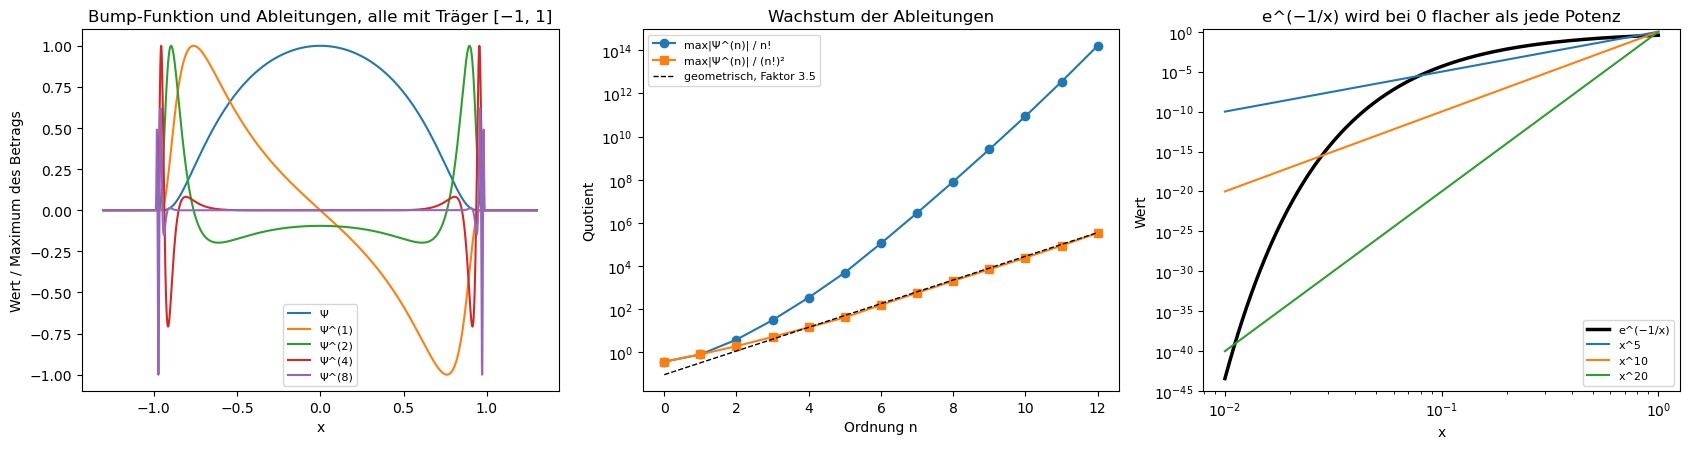

In [2]:
x_sym = sp.symbols("x")
ableitungen = [sp.exp(-1 / (1 - x_sym ** 2))]
for n in range(12):
    ableitungen.append(sp.diff(ableitungen[-1], x_sym))
abl = [sp.lambdify(x_sym, a, "numpy") for a in ableitungen]


def abl_wert(n, x):
    """Ψ^(n)(x), außerhalb von (−1, 1) gleich 0."""
    x = np.atleast_1d(np.asarray(x, dtype=float))
    out = np.zeros_like(x)
    innen = np.abs(x) < 1
    with np.errstate(over="ignore", under="ignore"):
        out[innen] = abl[n](x[innen])
    return out


xs = np.linspace(-0.9995, 0.9995, 40001)
maxima = np.array([np.max(np.abs(abl_wert(n, xs))) for n in range(13)])
fak = np.array([math.factorial(n) for n in range(13)], dtype=float)
print("Ψ^(n)(1 − h) geht gegen 0, aber erst sehr nahe am Rand:")
for n in [1, 2, 4, 8]:
    print(f"  n = {n}: " + "   ".join(f"h = {h}: {abl_wert(n, 1 - h)[0]:9.2e}" for h in [0.05, 0.01, 0.002]))
print(f"Ψ(0.9) = {bump(0.9):.2e} > 0, obwohl jede Taylor-Näherung um x = 1 null ist")
print("max|Ψ^(n)| / n!   für n = 0..12:", " ".join(f"{v:.1e}" for v in maxima / fak))
print("max|Ψ^(n)| / (n!)² für n = 0..12:", " ".join(f"{v:.1e}" for v in maxima / fak ** 2))
C = np.exp(np.polyfit(np.arange(4, 13), np.log(maxima[4:] / fak[4:] ** 2), 1)[0])
print(f"max|Ψ^(n)| / (n!)² wächst geometrisch mit dem Faktor C ≈ {C:.2f} pro Ordnung (Gevrey-Klasse 2)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
xp = np.linspace(-1.3, 1.3, 2001)
for n in [0, 1, 2, 4, 8]:
    axes[0].plot(xp, abl_wert(n, xp) / maxima[n], label="Ψ" if n == 0 else f"Ψ^({n})")
axes[0].set_xlabel("x")
axes[0].set_ylabel("Wert / Maximum des Betrags")
axes[0].set_title("Bump-Funktion und Ableitungen, alle mit Träger [−1, 1]")
axes[0].legend(fontsize=8)
n_ = np.arange(13)
axes[1].semilogy(n_, maxima / fak, "o-", label="max|Ψ^(n)| / n!")
axes[1].semilogy(n_, maxima / fak ** 2, "s-", label="max|Ψ^(n)| / (n!)²")
axes[1].semilogy(n_, maxima[4] / fak[4] ** 2 * C ** (n_ - 4.0), "k--", lw=1, label=f"geometrisch, Faktor {C:.1f}")
axes[1].set_xlabel("Ordnung n")
axes[1].set_ylabel("Quotient")
axes[1].set_title("Wachstum der Ableitungen")
axes[1].legend(fontsize=8)
xx = np.logspace(-2, 0, 400)
axes[2].loglog(xx, f_exp(xx), "k", lw=2.5, label="e^(−1/x)")
for m in [5, 10, 20]:
    axes[2].loglog(xx, xx ** m, label=f"x^{m}")
axes[2].set_ylim(1e-45, 2)
axes[2].set_xlabel("x")
axes[2].set_ylabel("Wert")
axes[2].set_title("e^(−1/x) wird bei 0 flacher als jede Potenz")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt $\Psi$ und die Ableitungen der Ordnungen 1, 2, 4 und 8, jede auf ihr größtes Betragsmaximum normiert. Je höher die Ordnung, desto stärker schwingen sie, und ihre größten Ausschläge wandern zum Rand bei $\pm1$. Außerhalb von $[-1, 1]$ sind alle exakt null.
* Das **mittlere Bild** zeigt, wie die Maxima mit der Ordnung wachsen. Geteilt durch $n!$ (blau) steigt die Kurve immer steiler, schneller als jede geometrische Folge: Die Taylor-Reihe hätte den Konvergenzradius null, $\Psi$ ist nicht analytisch. Geteilt durch $(n!)^2$ (orange) liegt sie auf einer Geraden mit dem Faktor 3.5 pro Ordnung: Gevrey-Klasse 2. Das **rechte Bild** zeigt, warum: $e^{-1/x}$ fällt nahe 0 unter jede Potenz; bei $x = 0.01$ ist es $e^{-100}\approx4\cdot10^{-44}$, kleiner als $x^{20} = 10^{-40}$.
* Die **Ausgabe** zeigt, wie nah man an den Rand muss: $\Psi^{(8)}(0.99) = 1.6\cdot10^7$, aber $\Psi^{(8)}(0.998) = 10^{-68}$. Und $\Psi(0.9) = 5.2\cdot10^{-3}>0$, obwohl jede Taylor-Näherung um $x = 1$ identisch null ist.

##### *2. Bausteine: glatter Übergang, Plateau, Zerlegung der Eins*

Lassen sich aus $e^{-1/x}$ eine glatte Stufe, ein glattes Plateau (1 auf $[-1, 1]$, 0 außerhalb von $(-2, 2)$) und eine Zerlegung der Eins bauen, und summieren sich die Bausteine wirklich exakt zu 1? Vorher vorhersagen: Wie viele $\chi_k$ sind an einer Stelle ungleich null, wenn jeder Baustein den Träger $[k - 0.75, k + 0.75]$ hat?

Aus $f(x) = e^{-1/x}$ entstehen der glatte Übergang $S$, das Plateau $\chi$ und die Zerlegung der Eins aus verschobenen Bump-Funktionen mit Träger der Länge 1.5. Geprüft wird, ob $S$ und $\chi$ außerhalb der Übergänge exakt 0 und 1 sind und ob $\sum_k\chi_k = 1$ gilt.

**Hintergrund & Fachbegriffe:**
- **Glatter Übergang:** $S(x) = f(x)/(f(x) + f(1 - x))$ ist exakt 0 für $x\leq0$, exakt 1 für $x\geq1$ und dazwischen beliebig oft differenzierbar; alle Ableitungen verschwinden an beiden Enden.
- **Plateau (glatte Abschneidefunktion):** gleich 1 auf einem Kern, gleich 0 außerhalb eines größeren Bereichs, glatt dazwischen. Man braucht es, um etwas lokal einzuschalten, ohne Ecken zu erzeugen.
- **Zerlegung der Eins:** glatte Funktionen $\chi_k\geq0$ mit kleinen Trägern, die sich an jeder Stelle zu genau 1 summieren. So setzt man lokal Definiertes zu einem Ganzen zusammen, etwa Integrale auf gekrümmten Flächen aus Karten.

S(0.5) = 0.500; größte Abweichung von S(x) + S(1 − x) = 1: 2.2e-16
S = 0 für alle x ≤ 0: True;  S = 1 für alle x ≥ 1: True
Plateau: genau 1 auf [−1, 1]: True;  genau 0 außerhalb von (−2, 2): True
Zerlegung der Eins auf [−3, 3]: größte Abweichung |Σχ_k − 1| = 2.2e-16; an jeder Stelle 1 bis 2 Terme ungleich 0


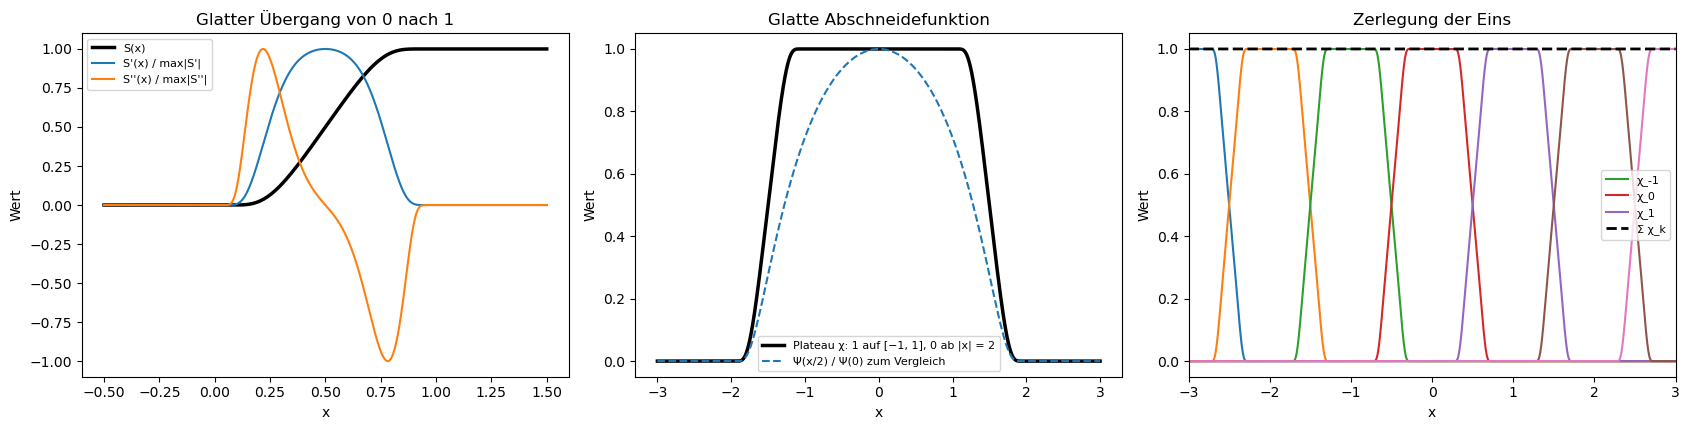

In [3]:
xs = np.linspace(-0.5, 1.5, 8001)
S = glatter_uebergang(xs)
dS = np.gradient(S, xs)
ddS = np.gradient(dS, xs)
print(f"S(0.5) = {glatter_uebergang(0.5):.3f}; größte Abweichung von S(x) + S(1 − x) = 1: "
      f"{np.max(np.abs(S + glatter_uebergang(1 - xs) - 1)):.1e}")
print(f"S = 0 für alle x ≤ 0: {np.all(S[xs <= 0] == 0)};  S = 1 für alle x ≥ 1: {np.all(S[xs >= 1] == 1)}")

xg = np.linspace(-3, 3, 12001)
a_pl, b_pl = 1.0, 2.0
plateau = glatter_uebergang((b_pl - np.abs(xg)) / (b_pl - a_pl))
print(f"Plateau: genau 1 auf [−1, 1]: {np.all(plateau[np.abs(xg) <= a_pl] == 1)};  "
      f"genau 0 außerhalb von (−2, 2): {np.all(plateau[np.abs(xg) >= b_pl] == 0)}")

psi = lambda t: bump(t / 0.75)                          # Träger [−0.75, 0.75], breiter als 1
ks = range(-5, 6)
nenner = sum(psi(xg - j) for j in ks)
chi = {k: psi(xg - k) / nenner for k in ks}
summe = sum(chi.values())
anzahl = sum((c > 0).astype(int) for c in chi.values())
print(f"Zerlegung der Eins auf [−3, 3]: größte Abweichung |Σχ_k − 1| = {np.max(np.abs(summe - 1)):.1e}; "
      f"an jeder Stelle {anzahl.min()} bis {anzahl.max()} Terme ungleich 0")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
axes[0].plot(xs, S, "k", lw=2.5, label="S(x)")
axes[0].plot(xs, dS / np.max(np.abs(dS)), label="S'(x) / max|S'|")
axes[0].plot(xs, ddS / np.max(np.abs(ddS)), label="S''(x) / max|S''|")
axes[0].set_xlabel("x")
axes[0].set_ylabel("Wert")
axes[0].set_title("Glatter Übergang von 0 nach 1")
axes[0].legend(fontsize=8)
axes[1].plot(xg, plateau, "k", lw=2.5, label="Plateau χ: 1 auf [−1, 1], 0 ab |x| = 2")
axes[1].plot(xg, bump(xg / 2) / bump(0), "--", label="Ψ(x/2) / Ψ(0) zum Vergleich")
axes[1].set_xlabel("x")
axes[1].set_ylabel("Wert")
axes[1].set_title("Glatte Abschneidefunktion")
axes[1].legend(fontsize=8)
for k in range(-3, 4):
    axes[2].plot(xg, chi[k], lw=1.5, label=f"χ_{k}" if abs(k) <= 1 else None)
axes[2].plot(xg, summe, "k--", lw=2, label="Σ χ_k")
axes[2].set_xlim(-3, 3)
axes[2].set_xlabel("x")
axes[2].set_ylabel("Wert")
axes[2].set_title("Zerlegung der Eins")
axes[2].legend(fontsize=8, loc="center right")
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt den glatten Übergang $S$ (schwarz) mit seiner ersten (blau) und zweiten Ableitung (orange), beide normiert. $S$ steigt von 0 bei $x = 0$ auf 1 bei $x = 1$; die Ableitungen beginnen und enden flach bei null, deshalb gibt es an den Enden keine Ecken.
* Das **mittlere Bild** zeigt das Plateau $\chi$: exakt 1 auf $[-1, 1]$, exakt 0 ab $\vert x\vert = 2$, mit glatten Flanken. Zum Vergleich ist $\Psi(x/2)/\Psi(0)$ gestrichelt eingezeichnet; sie hat denselben Träger, aber keinen flachen Teil. Das **rechte Bild** zeigt die Bausteine der Zerlegung der Eins um die ganzen Zahlen und ihre Summe (gestrichelt), die überall genau 1 ist.
* Die **Ausgabe** bestätigt: $S(0.5) = 0.5$, $S(x) + S(1 - x) = 1$ bis auf $2\cdot10^{-16}$, $S$ ist für $x\leq0$ exakt 0 und für $x\geq1$ exakt 1, das Plateau ist exakt 1 bzw. 0, und $\sum_k\chi_k$ weicht höchstens um $2\cdot10^{-16}$ von 1 ab. An jeder Stelle sind ein oder zwei Bausteine ungleich null, weil sich benachbarte Träger nur am Rand überlappen.

##### *3. Glätten mit einem Mollifier*

Was macht die Faltung mit $\varphi_\varepsilon$ aus $\vert x\vert$ (Knick), einem Kasten (zwei Sprünge) und einer Weierstraß-artigen Funktion $W(x) = \sum_{k=0}^62^{-k}\cos(3^k\pi x)$, die fast nirgends glatt aussieht? Stimmen die Fehler mit der Schranke $L\varepsilon m_1$ aus Abschnitt 3 der Theorie überein, und wächst der Träger des Kastens nur um $\varepsilon$? Vorher vorhersagen: Wo liegt der größte Fehler für $\vert x\vert$, und wie groß ist er für $\varepsilon = 0.1$?

Die drei Funktionen werden mit $\varphi_\varepsilon$ für sechs Werte von $\varepsilon$ zwischen 0.4 und 0.0125 gefaltet. Gemessen werden der größte Fehler bei $\vert x\vert$, der $L^1$-Fehler beim Kasten und der Träger des geglätteten Kastens.

**Hintergrund & Fachbegriffe:**
- **Faltung:** $(u\ast\varphi_\varepsilon)(x) = \int u(x - y)\varphi_\varepsilon(y)\,dy$, ein gewichteter Mittelwert von $u$ über das Fenster $[x - \varepsilon, x + \varepsilon]$.
- **Mollifier:** eine normierte, symmetrische Testfunktion $\varphi_\varepsilon$ mit Träger $[-\varepsilon, \varepsilon]$. Die Faltung damit ist beliebig glatt, auch wenn $u$ es nicht ist, und ihr Träger wächst nur um $\varepsilon$.
- **Lipschitz-stetig:** $\vert u(x) - u(y)\vert\leq L\vert x - y\vert$; dann ist der Fehler der Glättung höchstens $L\varepsilon m_1$ mit $m_1 = \int\vert z\vert\varphi(z)\,dz$. Bei $\vert x\vert$ ist $L = 1$.
- **$L^1$-Fehler:** $\int\vert u_\varepsilon - u\vert\,dx$, die Fläche zwischen geglätteter und ursprünglicher Funktion; für einen Sprung der Höhe 1 ist er $\varepsilon m_1$, beim Kasten mit zwei Sprüngen $2\varepsilon m_1$.
- **Weierstraß-Funktion:** $\sum a^k\cos(b^k\pi x)$ ist für geeignete $a, b$ stetig, aber nirgends differenzierbar; hier nach sieben Termen abgeschnitten.

m1 = ∫|z| φ(z) dz = 0.33445


ε = 0.4000: max|u_ε − |x|| = 0.13378 bei x = +0.0000 (ε·m1 = 0.13378);  L1-Fehler Kasten 0.26736 (2ε·m1 = 0.26756);  Träger [-1.3996, 1.3996]
ε = 0.2000: max|u_ε − |x|| = 0.06689 bei x = +0.0000 (ε·m1 = 0.06689);  L1-Fehler Kasten 0.13358 (2ε·m1 = 0.13378);  Träger [-1.1998, 1.1998]
ε = 0.1000: max|u_ε − |x|| = 0.03345 bei x = +0.0000 (ε·m1 = 0.03345);  L1-Fehler Kasten 0.06669 (2ε·m1 = 0.06689);  Träger [-1.0998, 1.0998]
ε = 0.0500: max|u_ε − |x|| = 0.01672 bei x = +0.0000 (ε·m1 = 0.01672);  L1-Fehler Kasten 0.03325 (2ε·m1 = 0.03345);  Träger [-1.0498, 1.0498]
ε = 0.0250: max|u_ε − |x|| = 0.00836 bei x = +0.0000 (ε·m1 = 0.00836);  L1-Fehler Kasten 0.01652 (2ε·m1 = 0.01672);  Träger [-1.0248, 1.0248]
ε = 0.0125: max|u_ε − |x|| = 0.00418 bei x = +0.0000 (ε·m1 = 0.00418);  L1-Fehler Kasten 0.00816 (2ε·m1 = 0.00836);  Träger [-1.0124, 1.0124]
(Der numerische Träger ist etwas kleiner als [−1 − ε, 1 + ε], weil e^(−1/(1−z²)) nahe |z| = 1 unter die kleinste darstellbare Zahl fällt.)


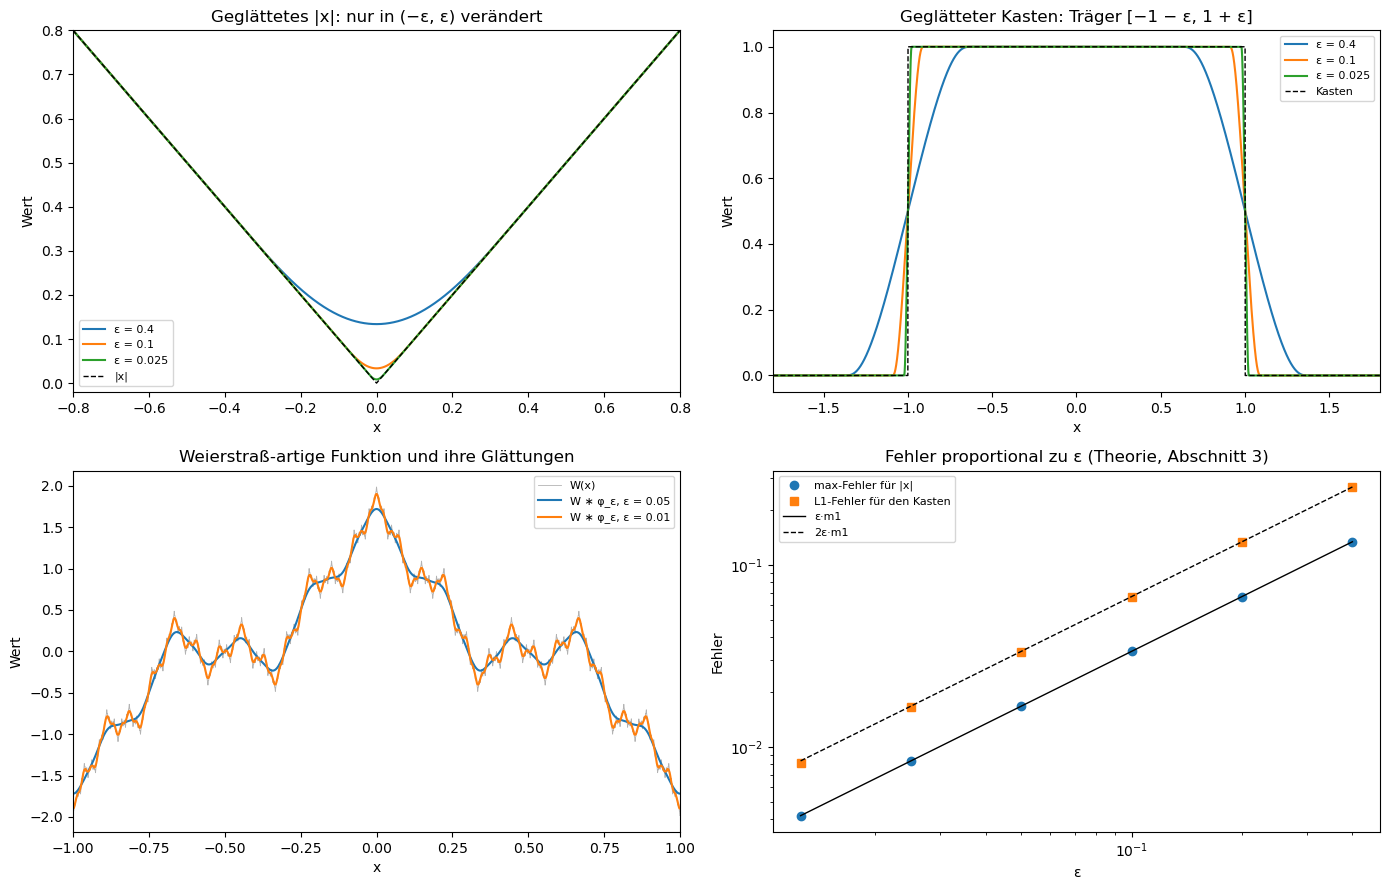

In [4]:
x = np.linspace(-3, 3, 30001)
dx = x[1] - x[0]
m1 = quad(lambda z: abs(z) * math.exp(-1 / (1 - z * z)), -1, 1, epsabs=1e-14)[0] / PSI_INTEGRAL
print(f"m1 = ∫|z| φ(z) dz = {m1:.5f}")
betrag = np.abs(x)
kasten = np.where(np.abs(x) < 1, 1.0, 0.0) + 0.5 * np.isclose(np.abs(x), 1)      # Mittelwert am Sprung
weier = sum(0.5 ** k * np.cos(3 ** k * np.pi * x) for k in range(7))
innen = np.abs(x) < 2                                    # fern vom Gitterrand
epsilons = [0.4, 0.2, 0.1, 0.05, 0.025, 0.0125]
fehler_betrag, fehler_kasten = [], []
for eps in epsilons:
    gb = glaetten(betrag, x, eps)
    gk = glaetten(kasten, x, eps)
    fehler_betrag.append(np.max(np.abs(gb - betrag)[innen]))
    fehler_kasten.append(np.sum(np.abs(gk - kasten)[innen]) * dx)
    ort = x[innen][np.argmax(np.abs(gb - betrag)[innen])]
    traeger = x[gk > 0]
    print(f"ε = {eps:6.4f}: max|u_ε − |x|| = {fehler_betrag[-1]:.5f} bei x = {ort:+.4f} (ε·m1 = {eps * m1:.5f});  "
          f"L1-Fehler Kasten {fehler_kasten[-1]:.5f} (2ε·m1 = {2 * eps * m1:.5f});  Träger [{traeger.min():.4f}, {traeger.max():.4f}]")
print("(Der numerische Träger ist etwas kleiner als [−1 − ε, 1 + ε], weil e^(−1/(1−z²)) nahe |z| = 1 unter die kleinste "
      "darstellbare Zahl fällt.)")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for eps in [0.4, 0.1, 0.025]:
    axes[0, 0].plot(x, glaetten(betrag, x, eps), label=f"ε = {eps}")
    axes[0, 1].plot(x, glaetten(kasten, x, eps), label=f"ε = {eps}")
axes[0, 0].plot(x, betrag, "k--", lw=1, label="|x|")
axes[0, 0].set_xlim(-0.8, 0.8)
axes[0, 0].set_ylim(-0.02, 0.8)
axes[0, 0].set_xlabel("x")
axes[0, 0].set_ylabel("Wert")
axes[0, 0].set_title("Geglättetes |x|: nur in (−ε, ε) verändert")
axes[0, 0].legend(fontsize=8)
axes[0, 1].plot(x, kasten, "k--", lw=1, label="Kasten")
axes[0, 1].set_xlim(-1.8, 1.8)
axes[0, 1].set_xlabel("x")
axes[0, 1].set_ylabel("Wert")
axes[0, 1].set_title("Geglätteter Kasten: Träger [−1 − ε, 1 + ε]")
axes[0, 1].legend(fontsize=8)
axes[1, 0].plot(x, weier, color="0.7", lw=0.6, label="W(x)")
for eps in [0.05, 0.01]:
    axes[1, 0].plot(x, glaetten(weier, x, eps), label=f"W ∗ φ_ε, ε = {eps}")
axes[1, 0].set_xlim(-1, 1)
axes[1, 0].set_xlabel("x")
axes[1, 0].set_ylabel("Wert")
axes[1, 0].set_title("Weierstraß-artige Funktion und ihre Glättungen")
axes[1, 0].legend(fontsize=8)
e_ = np.array(epsilons)
axes[1, 1].loglog(e_, fehler_betrag, "o", label="max-Fehler für |x|")
axes[1, 1].loglog(e_, fehler_kasten, "s", label="L1-Fehler für den Kasten")
axes[1, 1].loglog(e_, m1 * e_, "k-", lw=1, label="ε·m1")
axes[1, 1].loglog(e_, 2 * m1 * e_, "k--", lw=1, label="2ε·m1")
axes[1, 1].set_xlabel("ε")
axes[1, 1].set_ylabel("Fehler")
axes[1, 1].set_title("Fehler proportional zu ε (Theorie, Abschnitt 3)")
axes[1, 1].legend(fontsize=8)
plt.tight_layout()
plt.show()

* **Oben links** ist $\vert x\vert$ mit drei Werten von $\varepsilon$ geglättet: Nur im Fenster $(-\varepsilon, \varepsilon)$ um den Knick wird die Kurve abgerundet, außerhalb bleibt sie exakt gleich, weil ein symmetrischer Kern lineare Funktionen nicht ändert. **Oben rechts** wird der Kasten geglättet: Die Sprünge werden zu glatten Flanken der Breite $2\varepsilon$, und der Träger wächst auf $[-1 - \varepsilon, 1 + \varepsilon]$.
* **Unten links** steht die Weierstraß-artige Funktion (grau, zackig) mit zwei Glättungen: $\varepsilon = 0.05$ (blau) bügelt die feinen Zacken weg, $\varepsilon = 0.01$ (orange) behält mehr davon. **Unten rechts** liegen beide Fehler auf ihren Geraden: der größte Fehler bei $\vert x\vert$ auf $\varepsilon m_1$, der $L^1$-Fehler des Kastens auf $2\varepsilon m_1$. Der Fehler fällt also linear mit $\varepsilon$.
* In der **Ausgabe**: $m_1 = 0.33445$. Der größte Fehler bei $\vert x\vert$ liegt immer bei $x = 0$ und ist auf fünf Stellen $\varepsilon m_1$ (bei $\varepsilon = 0.1$ genau $0.03345$). Der $L^1$-Fehler des Kastens liegt um eine Gitterweite unter $2\varepsilon m_1$. Der gemessene Träger ist etwas kleiner als $[-1 - \varepsilon, 1 + \varepsilon]$ (bei $\varepsilon = 0.1$: $\pm1.0998$), weil der Kern nahe seinem Rand unter die kleinste darstellbare Zahl fällt.

##### *4. Distributionen: schwache Ableitungen, $\delta$ als Grenzwert, Sokhotski–Plemelj*

Ergeben $-\int H\varphi'$, $-\int\vert x\vert\varphi'$ und $-\int\mathrm{sign}(x)\,\varphi'$ für zufällige, nicht symmetrische Testfunktionen wirklich $\varphi(0)$, $\int\mathrm{sign}(x)\,\varphi$ und $2\varphi(0)$? Wie schnell geht $\langle\varphi_\varepsilon, g\rangle\to g(0)$, was passiert mit der Norm $\Vert\varphi_\varepsilon\Vert_2$, und wohin gehen Real- und Imaginärteil von $\int\varphi(x)/(x + i\varepsilon)\,dx$? Vorher vorhersagen: Gegen welchen Wert geht der Imaginärteil?

Die Testfunktionen sind Bump-Funktionen mit zufälligem Mittelpunkt und Radius, mal einem zufälligen Polynom, damit sie nicht symmetrisch sind. Für $\langle\varphi_\varepsilon, g\rangle$ wird $g = \cos x + x^3$ genommen, für Sokhotski–Plemelj werden Werte von $\varepsilon$ zwischen 1 und $10^{-4}$ durchlaufen.

**Hintergrund & Fachbegriffe:**
- **Distribution:** eine Vorschrift, die jeder Testfunktion $\varphi$ linear und stetig eine Zahl zuordnet. Jede gewöhnliche Funktion $u$ ist eine, über $\int u\varphi\,dx$; die Delta-Distribution $\delta$ ordnet $\varphi$ den Wert $\varphi(0)$ zu.
- **Schwache Ableitung:** $\langle T',\varphi\rangle = -\langle T,\varphi'\rangle$, die partielle Integration als Definition. Damit hat jede Distribution Ableitungen: Die Ableitung der **Heaviside-Funktion** $H$ (0 links, 1 rechts) ist $\delta$, die von $\vert x\vert$ ist das Vorzeichen $\mathrm{sign}\,x$, und $\mathrm{sign}' = 2\delta$.
- **Konvergenz gegen $\delta$:** $\varphi_\varepsilon\to\delta$ heißt $\langle\varphi_\varepsilon, g\rangle\to g(0)$ für jedes glatte $g$; die Norm $\Vert\varphi_\varepsilon\Vert_2$ wächst dabei über alle Grenzen.
- **Hauptwert und Sokhotski–Plemelj:** $\mathrm P\frac1x$ integriert $1/x$ symmetrisch um die Polstelle herum. Die Formel $\frac1{x + i0} = \mathrm P\frac1x - i\pi\delta$ trennt den Grenzwert in Hauptwert und Delta-Anteil.

                      −∫Hφ'        φ(0)      −∫|x|φ'    ∫sign·φ    −∫sign·φ'     2φ(0)
c = -0.32, r = 1.57:   0.3521254  0.3521254   -0.1964402 -0.1964402    0.7042508  0.7042508
c = -0.15, r = 1.75:   0.3653382  0.3653382    0.3531796  0.3531796    0.7306765  0.7306765
c = +0.15, r = 1.16:   0.3614190  0.3614190    0.3575350  0.3575350    0.7228380  0.7228380
c = +0.14, r = 1.70:   0.3655311  0.3655311    0.1897230  0.1897230    0.7310621  0.7310621

⟨φ_ε, g⟩ − g(0) mit g = cos x + x³ (Vorhersage −ε²m2/2, m2 = 0.15811):
  ε =  0.50: -1.963e-02   Vorhersage -1.976e-02   Norm ‖φ_ε‖₂ =   1.162
  ε =  0.20: -3.159e-03   Vorhersage -3.162e-03   Norm ‖φ_ε‖₂ =   1.837
  ε =  0.10: -7.903e-04   Vorhersage -7.906e-04   Norm ‖φ_ε‖₂ =   2.598
  ε =  0.05: -1.976e-04   Vorhersage -1.976e-04   Norm ‖φ_ε‖₂ =   3.675
  ε =  0.02: -3.162e-05   Vorhersage -3.162e-05   Norm ‖φ_ε‖₂ =   5.810
  ε =  0.01: -7.906e-06   Vorhersage -7.906e-06   Norm ‖φ_ε‖₂ =   8.217

Sokhotski–Plemelj für die erste Testfunk

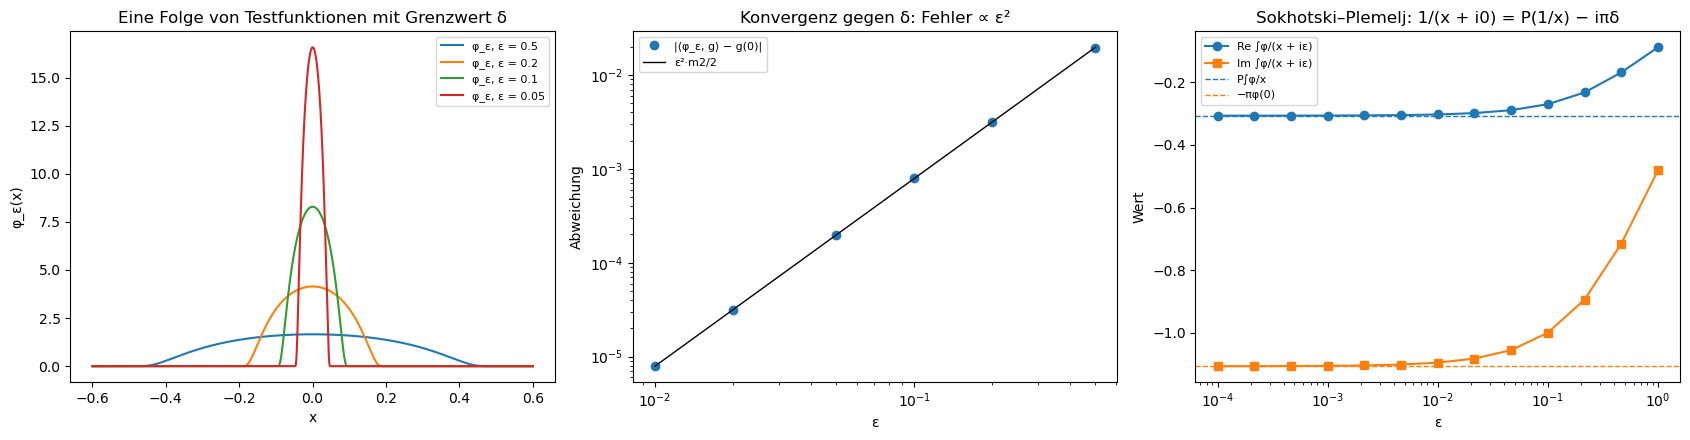

In [5]:
xv, cv, rv, av, bv = sp.symbols("x c r a b", real=True)
phi_sym = sp.exp(-1 / (1 - ((xv - cv) / rv) ** 2)) * (1 + av * xv + bv * xv ** 2)
phi_np = sp.lambdify((xv, cv, rv, av, bv), phi_sym, "math")
dphi_np = sp.lambdify((xv, cv, rv, av, bv), sp.diff(phi_sym, xv), "math")


def testfunktion(c, r, a, b):
    """Ψ((x − c)/r)·(1 + a x + b x²) und ihre Ableitung, außerhalb des Trägers 0 (skalare Funktionen für quad)."""
    phi = lambda x: phi_np(x, c, r, a, b) if abs(x - c) < r else 0.0
    dphi = lambda x: dphi_np(x, c, r, a, b) if abs(x - c) < r else 0.0
    return phi, dphi


opt = dict(points=[0.0], limit=200, epsabs=1e-13, epsrel=1e-12)
print("                      −∫Hφ'        φ(0)      −∫|x|φ'    ∫sign·φ    −∫sign·φ'     2φ(0)")
tests = []
for _ in range(4):
    c, r, a, b = rng.uniform(-0.5, 0.5), rng.uniform(0.8, 2.0), rng.uniform(-1, 1), rng.uniform(-1, 1)
    phi, dphi = testfunktion(c, r, a, b)
    tests.append((c, r, phi))
    lo, hi = c - r, c + r
    w1 = -quad(lambda x: (x > 0) * dphi(x), lo, hi, **opt)[0]
    w2 = -quad(lambda x: abs(x) * dphi(x), lo, hi, **opt)[0]
    w3 = quad(lambda x: np.sign(x) * phi(x), lo, hi, **opt)[0]
    w4 = -quad(lambda x: np.sign(x) * dphi(x), lo, hi, **opt)[0]
    print(f"c = {c:+.2f}, r = {r:.2f}:  {w1:10.7f} {phi(0.0):10.7f}   {w2:10.7f} {w3:10.7f}   {w4:10.7f} {2 * phi(0.0):10.7f}")

m2 = quad(lambda z: z * z * math.exp(-1 / (1 - z * z)), -1, 1, epsabs=1e-14)[0] / PSI_INTEGRAL
norm_phi = math.sqrt(quad(lambda z: (math.exp(-1 / (1 - z * z)) / PSI_INTEGRAL) ** 2, -1, 1)[0])
g = lambda x: math.cos(x) + x ** 3                      # g(0) = 1, g''(0) = −1
eps_liste = np.array([0.5, 0.2, 0.1, 0.05, 0.02, 0.01])
delta_fehler = np.array([quad(lambda x: float(phi_eps(x, e)) * g(x), -e, e, epsabs=1e-15, epsrel=1e-13)[0] - 1
                         for e in eps_liste])
print(f"\n⟨φ_ε, g⟩ − g(0) mit g = cos x + x³ (Vorhersage −ε²m2/2, m2 = {m2:.5f}):")
for e, d in zip(eps_liste, delta_fehler):
    print(f"  ε = {e:5.2f}: {d:+.3e}   Vorhersage {-e * e * m2 / 2:+.3e}   Norm ‖φ_ε‖₂ = {norm_phi / math.sqrt(e):7.3f}")

c, r, phi = tests[0]
hauptwert = quad(phi, c - r, c + r, weight="cauchy", wvar=0.0)[0]
eps_sp = np.logspace(0, -4, 13)
re_sp = np.array([quad(lambda x: phi(x) * x / (x * x + e * e), c - r, c + r, points=[0.0], limit=400)[0] for e in eps_sp])
im_sp = np.array([-quad(lambda x: phi(x) * e / (x * x + e * e), c - r, c + r, points=[0.0], limit=400)[0] for e in eps_sp])
print(f"\nSokhotski–Plemelj für die erste Testfunktion: Re → P∫φ/x = {hauptwert:.6f}, Im → −πφ(0) = {-np.pi * phi(0.0):.6f}")
print(f"  bei ε = 1e−4: Re = {re_sp[-1]:.6f}, Im = {im_sp[-1]:.6f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
xp = np.linspace(-0.6, 0.6, 2001)
for e in [0.5, 0.2, 0.1, 0.05]:
    axes[0].plot(xp, phi_eps(xp, e), label=f"φ_ε, ε = {e}")
axes[0].set_xlabel("x")
axes[0].set_ylabel("φ_ε(x)")
axes[0].set_title("Eine Folge von Testfunktionen mit Grenzwert δ")
axes[0].legend(fontsize=8)
axes[1].loglog(eps_liste, np.abs(delta_fehler), "o", label="|⟨φ_ε, g⟩ − g(0)|")
axes[1].loglog(eps_liste, eps_liste ** 2 * m2 / 2, "k-", lw=1, label="ε²·m2/2")
axes[1].set_xlabel("ε")
axes[1].set_ylabel("Abweichung")
axes[1].set_title("Konvergenz gegen δ: Fehler ∝ ε²")
axes[1].legend(fontsize=8)
axes[2].semilogx(eps_sp, re_sp, "o-", label="Re ∫φ/(x + iε)")
axes[2].semilogx(eps_sp, im_sp, "s-", label="Im ∫φ/(x + iε)")
axes[2].axhline(hauptwert, color="C0", ls="--", lw=1, label="P∫φ/x")
axes[2].axhline(-np.pi * phi(0.0), color="C1", ls="--", lw=1, label="−πφ(0)")
axes[2].set_xlabel("ε")
axes[2].set_ylabel("Wert")
axes[2].set_title("Sokhotski–Plemelj: 1/(x + i0) = P(1/x) − iπδ")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

* Die **Tabelle** in der Ausgabe zeigt für vier zufällige Testfunktionen: $-\int H\varphi' = \varphi(0)$, $-\int\vert x\vert\varphi' = \int\mathrm{sign}\,\varphi$ und $-\int\mathrm{sign}\,\varphi' = 2\varphi(0)$, jeweils auf sieben Stellen gleich. Die schwachen Ableitungen sind also wirklich $\delta$, $\mathrm{sign}$ und $2\delta$.
* Das **linke Bild** zeigt $\varphi_\varepsilon$ für $\varepsilon = 0.5$ bis $0.05$: immer schmaler und höher, die Fläche bleibt 1. Das **mittlere Bild** zeigt den Abstand $\vert\langle\varphi_\varepsilon, g\rangle - g(0)\vert$ auf der Geraden $\varepsilon^2m_2/2$ mit $m_2 = 0.158$: Er fällt quadratisch in $\varepsilon$. Gleichzeitig wächst die Norm $\Vert\varphi_\varepsilon\Vert_2$ von $1.16$ bei $\varepsilon = 0.5$ auf $8.2$ bei $\varepsilon = 0.01$.
* Das **rechte Bild** zeigt Real- und Imaginärteil von $\int\varphi/(x + i\varepsilon)$ gegen $\varepsilon$. Für kleine $\varepsilon$ laufen sie auf die gestrichelten Grenzwerte: den Hauptwert $\mathrm P\int\varphi/x = -0.3068$ und $-\pi\varphi(0) = -1.1062$. Bei $\varepsilon = 10^{-4}$ fehlen noch $4\cdot10^{-5}$ und $1\cdot10^{-4}$, Abweichungen der Ordnung $\varepsilon$.

##### *5. Eine schwache Lösung der Wellengleichung*

Die Dreieckswelle $u(x, t) = F(x - t)$ mit $F(\xi) = \max(0, 1 - \vert\xi\vert)$ hat Knicke und ist dort nicht zweimal differenzierbar. Ist sie trotzdem eine Lösung von $u_{tt} = u_{xx}$ im schwachen Sinn, also $\iint u\,(\varphi_{tt} - \varphi_{xx})\,dx\,dt = 0$ für jede Testfunktion $\varphi(x, t)$? Und was ergibt dieselbe Rechnung für die falsche Geschwindigkeit, $u = F(x - 2t)$? Vorher den Wert für $c = 2$ aus Abschnitt 5 der Theorie vorhersagen: Hängt er nur von $\varphi$ entlang dreier Geraden ab?

Als Testfunktionen dienen Bump-Funktionen in der $(x, t)$-Ebene mit zufälligem Mittelpunkt und Radius, fünf für $c = 1$ und fünf für $c = 2$. Das Integral wird auf einem Gitter mit $1601\times1601$ Punkten berechnet und mit der Vorhersage $(c^2 - 1)\int[\varphi(ct - 1, t) - 2\varphi(ct, t) + \varphi(ct + 1, t)]\,dt$ verglichen.

**Hintergrund & Fachbegriffe:**
- **Wellengleichung und d'Alembert-Operator:** $\square u = u_{tt} - u_{xx} = 0$ beschreibt Wellen mit Geschwindigkeit 1. Jede Form $F(x - t)$, die nach rechts läuft, ist eine Lösung, wenn $F$ zweimal differenzierbar ist.
- **Schwache Lösung:** Statt $\square u = 0$ an jedem Punkt verlangt man $\iint u\,\square\varphi\,dx\,dt = 0$ für jede Testfunktion. Die Ableitungen sind auf $\varphi$ verschoben; $u$ darf Knicke und Sprünge haben, wie Stoßwellen in Gasen.
- **Testfunktion in Raum und Zeit:** eine glatte Funktion $\varphi(x, t)$, die außerhalb eines Kreises in der $(x, t)$-Ebene null ist.
- **Lichtkegelkoordinaten:** $\xi = x - t$ und $\eta = x + t$; in ihnen ist $\square = -4\partial_\xi\partial_\eta$, und Wellen $F(\xi)$ hängen nur von einer der beiden ab.

c = 1: φ um (+0.68, 0.95), r = 1.04:  ⟨u, □φ⟩ = +2.654e-16   Vorhersage +0.000e+00   (Größe ∫|u □φ| = 0.943)
c = 1: φ um (+0.64, 0.73), r = 1.17:  ⟨u, □φ⟩ = +1.138e-17   Vorhersage +0.000e+00   (Größe ∫|u □φ| = 0.667)
c = 1: φ um (+1.10, 1.16), r = 0.81:  ⟨u, □φ⟩ = +1.655e-16   Vorhersage +0.000e+00   (Größe ∫|u □φ| = 1.283)


c = 1: φ um (+0.98, 0.87), r = 0.94:  ⟨u, □φ⟩ = -3.100e-16   Vorhersage +0.000e+00   (Größe ∫|u □φ| = 1.013)
c = 1: φ um (+0.59, 0.94), r = 1.01:  ⟨u, □φ⟩ = -1.987e-16   Vorhersage +0.000e+00   (Größe ∫|u □φ| = 1.059)
c = 2: φ um (+2.88, 1.37), r = 1.36:  ⟨u, □φ⟩ = -3.058e-01   Vorhersage -3.058e-01   (Größe ∫|u □φ| = 0.421)


c = 2: φ um (+1.77, 0.85), r = 1.46:  ⟨u, □φ⟩ = -2.847e-01   Vorhersage -2.847e-01   (Größe ∫|u □φ| = 0.390)
c = 2: φ um (+1.65, 0.93), r = 1.43:  ⟨u, □φ⟩ = -2.901e-01   Vorhersage -2.901e-01   (Größe ∫|u □φ| = 0.400)
c = 2: φ um (+2.11, 1.20), r = 1.02:  ⟨u, □φ⟩ = -3.953e-01   Vorhersage -3.953e-01   (Größe ∫|u □φ| = 0.586)


c = 2: φ um (+2.39, 1.20), r = 0.96:  ⟨u, □φ⟩ = -4.267e-01   Vorhersage -4.267e-01   (Größe ∫|u □φ| = 0.607)


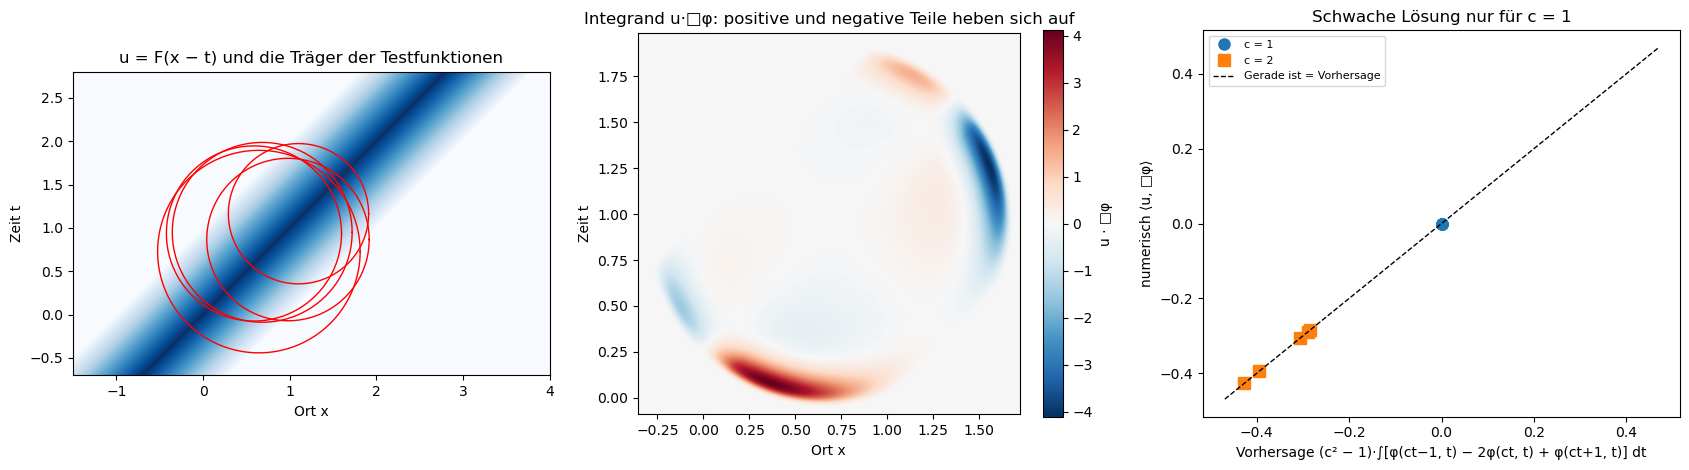

In [6]:
xx_, tt_, x0_, t0_, r_ = sp.symbols("x t x0 t0 r", real=True)
phi2 = sp.exp(-1 / (1 - ((xx_ - x0_) ** 2 + (tt_ - t0_) ** 2) / r_ ** 2))        # Bump-Funktion in (x, t)
box_phi = sp.lambdify((xx_, tt_, x0_, t0_, r_), sp.diff(phi2, tt_, 2) - sp.diff(phi2, xx_, 2), "numpy")
F_dreieck = lambda xi: np.maximum(0.0, 1 - np.abs(xi))


def bump2(X, T, x0, t0, r):
    rho2 = ((X - x0) ** 2 + (T - t0) ** 2) / r ** 2
    return np.where(rho2 < 1, np.exp(-1 / np.where(rho2 < 1, 1 - rho2, 1.0)), 0.0)


def schwacher_test(c, x0, t0, r, n=1601):
    """⟨u, □φ⟩ für u = F(x − ct) und die Bump-Funktion um (x0, t0) mit Radius r, dazu die Vorhersage aus der Theorie (Abschnitt 5)."""
    gx, gt = np.linspace(x0 - r, x0 + r, n), np.linspace(t0 - r, t0 + r, n)
    X, T = np.meshgrid(gx, gt, indexing="ij")
    B = np.zeros_like(X)
    m = ((X - x0) ** 2 + (T - t0) ** 2) < r ** 2 * (1 - 1e-3)
    with np.errstate(all="ignore"):
        B[m] = box_phi(X[m], T[m], x0, t0, r)
    integrand = F_dreieck(X - c * T) * B
    h = (gx[1] - gx[0]) * (gt[1] - gt[0])
    ts = np.linspace(t0 - r, t0 + r, 20001)
    linien = bump2(c * ts - 1, ts, x0, t0, r) - 2 * bump2(c * ts, ts, x0, t0, r) + bump2(c * ts + 1, ts, x0, t0, r)
    return np.sum(integrand) * h, (c ** 2 - 1) * trapezoid(linien, ts), np.sum(np.abs(integrand)) * h, (X, T, integrand)


ergebnisse = {1.0: [], 2.0: []}
for c in [1.0, 2.0]:
    for _ in range(5):
        t0, r = rng.uniform(0.5, 1.5), rng.uniform(0.8, 1.5)
        x0 = c * t0 + rng.uniform(-0.6, 0.6)
        wert, vorhersage, skala, bild = schwacher_test(c, x0, t0, r)
        vorhersage += 0.0                                   # −0.0 als +0.0 anzeigen
        ergebnisse[c].append((x0, t0, r, wert, vorhersage, skala, bild))
        print(f"c = {c:.0f}: φ um ({x0:+.2f}, {t0:.2f}), r = {r:.2f}:  ⟨u, □φ⟩ = {wert:+.3e}   Vorhersage {vorhersage:+.3e}   "
              f"(Größe ∫|u □φ| = {skala:.3f})")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
gx, gt = np.linspace(-1.5, 4.0, 550), np.linspace(-0.7, 2.8, 350)
X, T = np.meshgrid(gx, gt)
axes[0].imshow(F_dreieck(X - T), extent=[gx[0], gx[-1], gt[0], gt[-1]], origin="lower", aspect="equal", cmap="Blues")
kreis = np.linspace(0, 2 * np.pi, 200)
for x0, t0, r, *_ in ergebnisse[1.0]:
    axes[0].plot(x0 + r * np.cos(kreis), t0 + r * np.sin(kreis), "r", lw=1)
axes[0].set_xlabel("Ort x")
axes[0].set_ylabel("Zeit t")
axes[0].set_title("u = F(x − t) und die Träger der Testfunktionen")
Xb, Tb, integrand = ergebnisse[1.0][0][6]
grenze = np.max(np.abs(integrand))
bild = axes[1].imshow(integrand.T, extent=[Xb.min(), Xb.max(), Tb.min(), Tb.max()], origin="lower", aspect="auto",
                      cmap="RdBu_r", vmin=-grenze, vmax=grenze)
axes[1].set_aspect("equal")
plt.colorbar(bild, ax=axes[1], label="u · □φ")
axes[1].set_xlabel("Ort x")
axes[1].set_ylabel("Zeit t")
axes[1].set_title("Integrand u·□φ: positive und negative Teile heben sich auf")
for c, marker in [(1.0, "o"), (2.0, "s")]:
    vor = [e[4] for e in ergebnisse[c]]
    ist = [e[3] for e in ergebnisse[c]]
    axes[2].plot(vor, ist, marker, ms=8, label=f"c = {c:.0f}")
lim = 1.1 * max(abs(e[4]) for e in ergebnisse[2.0])
axes[2].plot([-lim, lim], [-lim, lim], "k--", lw=1, label="Gerade ist = Vorhersage")
axes[2].set_xlabel("Vorhersage (c² − 1)·∫[φ(ct−1, t) − 2φ(ct, t) + φ(ct+1, t)] dt")
axes[2].set_ylabel("numerisch ⟨u, □φ⟩")
axes[2].set_title("Schwache Lösung nur für c = 1")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt $u = F(x - t)$ in der $(x, t)$-Ebene: einen blauen Streifen, der mit Geschwindigkeit 1 nach rechts wandert, mit Knicken an den Rändern und in der Mitte. Die roten Kreise sind die Träger der fünf Testfunktionen für $c = 1$; alle überdecken die Knicke.
* Das **mittlere Bild** zeigt den Integranden $u\,\square\varphi$ für eine dieser Testfunktionen: rote und blaue Gebiete, die sich genau aufheben. Das **rechte Bild** vergleicht für alle zehn Testfunktionen den numerischen Wert mit der Vorhersage: Die Punkte für $c = 1$ (blau) liegen bei 0, die für $c = 2$ (orange) auf der Diagonalen.
* In der **Ausgabe** ist für $c = 1$ der Betrag $\vert\langle u, \square\varphi\rangle\vert$ höchstens $3\cdot10^{-16}$, obwohl der Integrand $\int\vert u\,\square\varphi\vert$ die Größe 0.7 bis 1.3 hat: Die Dreieckswelle ist eine schwache Lösung, trotz ihrer Knicke. Für $c = 2$ liegen die Werte zwischen $-0.28$ und $-0.43$ und stimmen auf vier Stellen mit dem Integral entlang der drei Geraden überein: Mit der falschen Geschwindigkeit ist sie keine Lösung.

##### *6. Fourier-Abfall: von $1/k$ bis $e^{-\sqrt k}$*

Wie schnell fallen die Fourier-Transformierten von Rechteck, Dreieck, Hann-Fenster, Bump-Funktion und Gauß-Funktion? Bestätigt die Rechnung die Potenzgesetze $1/k$, $1/k^2$, $1/k^3$ und die Sattelpunkt-Formel $\hat\Psi(k)\approx2\sqrt{2\pi}e^{-1/4}(2k)^{-3/4}e^{-\sqrt k}\cos(k - \sqrt k - 3\pi/8)$ aus Abschnitt 6 der Theorie? Vorher schätzen: Wie viele Größenordnungen liegen bei $k = 400$ zwischen Rechteck und Bump-Funktion?

Für Rechteck, Dreieck und Hann werden die geschlossenen Formeln mit numerischen Integralen verglichen. $\hat\Psi$ wird mit einer FFT auf sehr feinem Gitter ($\Delta x = 10^{-3}$, $2^{21}$ Punkte) bis $k = 700$ berechnet und mit der Sattelpunkt-Formel verglichen.

**Hintergrund & Fachbegriffe:**
- **Fourier-Transformierte:** $\hat\varphi(k) = \int\varphi(x)e^{-ikx}dx$ zerlegt eine Funktion in Schwingungen der Wellenzahl $k$. Wie schnell $\hat\varphi$ für große $k$ fällt, zeigt, wie glatt $\varphi$ ist.
- **Fenster:** Rechteck (Sprung), Dreieck (Knick) und Hann-Fenster $\cos^2(\pi x/2)$ (erst die zweite Ableitung springt) sind die üblichen Gewichte, mit denen man ein Signal ausschneidet. Je glatter das Fenster, desto weniger „Leckeffekt“ in benachbarte Frequenzen.
- **Sattelpunktmethode:** eine Technik, Integrale mit stark schwingendem oder stark abfallendem Integranden asymptotisch auszuwerten: Man verschiebt den Integrationsweg ins Komplexe zu einem Sattelpunkt und nähert dort durch eine Gauß-Funktion.
- **Paley–Wiener:** Funktionen mit kompaktem Träger haben Fourier-Transformierte, die ganze Funktionen sind; sie können nicht wie $e^{-a\vert k\vert}$ fallen. $e^{-\sqrt k}$ ist ein Kompromiss zwischen kompaktem Träger und schnellem Abfall.

Rechteck (Sprung) : geschlossene Formel gegen numerisches Integral, größte Abweichung 2.2e-16
Dreieck (Knick)   : geschlossene Formel gegen numerisches Integral, größte Abweichung 1.1e-16
Hann cos²(πx/2)   : geschlossene Formel gegen numerisches Integral, größte Abweichung 5.2e-17
Gauß e^(−x²)       : bei k = 3 numerisch 0.1868152615, Formel 0.1868152615
Kontrolle: Ψ̂(0) = 0.44399382 = ∫Ψ = 0.44399382

   k    Ψ̂(k) numerisch   Sattelpunkt     Verhältnis   Rechteck-Hülle 2/k
  25.0  +1.4342e-03   +1.3987e-03     1.0254     8.0e-02
  50.0  -6.6517e-05   -6.4251e-05     1.0353     4.0e-02
 100.0  +2.2366e-06   +2.1829e-06     1.0246     2.0e-02
 200.0  -2.4641e-08   -2.4576e-08     1.0026     1.0e-02
 400.0  -1.3566e-11   -1.3776e-11     0.9847     5.0e-03
 700.0  +5.5327e-14   +5.5052e-14     1.0050     2.9e-03


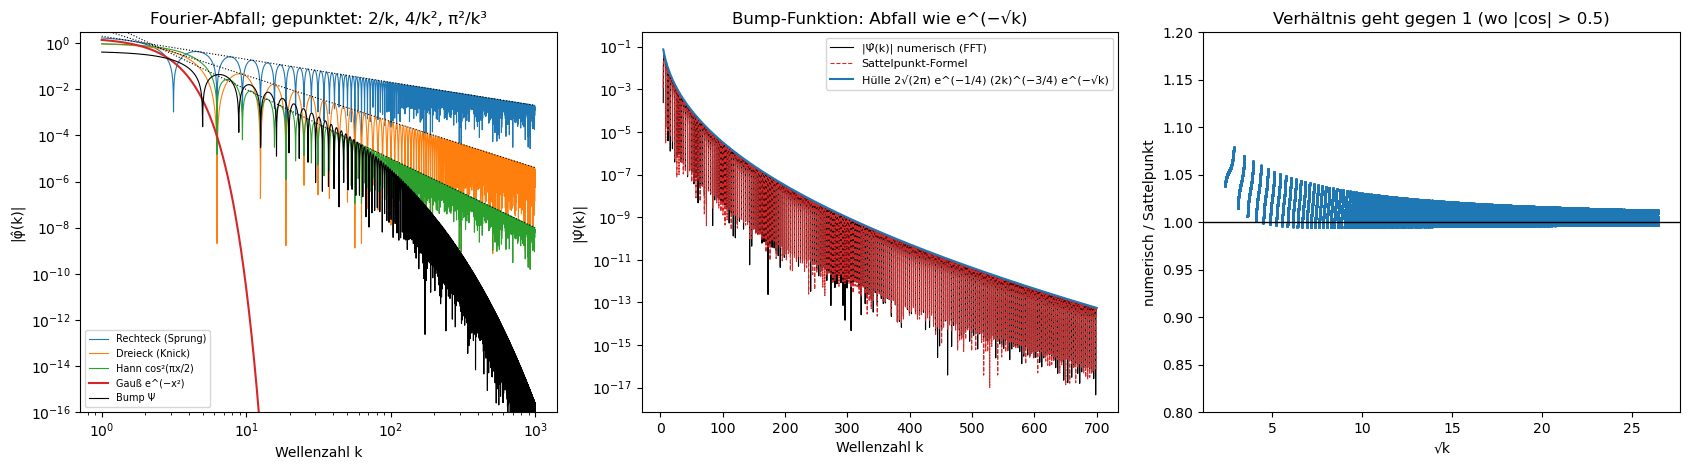

In [7]:
def psi_hat_fft(dx=1e-3, M=2 ** 21):
    """Ψ̂(k) = ∫Ψ(x) e^(−ikx) dx auf dem Gitter k_j = 2πj/(M dx) mit einer FFT; die Trapezregel ist für glatte
    Funktionen mit kompaktem Träger bis auf Rundungsfehler exakt."""
    xs = np.arange(-1, 1 + dx / 2, dx)
    a = np.zeros(M)
    a[:xs.size] = bump(xs)
    k = 2 * np.pi * np.arange(M) / (M * dx)
    return k, (dx * np.exp(1j * k) * np.fft.fft(a)).real       # Phasenfaktor, weil das Gitter bei x = −1 beginnt


def psi_hat_sattel(k):
    k = np.asarray(k, dtype=float)
    return 2 * np.sqrt(2 * np.pi) * np.exp(-0.25) * (2 * k) ** -0.75 * np.exp(-np.sqrt(k)) * np.cos(k - np.sqrt(k) - 3 * np.pi / 8)


formeln = {
    "Rechteck (Sprung)": (lambda k: 2 * np.sin(k) / k, lambda x: 1.0),
    "Dreieck (Knick)": (lambda k: 4 * np.sin(k / 2) ** 2 / k ** 2, lambda x: 1 - abs(x)),
    "Hann cos²(πx/2)": (lambda k: np.pi ** 2 * np.sin(k) / (k * (np.pi ** 2 - k ** 2)), lambda x: math.cos(math.pi * x / 2) ** 2),
}
for name, (F, profil) in formeln.items():
    abw = max(abs(quad(profil, -1, 1, weight="cos", wvar=kk)[0] - F(kk)) for kk in [0.7, 3.7, 25.0, 140.0])
    print(f"{name:18s}: geschlossene Formel gegen numerisches Integral, größte Abweichung {abw:.1e}")
gauss_num = 2 * quad(lambda x: math.exp(-x * x), 0, np.inf, weight="cos", wvar=3.0)[0]
print(f"Gauß e^(−x²)       : bei k = 3 numerisch {gauss_num:.10f}, Formel {np.sqrt(np.pi) * np.exp(-9 / 4):.10f}")

k_fft, Psi_hat = psi_hat_fft()
print(f"Kontrolle: Ψ̂(0) = {Psi_hat[0]:.8f} = ∫Ψ = {PSI_INTEGRAL:.8f}")
print("\n   k    Ψ̂(k) numerisch   Sattelpunkt     Verhältnis   Rechteck-Hülle 2/k")
for kk in [25, 50, 100, 200, 400, 700]:
    j = np.argmin(np.abs(k_fft - kk))
    print(f"{k_fft[j]:6.1f}  {Psi_hat[j]:+.4e}   {psi_hat_sattel(k_fft[j]):+.4e}   {Psi_hat[j] / psi_hat_sattel(k_fft[j]):8.4f}     {2 / k_fft[j]:.1e}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
k = np.logspace(0, 3, 4000)
for name, (F, _) in formeln.items():
    axes[0].loglog(k, np.abs(F(k)), lw=0.8, label=name)
axes[0].loglog(k, np.sqrt(np.pi) * np.exp(-k ** 2 / 4), lw=1.5, label="Gauß e^(−x²)")
m = (k_fft > 1) & (k_fft < 1000)
axes[0].loglog(k_fft[m][::5], np.abs(Psi_hat[m][::5]), "k", lw=0.8, label="Bump Ψ")
for p, s in [(1, 2), (2, 4), (3, np.pi ** 2)]:
    axes[0].loglog(k, s / k ** p, "k:", lw=0.8)
axes[0].set_ylim(1e-16, 3)
axes[0].set_xlabel("Wellenzahl k")
axes[0].set_ylabel("|φ̂(k)|")
axes[0].set_title("Fourier-Abfall; gepunktet: 2/k, 4/k², π²/k³")
axes[0].legend(fontsize=7, loc="lower left")
m = (k_fft > 5) & (k_fft < 700)
axes[1].semilogy(k_fft[m], np.abs(Psi_hat[m]), "k", lw=0.8, label="|Ψ̂(k)| numerisch (FFT)")
axes[1].semilogy(k_fft[m], np.abs(psi_hat_sattel(k_fft[m])), "C3--", lw=0.8, label="Sattelpunkt-Formel")
axes[1].semilogy(k_fft[m], 2 * np.sqrt(2 * np.pi) * np.exp(-0.25) * (2 * k_fft[m]) ** -0.75 * np.exp(-np.sqrt(k_fft[m])),
                 "C0", lw=1.5, label="Hülle 2√(2π) e^(−1/4) (2k)^(−3/4) e^(−√k)")
axes[1].set_xlabel("Wellenzahl k")
axes[1].set_ylabel("|Ψ̂(k)|")
axes[1].set_title("Bump-Funktion: Abfall wie e^(−√k)")
axes[1].legend(fontsize=8)
huelle = 2 * np.sqrt(2 * np.pi) * np.exp(-0.25) * (2 * k_fft[m]) ** -0.75 * np.exp(-np.sqrt(k_fft[m]))
gut = np.abs(np.cos(k_fft[m] - np.sqrt(k_fft[m]) - 3 * np.pi / 8)) > 0.5
axes[2].plot(np.sqrt(k_fft[m][gut]), Psi_hat[m][gut] / psi_hat_sattel(k_fft[m][gut]), ".", ms=2)
axes[2].axhline(1, color="k", lw=1)
axes[2].set_ylim(0.8, 1.2)
axes[2].set_xlabel("√k")
axes[2].set_ylabel("numerisch / Sattelpunkt")
axes[2].set_title("Verhältnis geht gegen 1 (wo |cos| > 0.5)")
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt $\vert\hat\varphi(k)\vert$ doppelt logarithmisch. Rechteck (blau), Dreieck (orange) und Hann (grün) schwingen unter ihren gepunkteten Hüllen $2/k$, $4/k^2$ und $\pi^2/k^3$: drei Geraden mit den Steigungen $-1$, $-2$, $-3$. Die Gauß-Funktion (rot) fällt am schnellsten, wie $e^{-k^2/4}$. Die Bump-Funktion (schwarz) fällt schneller als jede Potenz, ihre Kurve biegt nach unten, aber langsamer als die Gauß-Funktion.
* Das **mittlere Bild** zeigt $\vert\hat\Psi\vert$ bis $k = 700$ mit logarithmischer $y$-Achse: die numerische Kurve (schwarz) und die Sattelpunkt-Formel (rot gestrichelt) schwingen unter der blauen Hülle $\propto(2k)^{-3/4}e^{-\sqrt k}$ und fallen von $10^{-1}$ auf $10^{-14}$. Das **rechte Bild** zeigt das Verhältnis beider (nur wo der Kosinus nicht nahe null ist): Es beginnt bei etwa 1.05 und nähert sich mit wachsendem $k$ der 1.
* In der **Ausgabe** stimmen die drei geschlossenen Formeln auf $2\cdot10^{-16}$ mit den Integralen überein, und $\hat\Psi(0) = \int\Psi = 0.44399$. Die Sattelpunkt-Formel trifft $\hat\Psi$ auf 2.5 % bei $k = 25$, 0.3 % bei $k = 200$ und 0.5 % bei $k = 700$. Bei $k = 400$ ist $\vert\hat\Psi\vert = 1.4\cdot10^{-11}$, acht Größenordnungen unter der Hülle $2/k = 5\cdot10^{-3}$ des Rechtecks.

##### *7. Galerie: zwölf klassische Benchmark-Funktionen*

Wie sehen die zwölf Landschaften aus der Tabelle in Abschnitt 7 der Theorie aus, und stimmen die tabellierten Minima? Für jede Funktion: Wert an der tabellierten Stelle, Betrag des Gradienten dort, und das beste Ergebnis einer Gittersuche mit $801\times801$ Punkten über dem ganzen Suchgebiet mit anschließender lokaler Verfeinerung. Vorher vorhersagen: Bei welcher Funktion liegt das Minimum am Rand des Suchgebiets, sodass der Gradient dort nicht null ist?

Jede Funktion wird als Höhenlinienbild in einem Ausschnitt gezeigt, der ihre Struktur sichtbar macht. Die Farbe ist $\log_{10}(1 + f - f_\text{min})$, damit flache Täler und steile Wände zugleich zu sehen sind; der Stern markiert das tabellierte Minimum. Für Schwefel werden zusätzlich die drei tiefsten Minima einer einzelnen Koordinate bestimmt.

**Hintergrund & Fachbegriffe:**
- **Benchmark-Funktion:** eine Testfunktion der Optimierung mit geschlossener Formel und bekanntem globalem Minimum, an der man Verfahren prüft.
- **Lokales und globales Minimum:** Ein lokales Minimum ist der kleinste Wert in seiner Umgebung, das globale der kleinste überhaupt. Lokale Verfahren finden das nächste lokale Minimum, nicht unbedingt das globale.
- **Modalität und Separierbarkeit:** die Zahl der lokalen Minima; separabel heißt $f(x) = \sum_ig_i(x_i)$, dann kann man jede Koordinate einzeln optimieren.
- **Täuschung:** Die zweitbesten Minima liegen weit vom besten entfernt (Schwefel); ein Verfahren, das gute Gegenden genauer absucht, wird in die Irre geführt.
- **Minimum am Rand:** Liegt das Minimum auf dem Rand des Suchgebiets, ist der Gradient dort nicht null; die Bedingung $\nabla f = 0$ gilt nur für innere Minima.

Funktion           Tabelle f*        f(x*)   |∇f(x*)|  beste Suche   gefunden bei
Booth                 0.00000      0.00000    0.0e+00      0.00000   (1.0000, 3.0000)
Rosenbrock            0.00000      0.00000    6.4e-09      0.00000   (1.0000, 1.0000)
Beale                 0.00000      0.00000    3.1e-09      0.00000   (3.0000, 0.5000)
Himmelblau            0.00000      0.00000    4.2e-05      0.00000   (3.0000, 2.0000)


Six-Hump Camel       -1.03160     -1.03163    9.2e-04     -1.03163   (-0.0898, 0.7127)
Goldstein–Price       3.00000      3.00000    1.3e-08      3.00000   (0.0000, -1.0000)
Styblinski–Tang     -78.33234    -78.33233    1.4e-06    -78.33233   (-2.9035, -2.9035)
Rastrigin             0.00000      0.00000    0.0e+00      0.00000   (0.0000, 0.0000)


Ackley                0.00000      0.00000    0.0e+00      0.00000   (0.0000, 0.0000)
Easom                -1.00000     -1.00000    0.0e+00     -1.00000   (3.1416, 3.1416)
Schwefel              0.00000      0.00003    1.7e-05      0.00003   (420.9687, 420.9687)
Eggholder          -959.64070   -959.64066    3.4e+00   -959.64066   (512.0000, 404.2318)

Schwefel, eine Koordinate: die drei tiefsten lokalen Minima bei x = 420.97 (Wert -418.98), -302.52 (Wert -300.54), 203.81 (Wert -201.84)


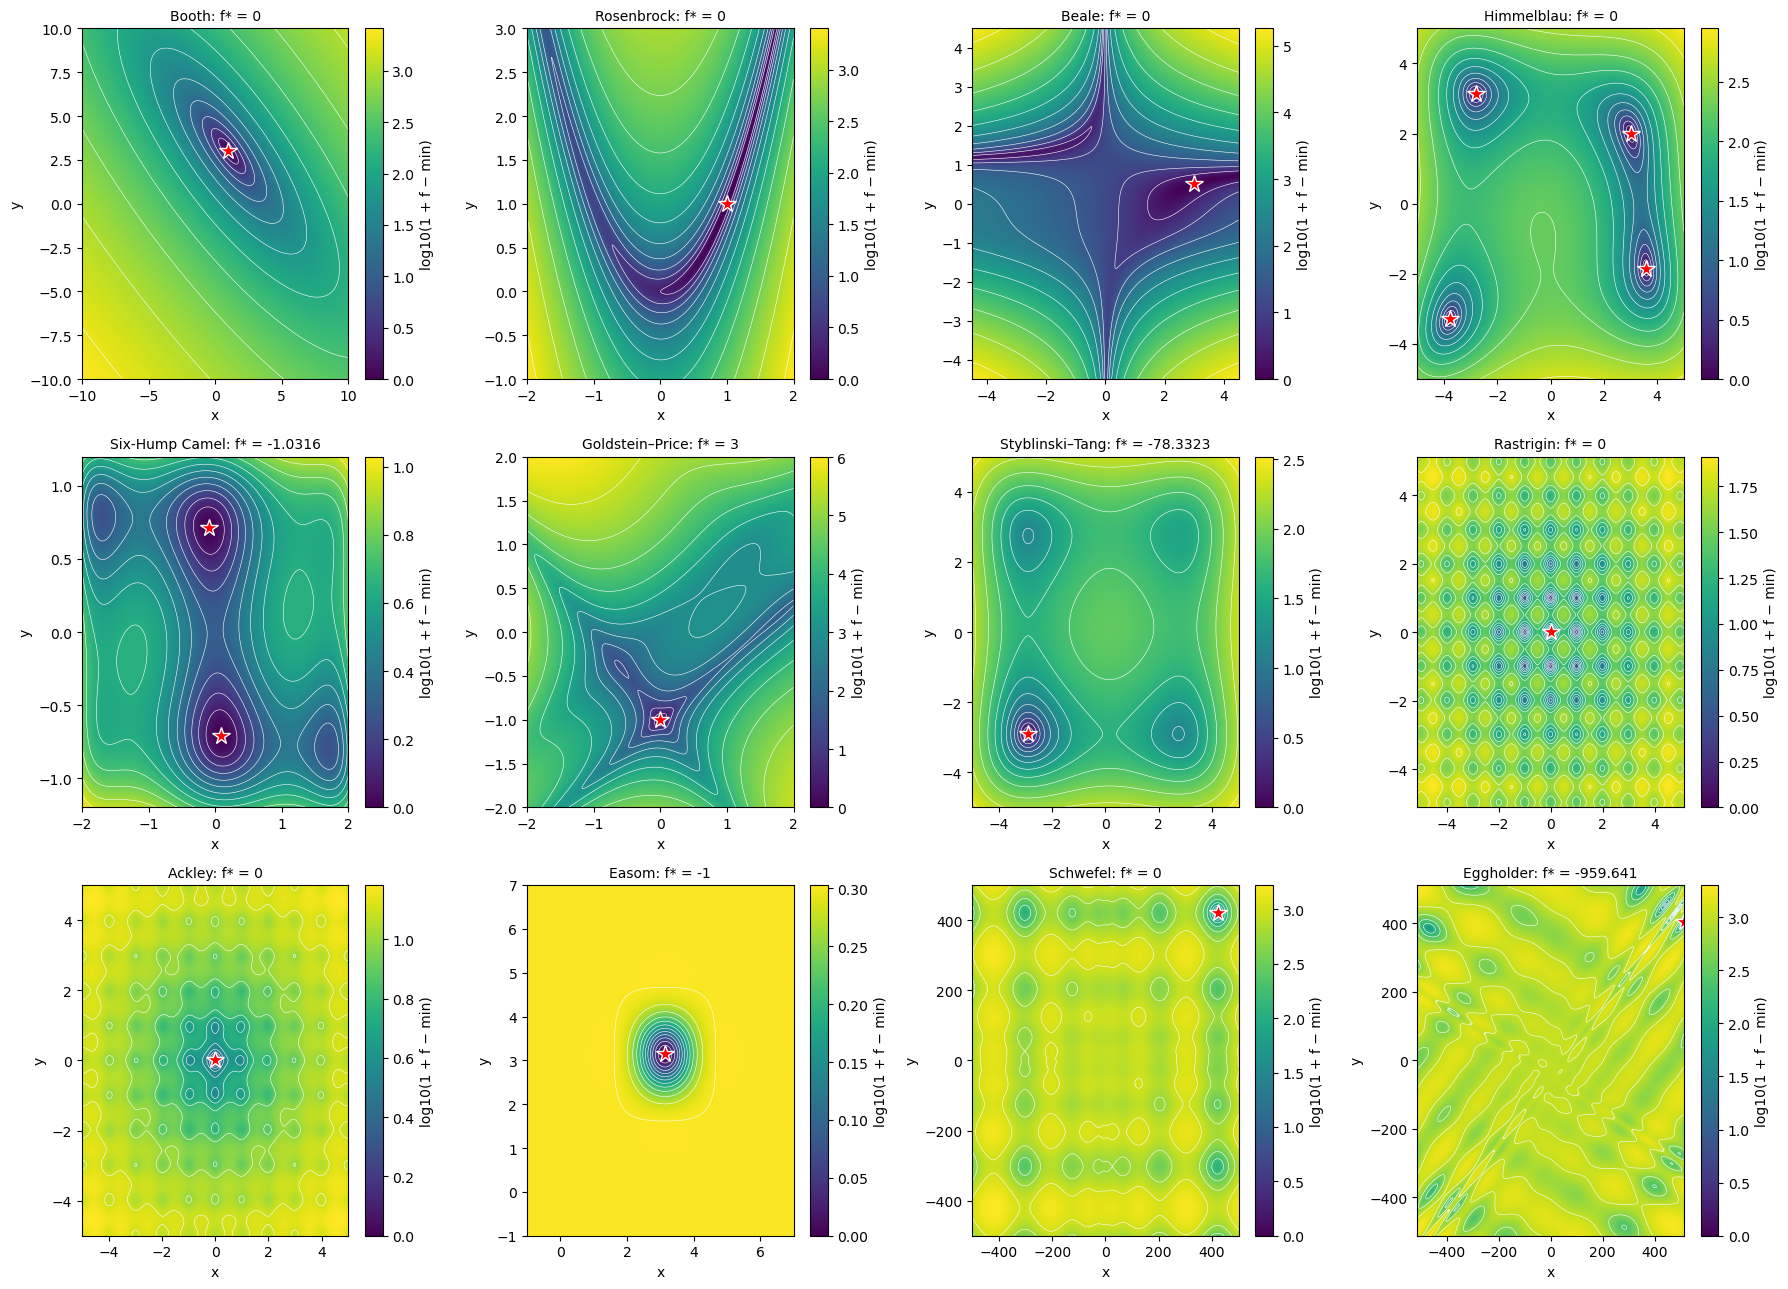

In [8]:
def gradient_num(f, p, h):
    p = np.asarray(p, dtype=float)
    return np.array([(f(p + h * e) - f(p - h * e)) / (2 * h) for e in np.eye(2)])


print(f"{'Funktion':16s} {'Tabelle f*':>12s} {'f(x*)':>12s} {'|∇f(x*)|':>10s} {'beste Suche':>12s}   gefunden bei")
for name, (f, gebiet, _, minima, fmin) in GALERIE.items():
    skala = gebiet[0][1] - gebiet[0][0]
    werte = [f(np.array(p, dtype=float)) for p in minima]
    grad = max(np.linalg.norm(gradient_num(f, p, 1e-6 * skala)) for p in minima)
    gx = np.linspace(*gebiet[0], 801)
    gy = np.linspace(*gebiet[1], 801)
    X, Y = np.meshgrid(gx, gy)
    Z = f(np.array([X, Y]))
    beste = np.argsort(Z.ravel())[:20]
    kandidaten = [minimize(f, [X.ravel()[i], Y.ravel()[i]], method="L-BFGS-B", bounds=gebiet,
                           options=dict(ftol=1e-15, gtol=1e-12)) for i in beste]
    bester = min(kandidaten, key=lambda r: r.fun)
    print(f"{name:16s} {fmin:12.5f} {min(werte):12.5f} {grad:10.1e} {bester.fun:12.5f}   ({bester.x[0]:.4f}, {bester.x[1]:.4f})")

g_schw = lambda t: -t * np.sin(np.sqrt(np.abs(t)))         # Schwefel in einer Koordinate (ohne Konstante)
t = np.linspace(-500, 500, 2000001)
v = g_schw(t)
lokal = np.where((v[1:-1] < v[:-2]) & (v[1:-1] < v[2:]))[0] + 1
reihe = lokal[np.argsort(v[lokal])][:3]
print("\nSchwefel, eine Koordinate: die drei tiefsten lokalen Minima bei x =",
      ", ".join(f"{t[i]:.2f} (Wert {v[i]:.2f})" for i in reihe))

fig, axes = plt.subplots(3, 4, figsize=(18, 13))
for ax, (name, (f, gebiet, bildausschnitt, minima, fmin)) in zip(axes.flat, GALERIE.items()):
    gx = np.linspace(*bildausschnitt[0], 400)
    gy = np.linspace(*bildausschnitt[1], 400)
    X, Y = np.meshgrid(gx, gy)
    Z = f(np.array([X, Y]))
    farbe = np.log10(1 + Z - Z.min())
    bild = ax.imshow(farbe, extent=[gx[0], gx[-1], gy[0], gy[-1]], origin="lower", aspect="auto", cmap="viridis")
    ax.contour(X, Y, farbe, levels=12, colors="white", linewidths=0.4)
    for p in minima:
        if bildausschnitt[0][0] <= p[0] <= bildausschnitt[0][1] and bildausschnitt[1][0] <= p[1] <= bildausschnitt[1][1]:
            ax.plot(*p, "r*", ms=13, mec="white")
    ax.set_title(f"{name}: f* = {fmin:g}", fontsize=10)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    plt.colorbar(bild, ax=ax, label="log10(1 + f − min)")
plt.tight_layout()
plt.show()

* Die **zwölf Bilder** zeigen sehr verschiedene Schwierigkeiten. Booth ist eine einzige schräge Schüssel, Rosenbrock ein gekrümmtes Bananental, Beale hat flache, kreuzförmige Täler und steile Ecken, Himmelblau vier getrennte Mulden. Six-Hump Camel hat zwei globale Minima (Sterne) und vier lokale, Goldstein–Price eine verwickelte Struktur mit Werten über sechs Größenordnungen, Styblinski–Tang vier Mulden, von denen die linke untere die tiefste ist.
* In der **unteren Hälfte**: Rastrigin ist ein regelmäßiges Gitter aus Mulden, Ackley außen fast flach mit kleinen Dellen und innen ein Trichter, Easom eine Ebene mit einer einzigen Nadel bei $(\pi, \pi)$. Bei Schwefel liegt das Minimum in der Ecke bei $(421, 421)$, weit weg von den nächstbesten Mulden, bei Eggholder in einem zerklüfteten Gelände am rechten Rand.
* Die **Ausgabe** bestätigt alle zwölf Minima: Die Gittersuche mit Verfeinerung findet nirgends einen kleineren Wert. Der Gradient ist an den Minima null bis auf die Rundung der Tabellenwerte ($\leq10^{-3}$; deshalb auch $-1.03163$ statt $-1.0316$ bei Six-Hump Camel), nur bei Eggholder nicht ($\vert\nabla f\vert = 3.4$), weil das Minimum auf dem Rand $x = 512$ liegt. Bei Schwefel liegen die drei tiefsten Minima einer Koordinate bei $420.97$, $-302.52$ und $203.81$: Das zweitbeste ist weit vom besten entfernt.

##### *Zusatz zu Experiment 7: Himmelblau und Rosenbrock in 3D*

Wie sehen die vier gleich tiefen Mulden von Himmelblau und das gekrümmte Tal von Rosenbrock aus, wenn man $f$ als Höhe aufträgt? Die Farbe ist logarithmisch in $f - f^\ast$: Ohne Logarithmus wären die Mulden kaum zu sehen, weil $f$ am Rand des Gebiets auf über 2000 steigt, während die Täler nur wenige Einheiten tief sind. Vorher überlegen: Warum sieht man das Minimum von Rosenbrock bei $(1, 1)$ in 3D kaum, obwohl das Tal deutlich zu sehen ist?

**Hintergrund & Fachbegriffe:**
- **Fläche über der Ebene:** Man trägt $f(x, y)$ als Höhe über dem Punkt $(x, y)$ auf; Minima sind Mulden, Sattelpunkte Pässe, Maxima Gipfel.
- **Logarithmische Farbskala:** Die Farbe richtet sich nach $\log(f - f^\ast)$; so unterscheiden sich Werte von 0.1, 1 und 10 so deutlich wie 100 und 1000. Blau ist nahe am Minimum, rot weit darüber.

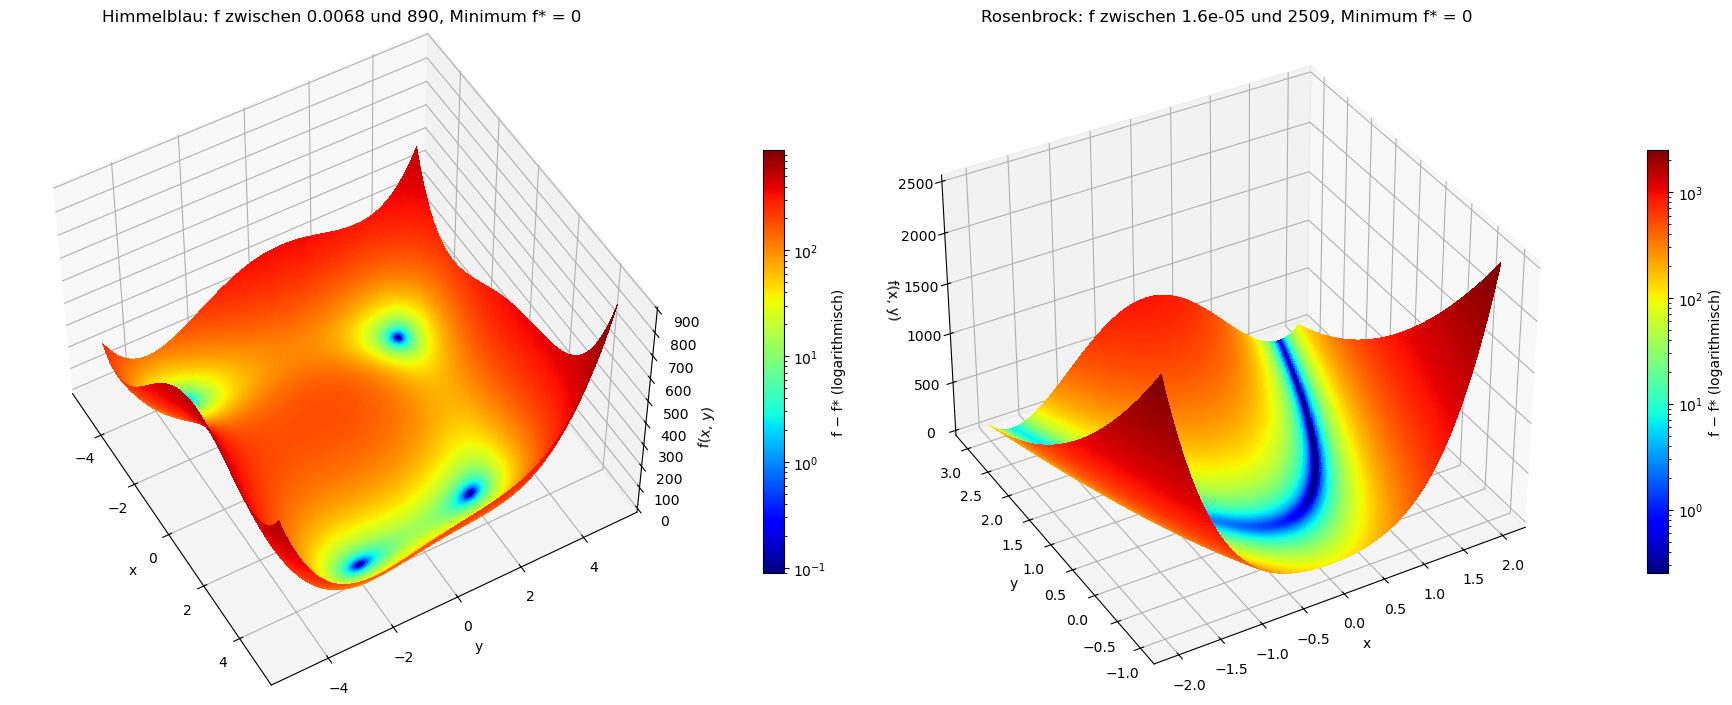

Rosenbrock entlang der Talsohle y = x²: f(−1, 1) = 4, f(0, 0) = 1, f(0.5, 0.25) = 0.25, f(1, 1) = 0
Rosenbrock quer zum Tal, 0.5 neben der Sohle: f(0.5, 0.75) = 25.2


In [9]:
from matplotlib.colors import LogNorm, Normalize


def flaeche_3d(ax, f, ausschnitt, f_stern, n=200, blick=(50, -30), farbbalken=True, schrift=10, log=True):
    """f(x, y) als Fläche über dem Ausschnitt; Farbe nach f − f* (blau = nahe am Minimum), logarithmisch ab
    10⁻⁴ der Spannweite, damit flache Mulden als Flecken sichtbar sind, oder linear (log=False)."""
    gx = np.linspace(*ausschnitt[0], n)
    gy = np.linspace(*ausschnitt[1], n)
    X, Y = np.meshgrid(gx, gy)
    Z = f(np.array([X, Y]))
    abstand = Z - min(f_stern, Z.min())
    norm = LogNorm(vmin=1e-4 * abstand.max(), vmax=abstand.max(), clip=True) if log else Normalize(0, abstand.max())
    ax.plot_surface(X, Y, Z, facecolors=plt.cm.jet(norm(abstand)), rstride=1, cstride=1, linewidth=0,
                    antialiased=False, shade=False)
    ax.view_init(elev=blick[0], azim=blick[1])
    ax.set_xlabel("x", fontsize=schrift)
    ax.set_ylabel("y", fontsize=schrift)
    ax.set_zlabel("f(x, y)", fontsize=schrift)
    if farbbalken:
        skala = plt.cm.ScalarMappable(norm=norm, cmap="jet")
        plt.colorbar(skala, ax=ax, shrink=0.55, pad=0.1, label="f − f*" + (" (logarithmisch)" if log else ""))
    return Z


fig = plt.figure(figsize=(18, 8))
for k, (name, blick) in enumerate([("Himmelblau", (50, -30)), ("Rosenbrock", (35, -120))]):
    f, _, ausschnitt, minima, f_stern = GALERIE[name]
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    Z = flaeche_3d(ax, f, ausschnitt, f_stern, n=250, blick=blick)
    ax.set_title(f"{name}: f zwischen {Z.min():.2g} und {Z.max():.0f}, Minimum f* = {f_stern:g}")
plt.tight_layout()
plt.show()

f_tal = lambda x: rosenbrock(np.array([x, x ** 2]))
print("Rosenbrock entlang der Talsohle y = x²: f(−1, 1) = {:.0f}, f(0, 0) = {:.0f}, f(0.5, 0.25) = {:.2f}, f(1, 1) = {:.0f}"
      .format(f_tal(-1.0), f_tal(0.0), f_tal(0.5), f_tal(1.0)))
print("Rosenbrock quer zum Tal, 0.5 neben der Sohle: f(0.5, 0.75) = {:.1f}".format(rosenbrock(np.array([0.5, 0.75]))))

* Das **linke Bild** zeigt Himmelblau als Fläche: vier dunkelblaue Mulden mit $f = 0$, dazwischen ein flacher Buckel mit dem Maximum $181.6$ und vier Pässe (die Sattelpunkte aus Experiment 8); an den Ecken steigt $f$ auf 890. Ohne die logarithmische Farbe wäre nur die große Schüssel zu sehen.
* Das **rechte Bild** zeigt Rosenbrock: ein gebogenes, schmales Tal (blau) zwischen hohen Wänden bis 2509. Die Ausgabe erklärt, warum man das Minimum kaum sieht: Entlang der Talsohle $y = x^2$ fällt $f$ nur von 4 bei $x = -1$ über 1 und $0.25$ auf 0 bei $(1, 1)$, quer dazu, nur 0.5 neben der Sohle, ist es schon $25.2$. Die Sohle ist fast flach; das Minimum ist eine winzige Senke in einem langen Graben.

Und alle zwölf Funktionen der Galerie, mit denselben Ausschnitten wie in Experiment 7? Bei den sieben Funktionen mit wenigen Minima ist die Farbe logarithmisch in $f - f^\ast$, bei den fünf mit vielen lokalen Minima (Rastrigin, Ackley, Easom, Schwefel, Eggholder) linear: Dort liegen fast alle Werte in derselben Größenordnung, und eine logarithmische Skala würde alles gleich färben. Vorher überlegen: Welche Funktion sieht in 3D fast wie eine Ebene aus, und bei welchen sieht man, dass das Minimum am Rand liegt?

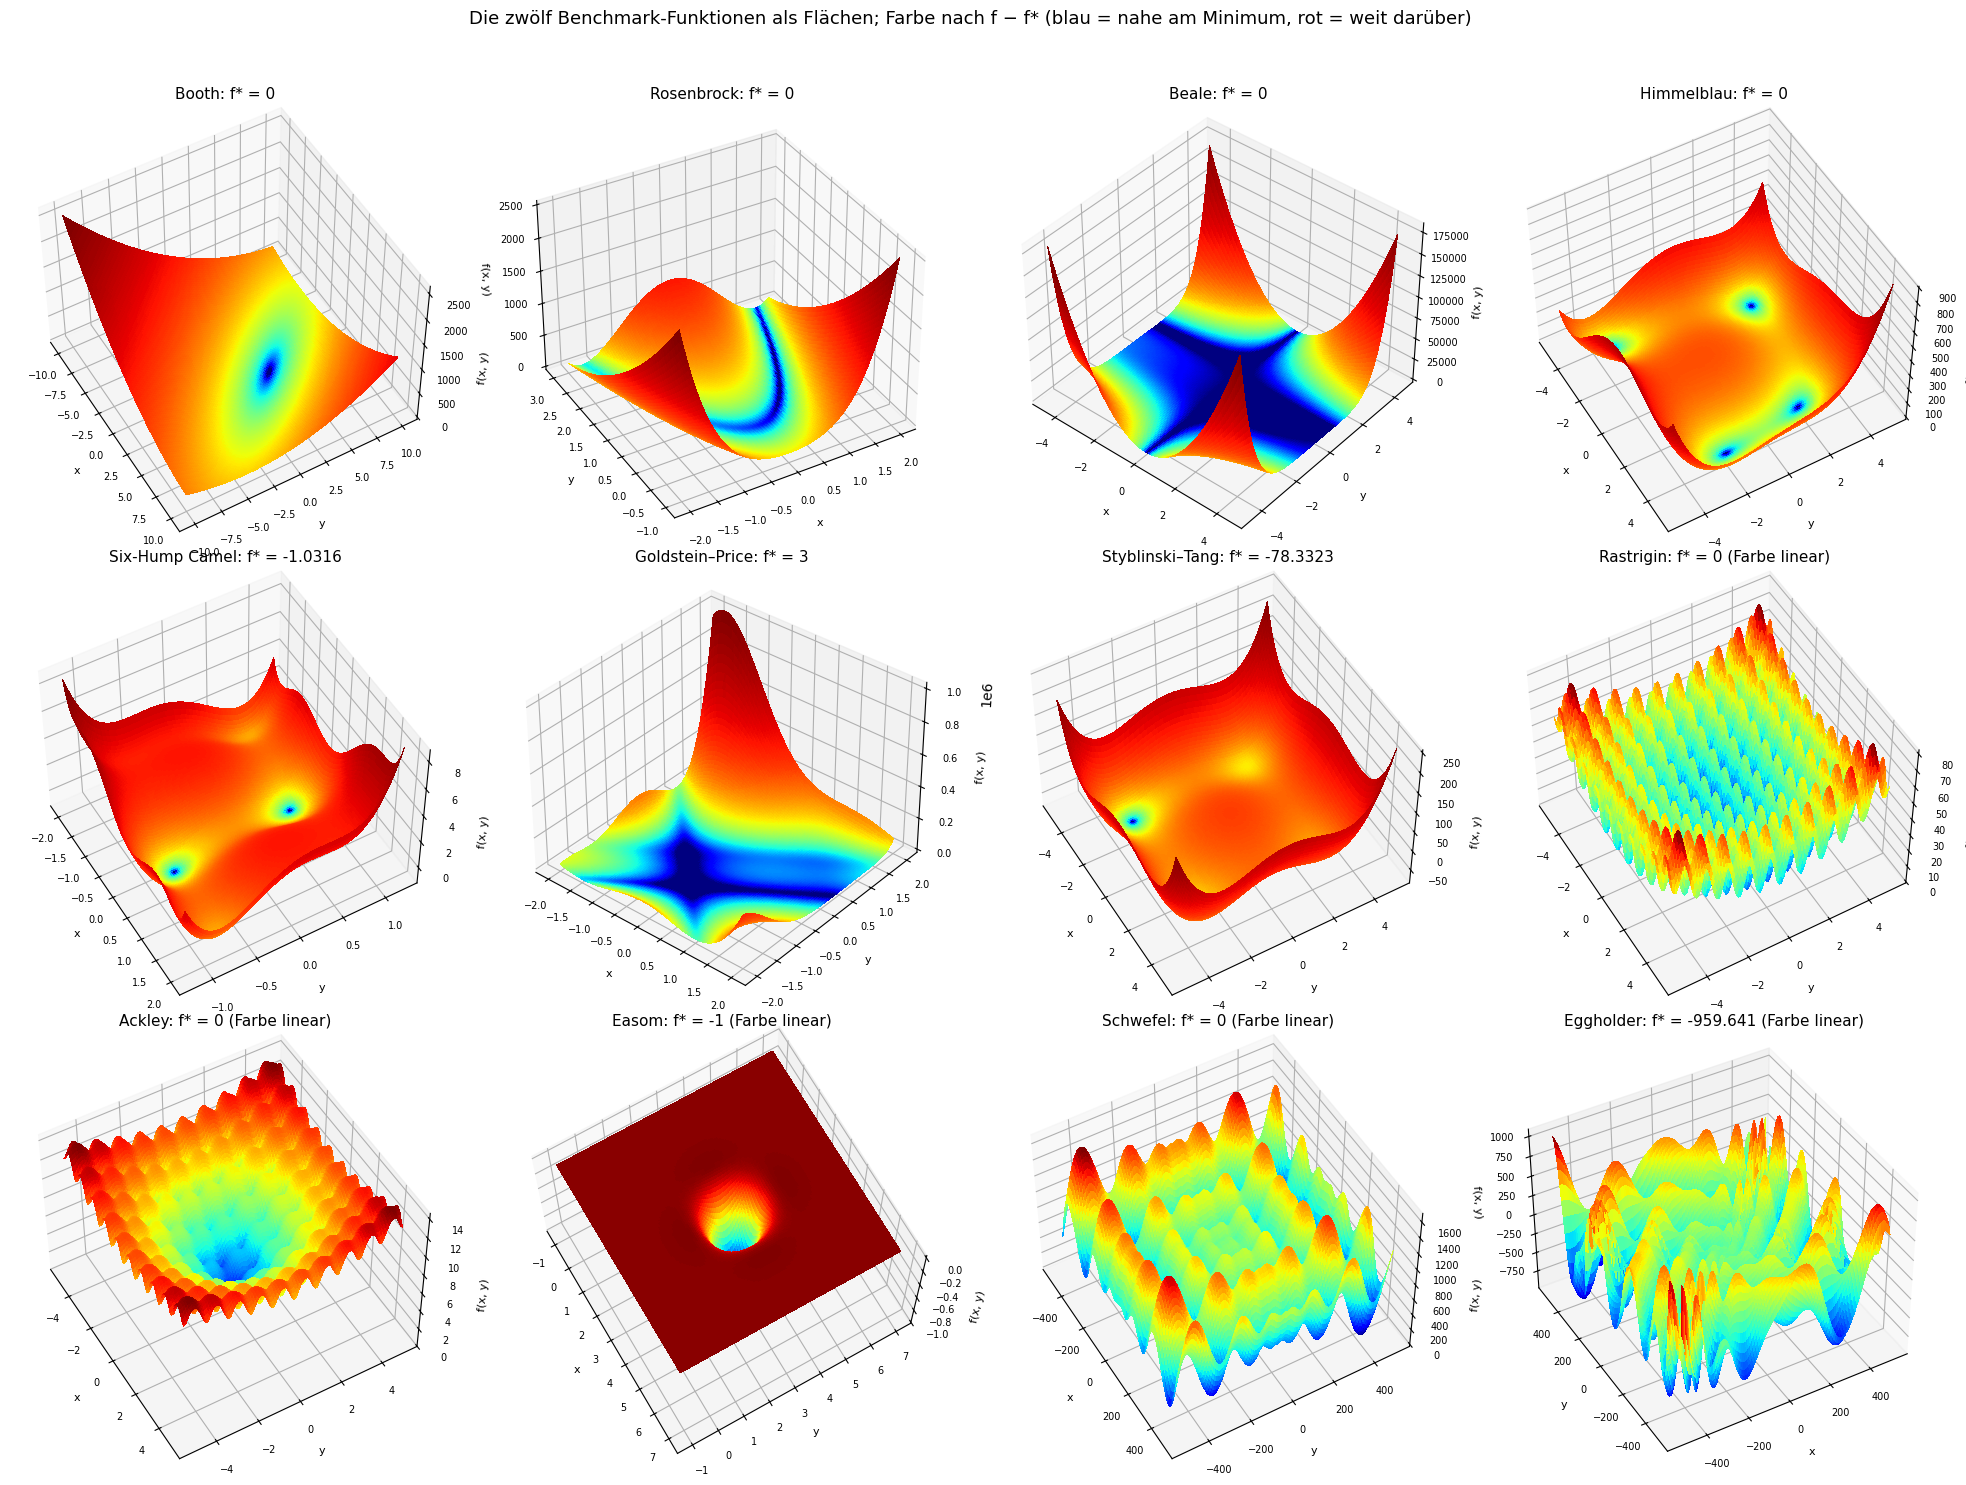

In [10]:
linear = {"Rastrigin", "Ackley", "Easom", "Schwefel", "Eggholder"}
blicke = {"Rosenbrock": (35, -120), "Beale": (40, -50), "Goldstein–Price": (35, -50), "Easom": (70, -30), "Eggholder": (40, -120)}
fig = plt.figure(figsize=(20, 15))
for k, (name, (f, _, ausschnitt, minima, f_stern)) in enumerate(GALERIE.items()):
    ax = fig.add_subplot(3, 4, k + 1, projection="3d")
    flaeche_3d(ax, f, ausschnitt, f_stern, n=120, blick=blicke.get(name, (50, -30)), farbbalken=False, schrift=8,
               log=name not in linear)
    ax.set_title(f"{name}: f* = {f_stern:g}" + (" (Farbe linear)" if name in linear else ""), fontsize=11)
    ax.tick_params(labelsize=7)
fig.suptitle("Die zwölf Benchmark-Funktionen als Flächen; Farbe nach f − f* (blau = nahe am Minimum, rot = weit darüber)", fontsize=13)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

* Die **obere Reihe** zeigt die glatten Funktionen: Booth als weite Schüssel, Rosenbrock mit seinem Tal, Beale mit vier steilen Ecken bis 175 000 und einem flachen blauen Kreuz in der Mitte, Himmelblau mit vier Mulden. In der **mittleren Reihe** haben Six-Hump Camel und Styblinski–Tang einzelne Mulden in einer Landschaft, Goldstein–Price eine Spitze bis $10^6$ über einem flachen Bereich, und Rastrigin sieht aus wie ein Eierkarton.
* In der **unteren Reihe** ist Ackley ein Trichter mit gewellter Oberfläche, Easom fast genau eine Ebene mit einem einzigen Loch: Überall sonst ist der Gradient praktisch null, ein Verfahren findet keinen Hinweis, wohin es gehen soll. Schwefel und Eggholder sind zerklüftete Gebirge; bei Eggholder liegt der tiefste Punkt am Rand des Gebiets, bei Schwefel nahe an einer Ecke.

##### *8. Himmelblau: vier Minima, neun kritische Punkte, zwei Arten von Einzugsgebieten*

Wo liegen alle kritischen Punkte von Himmelblau, sind es wirklich neun, und welcher Art sind sie? In welches der vier Minima läuft der Gradientenabstieg von jedem Startpunkt in $[-5, 5]^2$? Und wohin läuft das Newton-Verfahren für $\nabla f = 0$, das nicht weiß, ob es ein Minimum, einen Sattel oder ein Maximum sucht? Vorher vorhersagen: Welcher Anteil der Newton-Startpunkte endet nicht in einem Minimum?

Mit sympy werden $x + (11 - x^2)^2 - 7$ faktorisiert und die Resultante der beiden Gleichungen $f_x = 0$, $f_y = 0$ berechnet; ihre reellen Nullstellen geben alle kritischen Punkte, die über die Hesse-Matrix eingeordnet werden. Danach laufen Gradientenabstieg und Newton-Verfahren von jedem Punkt eines feinen Gitters in $[-5, 5]^2$; jeder Startpunkt wird nach seinem Ziel eingefärbt.

**Hintergrund & Fachbegriffe:**
- **Kritischer Punkt und Hesse-Matrix:** $\nabla f = 0$; die Eigenwerte der Hesse-Matrix entscheiden zwischen Minimum (beide positiv), Maximum (beide negativ) und Sattel (gemischt).
- **Resultante:** eine Größe, die aus zwei Polynomgleichungen eine Variable eliminiert; ihre Nullstellen sind die $x$-Werte der gemeinsamen Lösungen. **Satz von Bézout:** Zwei Polynomgleichungen der Grade $m$ und $n$ haben höchstens $mn$ isolierte gemeinsame Lösungen, hier $3\cdot3 = 9$.
- **Satz von Poincaré–Hopf:** Auf einer Scheibe, an deren Rand $\nabla f$ nach außen zeigt, gilt $\#\text{Minima} - \#\text{Sattel} + \#\text{Maxima} = 1$. Die Zahl der Sattelpunkte folgt also aus der der Minima und Maxima.
- **Einzugsgebiet:** die Menge der Startpunkte, von denen ein Verfahren in ein bestimmtes Minimum läuft.
- **Newton-Verfahren für $\nabla f = 0$:** $x\leftarrow x - (\nabla^2f)^{-1}\nabla f$ sucht Nullstellen des Gradienten. Es konvergiert schnell, unterscheidet aber nicht zwischen Minima, Sätteln und Maxima.

Faktorisierung (Theorie, Abschnitt 7): (x - 3)*(x**3 + 3*x**2 - 13*x - 38)
Resultante von f_x und f_y bezüglich y: Grad 9, reelle Nullstellen: 9

         x          y           f   Typ
 -3.779310  -3.283186    0.000000   Minimum
 -2.805118   3.131313    0.000000   Minimum
  3.000000   2.000000    0.000000   Minimum
  3.584428  -1.848127    0.000000   Minimum
 -3.073026  -0.081353  104.015163   Sattel
 -0.127961  -1.953715  178.337239   Sattel
  0.086678   2.884255   67.719150   Sattel
  3.385154   0.073852   13.311926   Sattel
 -0.270845  -0.923039  181.616522   Maximum
Poincaré–Hopf: #Min − #Sattel + #Max = 4 − 4 + 1 = 1



Gradientenabstieg: Anteile der vier Minima: 0.237, 0.260, 0.256, 0.247 | nicht entschieden: 0.0000
Newton endet in einem Minimum : 0.579
Newton endet in einem Sattel  : 0.359
Newton endet in einem Maximum : 0.061
Newton ohne Konvergenz in 60 Schritten: 0.0000


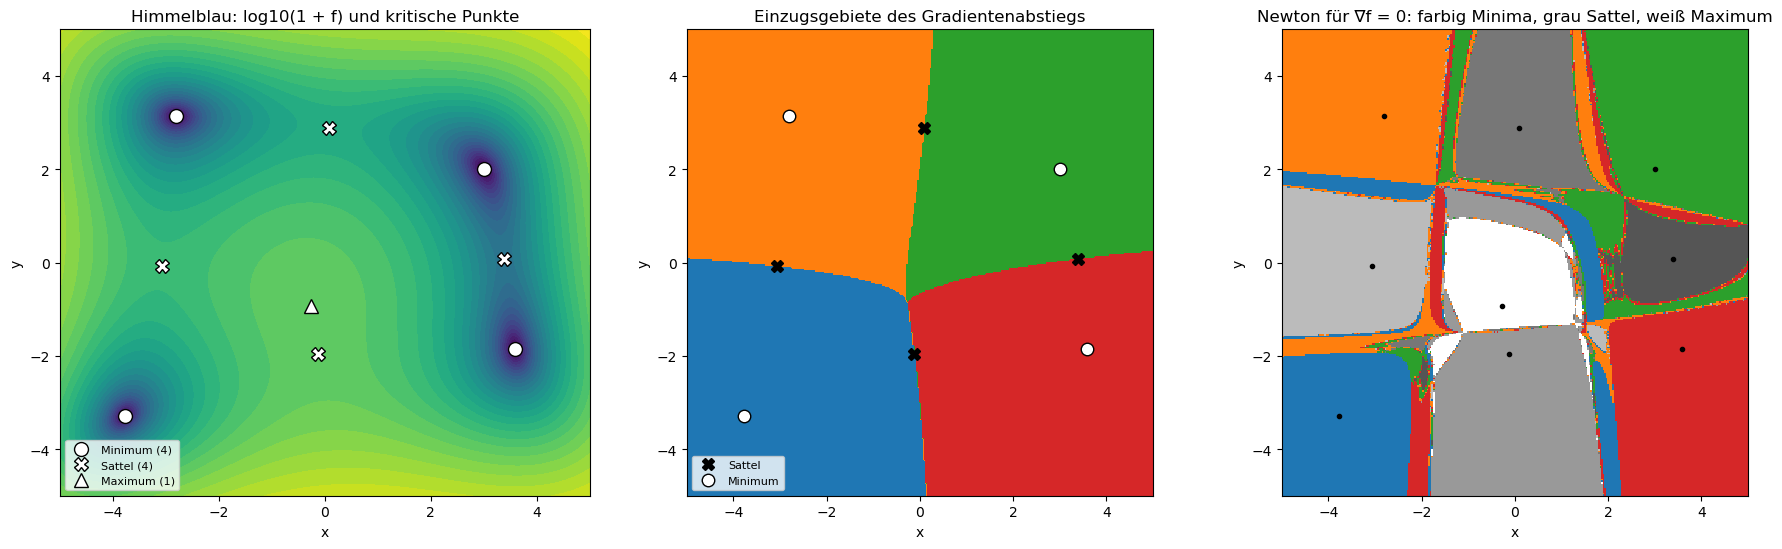

In [11]:
xs_, ys_ = sp.symbols("x y", real=True)
f_sym = (xs_ ** 2 + ys_ - 11) ** 2 + (xs_ + ys_ ** 2 - 7) ** 2
fx, fy = sp.diff(f_sym, xs_), sp.diff(f_sym, ys_)
print("Faktorisierung (Theorie, Abschnitt 7):", sp.factor(sp.expand(xs_ + (11 - xs_ ** 2) ** 2 - 7)))
resultante = sp.Poly(sp.resultant(fx, fy, ys_), xs_)
wurzeln = [complex(w) for w in resultante.nroots(n=30)]
print(f"Resultante von f_x und f_y bezüglich y: Grad {resultante.degree()}, reelle Nullstellen: "
      f"{sum(abs(w.imag) < 1e-12 for w in wurzeln)}")

hesse = sp.lambdify((xs_, ys_), sp.hessian(f_sym, (xs_, ys_)), "numpy")
kritisch = []
for w in wurzeln:
    x0 = w.real
    for y0 in sp.Poly(fx.subs(xs_, x0), ys_).nroots(n=30):
        y0 = complex(y0)
        if abs(y0.imag) < 1e-10 and abs(float(fy.subs({xs_: x0, ys_: y0.real}))) < 1e-6:
            ev = np.linalg.eigvalsh(np.array(hesse(x0, y0.real), dtype=float))
            typ = "Minimum" if ev.min() > 0 else ("Maximum" if ev.max() < 0 else "Sattel")
            kritisch.append((x0, y0.real, typ))
kritisch.sort(key=lambda k: ("Minimum", "Sattel", "Maximum").index(k[2]))
print(f"\n{'x':>10s} {'y':>10s} {'f':>11s}   Typ")
for x0, y0, typ in kritisch:
    print(f"{x0:10.6f} {y0:10.6f} {himmelblau((x0, y0)):11.6f}   {typ}")
anz = {t: sum(k[2] == t for k in kritisch) for t in ("Minimum", "Sattel", "Maximum")}
print(f"Poincaré–Hopf: #Min − #Sattel + #Max = {anz['Minimum']} − {anz['Sattel']} + {anz['Maximum']} = "
      f"{anz['Minimum'] - anz['Sattel'] + anz['Maximum']}")


def grad_h(x, y):
    a, b = x ** 2 + y - 11, x + y ** 2 - 7
    return 4 * x * a + 2 * b, 2 * a + 4 * y * b


n = 300
g = np.linspace(-5, 5, n)
X0, Y0 = np.meshgrid(g, g)
punkte = np.array([[k[0], k[1]] for k in kritisch])
minima_h = punkte[:4]

# Gradientenabstieg mit kleinem Schritt (≈ Gradientenfluss)
x, y = X0.copy(), Y0.copy()
for _ in range(3000):
    gx_, gy_ = grad_h(x, y)
    x, y = x - 0.004 * gx_, y - 0.004 * gy_
abstand = np.hypot(x[..., None] - minima_h[:, 0], y[..., None] - minima_h[:, 1])
becken_gd = np.where(abstand.min(axis=-1) < 1e-3, abstand.argmin(axis=-1), -1)

# Newton für ∇f = 0
x, y = X0.copy(), Y0.copy()
with np.errstate(all="ignore"):
    for _ in range(60):
        gx_, gy_ = grad_h(x, y)
        hxx, hyy, hxy = 12 * x ** 2 + 4 * y - 42, 12 * y ** 2 + 4 * x - 26, 4 * x + 4 * y
        det = hxx * hyy - hxy ** 2
        x, y = x - (hyy * gx_ - hxy * gy_) / det, y - (hxx * gy_ - hxy * gx_) / det
    abstand = np.hypot(x[..., None] - punkte[:, 0], y[..., None] - punkte[:, 1])
    ziel_nt = np.where(np.nan_to_num(abstand.min(axis=-1), nan=1e9) < 1e-6, abstand.argmin(axis=-1), -1)
print("\nGradientenabstieg: Anteile der vier Minima:", ", ".join(f"{np.mean(becken_gd == i):.3f}" for i in range(4)),
      f"| nicht entschieden: {np.mean(becken_gd == -1):.4f}")
typen = np.array([k[2] for k in kritisch])
for t in ("Minimum", "Sattel", "Maximum"):
    idx = np.where(typen == t)[0]
    print(f"Newton endet in einem {t:8s}: {np.mean(np.isin(ziel_nt, idx)):.3f}")
print(f"Newton ohne Konvergenz in 60 Schritten: {np.mean(ziel_nt == -1):.4f}")

farben_min = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
Z = himmelblau(np.array([X0, Y0]))
axes[0].contourf(X0, Y0, np.log10(1 + Z), levels=30, cmap="viridis")
symbol = {"Minimum": "o", "Sattel": "X", "Maximum": "^"}
for t in ("Minimum", "Sattel", "Maximum"):
    pp = punkte[typen == t]
    axes[0].plot(pp[:, 0], pp[:, 1], symbol[t], color="w", mec="k", ms=10, ls="none", label=f"{t} ({len(pp)})")
axes[0].set_title("Himmelblau: log10(1 + f) und kritische Punkte")
axes[0].legend(fontsize=8, loc="lower left")
cmap_gd = ListedColormap(["0.85"] + farben_min)
axes[1].imshow(becken_gd + 1, extent=[-5, 5, -5, 5], origin="lower", cmap=cmap_gd, vmin=0, vmax=4)
axes[1].plot(punkte[typen == "Sattel"][:, 0], punkte[typen == "Sattel"][:, 1], "kX", ms=9, label="Sattel")
axes[1].plot(minima_h[:, 0], minima_h[:, 1], "wo", mec="k", ms=9, label="Minimum")
axes[1].set_title("Einzugsgebiete des Gradientenabstiegs")
axes[1].legend(fontsize=8, loc="lower left")
farben_alle = ["0.15"] + farben_min + ["#bbbbbb", "#999999", "#777777", "#555555", "#ffffff"]
axes[2].imshow(ziel_nt + 1, extent=[-5, 5, -5, 5], origin="lower", cmap=ListedColormap(farben_alle), vmin=0, vmax=9,
               interpolation="nearest")
axes[2].plot(punkte[:, 0], punkte[:, 1], "k.", ms=6)
axes[2].set_title("Newton für ∇f = 0: farbig Minima, grau Sattel, weiß Maximum")
for ax in axes:
    ax.set_xlabel("x")
    ax.set_ylabel("y")
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt $\log_{10}(1 + f)$ mit allen neun kritischen Punkten: die vier Minima (Kreise), vier Sattelpunkte (Kreuze) auf den Pässen zwischen den Mulden und das Maximum (Dreieck) bei $(-0.27, -0.92)$ auf dem flachen Buckel in der Mitte.
* Das **mittlere Bild** zeigt die Einzugsgebiete des Gradientenabstiegs: vier fast gleich große Gebiete (24 bis 26 % der Fläche) mit glatten Grenzen, die genau durch die Sattelpunkte laufen. Das **rechte Bild** zeigt, wohin das Newton-Verfahren läuft: farbig in ein Minimum, grau in einen Sattel, weiß ins Maximum. Nur 58 % der Startpunkte enden in einem Minimum, 36 % in einem Sattel und 6 % im Maximum, und die Grenzen sind zerfranst.
* In der **Ausgabe** faktorisiert sympy $x^4 - 22x^2 + x + 114 = (x - 3)(x^3 + 3x^2 - 13x - 38)$, die Resultante hat den Grad 9 und neun reelle Nullstellen. Die Tabelle zeigt die neun Punkte: vier Minima mit $f = 0$, vier Sattelpunkte mit $f = 13.3$, $67.7$, $104.0$, $178.3$ und das Maximum mit $f = 181.6$; Poincaré–Hopf: $4 - 4 + 1 = 1$.

##### *9. Rosenbrock: das gekrümmte Tal*

Wie viele Schritte und Auswertungen brauchen Gradientenabstieg, Momentum, Adam, Nelder–Mead, BFGS und Newton vom klassischen Startpunkt $(-1.2, 1)$ bis zum Minimum $(1, 1)$, und wie sehen ihre Wege aus? Die eigenen Verfahren stoppen bei $\Vert x - x^\ast\Vert<10^{-6}$; dass man $x^\ast$ kennt, ist genau der Vorteil einer Benchmark-Funktion. Vorher mit Abschnitt 7 der Theorie vorhersagen: Wie viele Schritte braucht der Gradientenabstieg mit $\eta = 0.001$, und was passiert mit $\eta = 0.002$?

Gradientenabstieg, Momentum, Adam und Newton sind selbst programmiert und laufen höchstens 200 000 Schritte; Nelder–Mead und BFGS kommen aus scipy, mit einem Zähler für die Funktionsauswertungen. Zuerst werden Eigenwerte und Kondition der Hesse-Matrix am Minimum ausgegeben.

**Hintergrund & Fachbegriffe:**
- **Gradientenabstieg und Schrittweite:** $x\leftarrow x - \eta\nabla f$. Ist $\eta$ größer als $2/\lambda_{\max}$ (größter Eigenwert der Hesse-Matrix), schaukeln sich die Schritte in der steilen Richtung auf; ist es klein, kommt man in der flachen Richtung kaum voran.
- **Kondition:** $\kappa = \lambda_{\max}/\lambda_{\min}$; bei Rosenbrock 2508. Je größer $\kappa$, desto mehr Schritte braucht der Gradientenabstieg.
- **Momentum und Adam:** Momentum (Heavy Ball) addiert einen Teil des letzten Schritts und gleitet so durch flache Täler; Adam normiert die Schrittweite pro Koordinate mit gleitenden Mittelwerten von Gradient und quadriertem Gradient (Standard beim Training neuronaler Netze).
- **Newton und BFGS:** Newton nutzt die Hesse-Matrix und springt zum Minimum der quadratischen Näherung; nahe dem Minimum verdoppelt sich die Zahl der richtigen Stellen pro Schritt. BFGS baut eine Näherung der inversen Hesse-Matrix aus Gradientendifferenzen auf (Quasi-Newton).
- **Nelder–Mead:** ein Verfahren ohne Gradienten: Ein Dreieck (Simplex) aus drei Punkten wird gespiegelt, gestreckt und zusammengezogen, bis es das Minimum einschließt.

Hesse-Matrix bei (1, 1): Eigenwerte 1001.60 und 0.3994, Kondition 2508, Stabilitätsgrenze 2/λmax = 0.001997


Gradient η = 0.001          :   34374 Schritte, konvergiert, Abstand am Ende 1.0e-06


Gradient η = 0.002          :  200000 Schritte, nicht konvergiert, Abstand am Ende 2.7e-03
Momentum η = 0.001, β = 0.9 :    3241 Schritte, konvergiert, Abstand am Ende 1.0e-06
Adam lr = 0.01              :    5559 Schritte, konvergiert, Abstand am Ende 1.0e-06
Newton                      :       6 Schritte, konvergiert, Abstand am Ende 1.9e-11
Vorhersage für den Gradientenabstieg mit η = 0.001: ln(1e6)/(η λmin) = 34594 Schritte
Nelder-Mead                 :     132 Iterationen, 249 Funktionsauswertungen, Abstand am Ende 5.4e-11
BFGS                        :      34 Iterationen, 41 Funktionsauswertungen und 41 Gradienten, Abstand am Ende 1.2e-12


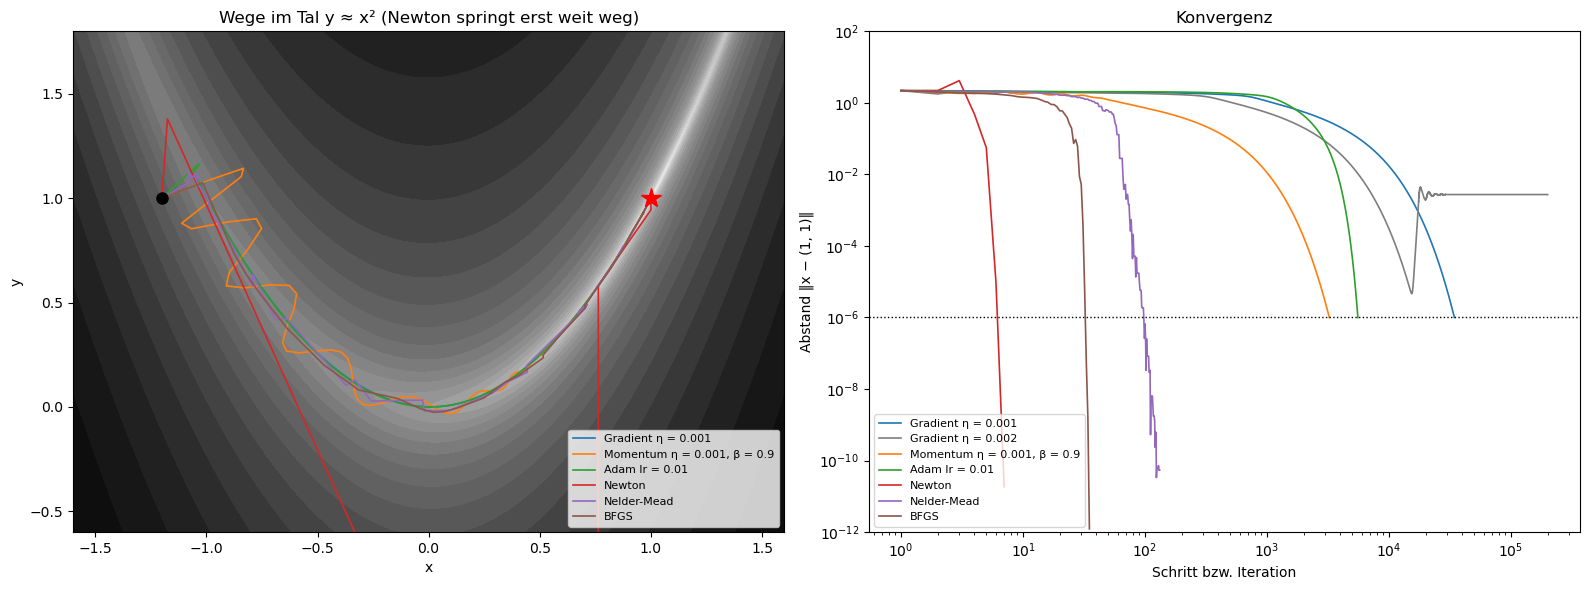

In [12]:
def f_rb(z):
    return rosenbrock(z)

def g_rb(z):
    x, y = z
    return np.array([-2 * (1 - x) - 400 * x * (y - x ** 2), 200 * (y - x ** 2)])

def h_rb(z):
    x, y = z
    return np.array([[2 - 400 * (y - x ** 2) + 800 * x ** 2, -400 * x], [-400 * x, 200]])


ev = np.linalg.eigvalsh(h_rb([1, 1]))
print(f"Hesse-Matrix bei (1, 1): Eigenwerte {ev[1]:.2f} und {ev[0]:.4f}, Kondition {ev[1] / ev[0]:.0f}, "
      f"Stabilitätsgrenze 2/λmax = {2 / ev[1]:.6f}")
x_start, x_stern, tol = np.array([-1.2, 1.0]), np.array([1.0, 1.0]), 1e-6


def eigene(schritt, max_schritte=200000):
    """Führt ein Verfahren aus; schritt(x, zustand, i) gibt (x_neu, zustand) zurück. Ergebnis: Weg und Zahl der Schritte."""
    x, zustand, weg = x_start.copy(), None, [x_start.copy()]
    for i in range(1, max_schritte + 1):
        x, zustand = schritt(x, zustand, i)
        weg.append(x.copy())
        if not np.all(np.isfinite(x)) or np.linalg.norm(x - x_stern) > 1e6:
            return np.array(weg), i, "divergiert"
        if np.linalg.norm(x - x_stern) < tol:
            return np.array(weg), i, "konvergiert"
    return np.array(weg), max_schritte, "nicht konvergiert"


def gd(eta):
    return lambda x, z, i: (x - eta * g_rb(x), None)

def heavy_ball(eta, beta):
    def schritt(x, v, i):
        v = beta * (np.zeros(2) if v is None else v) - eta * g_rb(x)
        return x + v, v
    return schritt

def adam(lr, b1=0.9, b2=0.999, e=1e-8):
    def schritt(x, z, i):
        m, v = (np.zeros(2), np.zeros(2)) if z is None else z
        gr = g_rb(x)
        m, v = b1 * m + (1 - b1) * gr, b2 * v + (1 - b2) * gr ** 2
        return x - lr * (m / (1 - b1 ** i)) / (np.sqrt(v / (1 - b2 ** i)) + e), (m, v)
    return schritt

def newton(x, z, i):
    return x - np.linalg.solve(h_rb(x), g_rb(x)), None


laeufe = {}
farbe9 = {"Gradient η = 0.001": "C0", "Gradient η = 0.002": "C7", "Momentum η = 0.001, β = 0.9": "C1",
          "Adam lr = 0.01": "C2", "Newton": "C3", "Nelder-Mead": "C4", "BFGS": "C5"}
for name, schritt in [("Gradient η = 0.001", gd(0.001)), ("Gradient η = 0.002", gd(0.002)),
                      ("Momentum η = 0.001, β = 0.9", heavy_ball(0.001, 0.9)), ("Adam lr = 0.01", adam(0.01)),
                      ("Newton", newton)]:
    weg, schritte, status = eigene(schritt)
    laeufe[name] = weg
    print(f"{name:28s}: {schritte:7d} Schritte, {status}, Abstand am Ende {np.linalg.norm(weg[-1] - x_stern):.1e}")
print(f"Vorhersage für den Gradientenabstieg mit η = 0.001: ln(1e6)/(η λmin) = {np.log(1e6) / (0.001 * ev[0]):.0f} Schritte")

for methode, kw in [("Nelder-Mead", dict(options=dict(xatol=1e-10, fatol=1e-20, maxiter=20000))),
                    ("BFGS", dict(jac=g_rb, options=dict(gtol=1e-10)))]:
    weg = [x_start.copy()]
    zaehler = Zaehler(f_rb)
    r = minimize(zaehler, x_start, method=methode, callback=lambda xk, *a: weg.append(np.array(xk)), **kw)
    laeufe[methode] = np.array(weg)
    print(f"{methode:28s}: {r.nit:7d} Iterationen, {zaehler.n} Funktionsauswertungen"
          + (f" und {r.njev} Gradienten" if methode == "BFGS" else "") + f", Abstand am Ende {np.linalg.norm(r.x - x_stern):.1e}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
gx, gy = np.linspace(-1.6, 1.6, 400), np.linspace(-0.6, 1.8, 400)
X, Y = np.meshgrid(gx, gy)
axes[0].contourf(X, Y, np.log10(rosenbrock(np.array([X, Y])) + 1e-3), levels=30, cmap="Greys")
for name, weg in laeufe.items():
    if name == "Gradient η = 0.002":
        continue
    axes[0].plot(weg[:, 0], weg[:, 1], "-", lw=1.2, color=farbe9[name], label=name)
axes[0].plot(*x_start, "ko", ms=8)
axes[0].plot(1, 1, "r*", ms=15)
axes[0].set_xlim(-1.6, 1.6)
axes[0].set_ylim(-0.6, 1.8)
axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].set_title("Wege im Tal y ≈ x² (Newton springt erst weit weg)")
axes[0].legend(fontsize=8, loc="lower right")
for name, weg in laeufe.items():
    abst = np.linalg.norm(weg - x_stern, axis=1)
    axes[1].loglog(np.arange(1, len(abst) + 1), abst, lw=1.2, color=farbe9[name], label=name)
axes[1].axhline(tol, color="k", ls=":", lw=1)
axes[1].set_ylim(1e-12, 1e2)
axes[1].set_xlabel("Schritt bzw. Iteration")
axes[1].set_ylabel("Abstand ‖x − (1, 1)‖")
axes[1].set_title("Konvergenz")
axes[1].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die Wege im Tal (dunkel = tief). Gradientenabstieg, Adam, Nelder–Mead und BFGS folgen der gekrümmten Talsohle; Momentum (orange) pendelt anfangs quer über das Tal. Newton (rot) springt zuerst weit aus dem Bild heraus bis $(0.76, -3.18)$ und landet von dort in wenigen Schritten im Minimum: Die quadratische Näherung ist weit weg schlecht, nahe am Minimum perfekt.
* Das **rechte Bild** zeigt den Abstand zum Minimum gegen die Zahl der Schritte, doppelt logarithmisch. Newton braucht 6 Schritte, BFGS 34 Iterationen (41 Auswertungen mit Gradient), Nelder–Mead 132 Iterationen (249 Auswertungen), Momentum 3241, Adam 5559 und der Gradientenabstieg mit $\eta = 0.001$ 34 374 Schritte. Mit $\eta = 0.002$ (grau) kommt er nie an: Der Abstand bleibt nach einem kurzen Überschwingen bei $3\cdot10^{-3}$ stehen.
* Die **Ausgabe** erklärt beides: Die Hesse-Matrix hat am Minimum die Eigenwerte $1001.6$ und $0.3994$, also $\kappa = 2508$ und die Stabilitätsgrenze $\eta<0.001997$. Die Vorhersage $\ln(10^6)/(\eta\lambda_{\min}) = 34\,594$ Schritte trifft die gemessenen 34 374 auf 1 %. $\eta = 0.002$ liegt knapp über der Grenze, in der steilen Richtung schwingt das Verfahren auf.

##### *10. Viele lokale Minima: Rastrigin und Ackley*

Wie schnell sinkt die Wahrscheinlichkeit, dass ein lokales Verfahren von einem zufälligen Startpunkt aus das globale Minimum von Rastrigin findet, mit der Dimension $d$, und findet es wirklich $11^d$ verschiedene lokale Minima? Was leisten Multistart, Basin-Hopping, Dual Annealing und Differential Evolution in $d = 10$ auf Rastrigin und Ackley, und mit wie vielen Funktionsauswertungen? Vorher mit Abschnitt 7 der Theorie vorhersagen: Wie groß ist die Erfolgswahrscheinlichkeit des Gradientenabstiegs für $d = 4$?

Für $d = 1$ bis 5 läuft der Gradientenabstieg von je 100 000 gleichverteilten Startpunkten; gezählt werden die Erfolge und die verschiedenen gefundenen lokalen Minima. In $d = 10$ laufen vier globale Verfahren aus scipy je dreimal auf Rastrigin und Ackley; Erfolg heißt, das globale Minimum auf $10^{-6}$ zu treffen.

**Hintergrund & Fachbegriffe:**
- **Fluch der Dimension:** Bei separablen Funktionen multiplizieren sich die Wahrscheinlichkeiten der Koordinaten; was in einer Dimension leicht ist (10 %), wird in zehn Dimensionen praktisch unmöglich ($10^{-10}$).
- **Multistart und Basin-Hopping:** Multistart startet ein lokales Verfahren (hier L-BFGS-B) von vielen Zufallspunkten. Basin-Hopping springt vom gefundenen Minimum zufällig weg, sucht lokal und behält das neue Minimum mit einer Wahrscheinlichkeit nach Metropolis.
- **Dual Annealing:** eine Form des Simulated Annealing: Sprünge mit schweren Ausläufern, die mit sinkender „Temperatur“ seltener weit gehen, kombiniert mit lokaler Suche.
- **Differential Evolution:** eine Population von Kandidaten; neue entstehen aus der Differenz zweier Mitglieder, addiert zu einem dritten, und werden koordinatenweise mit dem alten gekreuzt.
- **Funktionsauswertungen:** das übliche Kostenmaß, weil bei echten Problemen (Simulationen, Experimente) jede Auswertung teuer ist.

Rand des Einzugsgebiets von 0: b = 0.50255, p1 = 2b/10.24 = 0.09815
d = 1: Erfolg 9.77e-02 (Vorhersage p1^d = 9.82e-02, 100000 Starts); verschiedene lokale Minima gefunden: 11 (11^d = 11)


d = 2: Erfolg 9.43e-03 (Vorhersage p1^d = 9.63e-03, 100000 Starts); verschiedene lokale Minima gefunden: 121 (11^d = 121)


d = 3: Erfolg 8.40e-04 (Vorhersage p1^d = 9.46e-04, 100000 Starts); verschiedene lokale Minima gefunden: 1331 (11^d = 1331)


d = 4: Erfolg 9.00e-05 (Vorhersage p1^d = 9.28e-05, 100000 Starts)


d = 5: Erfolg 0.00e+00 (Vorhersage p1^d = 9.11e-06, 100000 Starts)

d = 10, je drei Läufe:


...

  Rastrigin Differential Evolution      : beste Werte   0.0000,   0.0000,   1.9899;  Erfolge 2/3;  Auswertungen im Mittel    111418


  Ackley    Multistart (100 × L-BFGS-B) : beste Werte  15.5067,  18.0311,  18.1880;  Erfolge 0/3;  Auswertungen im Mittel     16203


  Ackley    Basin-Hopping (100 Sprünge) : beste Werte  19.6559,  19.5454,  19.3289;  Erfolge 0/3;  Auswertungen im Mittel     17409


  Ackley    Dual Annealing              : beste Werte   0.0000,   0.0000,   0.0000;  Erfolge 3/3;  Auswertungen im Mittel     22571


  Ackley    Differential Evolution      : beste Werte   0.0000,   0.0000,   0.0000;  Erfolge 3/3;  Auswertungen im Mittel     69681


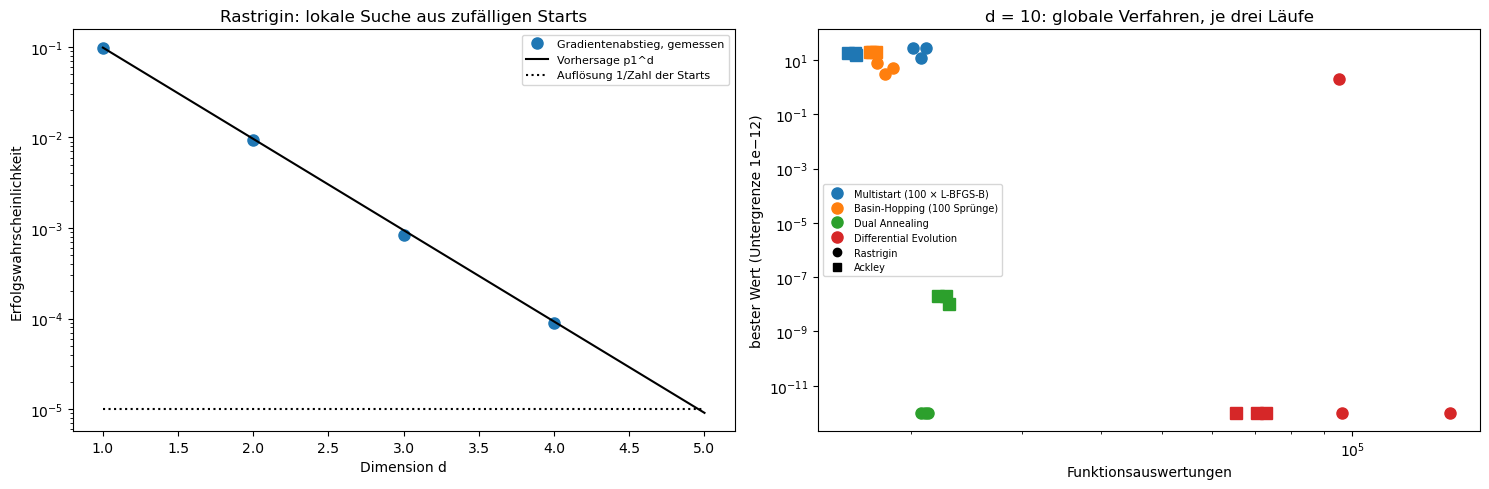

In [13]:
g1 = lambda t: 2 * t + 20 * np.pi * np.sin(2 * np.pi * t)       # Ableitung von g(t) = t² − 10 cos 2πt + 10
b_rast = brentq(g1, 0.4, 0.6)
p1 = 2 * b_rast / 10.24
print(f"Rand des Einzugsgebiets von 0: b = {b_rast:.5f}, p1 = 2b/10.24 = {p1:.5f}")
S_starts = 100000
erfolg = {}
for d in range(1, 6):
    X = rng.uniform(-5.12, 5.12, (S_starts, d))
    for _ in range(300):
        X -= 0.002 * g1(X)                                  # Gradientenabstieg, kleiner Schritt
    erfolg[d] = np.mean(np.all(np.abs(X) < 1e-6, axis=1))
    verschieden = np.unique(np.round(X, 4), axis=0).shape[0] if d <= 3 else None
    print(f"d = {d}: Erfolg {erfolg[d]:.2e} (Vorhersage p1^d = {p1 ** d:.2e}, {S_starts} Starts)"
          + (f"; verschiedene lokale Minima gefunden: {verschieden} (11^d = {11 ** d})" if verschieden else ""))


def multistart(f, grenzen, seed, starts=100):
    r_ = np.random.default_rng(seed)
    lo, hi = np.array(grenzen).T
    return min((minimize(f, r_.uniform(lo, hi), method="L-BFGS-B", bounds=grenzen) for _ in range(starts)), key=lambda r: r.fun)


verfahren = {
    "Multistart (100 × L-BFGS-B)": multistart,
    "Basin-Hopping (100 Sprünge)": lambda f, gr, s: basinhopping(
        f, np.random.default_rng(s).uniform(*np.array(gr).T), niter=100, seed=s,
        minimizer_kwargs=dict(method="L-BFGS-B", bounds=gr)),
    "Dual Annealing": lambda f, gr, s: dual_annealing(f, gr, seed=s),
    "Differential Evolution": lambda f, gr, s: differential_evolution(f, gr, seed=s, tol=1e-10, vectorized=True,
                                                                       updating="deferred"),
}
d = 10
probleme = {"Rastrigin": (rastrigin, [(-5.12, 5.12)] * d), "Ackley": (ackley, [(-32.768, 32.768)] * d)}
tabelle = {}
print(f"\nd = {d}, je drei Läufe:")
for pname, (f, grenzen) in probleme.items():
    for vname, verf in verfahren.items():
        werte, auswertungen = [], []
        for seed in range(3):
            zaehler = Zaehler(f)
            r = verf(zaehler, grenzen, seed)
            werte.append(float(r.fun))
            auswertungen.append(zaehler.n)
        tabelle[(pname, vname)] = (werte, auswertungen)
        print(f"  {pname:9s} {vname:28s}: beste Werte {', '.join(f'{w:8.4f}' for w in werte)};  "
              f"Erfolge {sum(w < 1e-6 for w in werte)}/3;  Auswertungen im Mittel {np.mean(auswertungen):9.0f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dd = np.arange(1, 6)
axes[0].semilogy(dd, [erfolg[i] if erfolg[i] > 0 else np.nan for i in dd], "o", ms=8, label="Gradientenabstieg, gemessen")
axes[0].semilogy(dd, p1 ** dd, "k-", label="Vorhersage p1^d")
axes[0].semilogy(dd, 1.0 / S_starts * np.ones_like(dd, dtype=float), "k:", label="Auflösung 1/Zahl der Starts")
axes[0].set_xlabel("Dimension d")
axes[0].set_ylabel("Erfolgswahrscheinlichkeit")
axes[0].set_title("Rastrigin: lokale Suche aus zufälligen Starts")
axes[0].legend(fontsize=8)
for (pname, vname), (werte, ausw) in tabelle.items():
    farbe = f"C{list(verfahren).index(vname)}"
    axes[1].loglog(ausw, np.maximum(werte, 1e-12), "o" if pname == "Rastrigin" else "s", color=farbe, ms=8,
                   label=vname if pname == "Rastrigin" else None)
axes[1].plot([], [], "ko", label="Rastrigin")
axes[1].plot([], [], "ks", label="Ackley")
axes[1].set_xlabel("Funktionsauswertungen")
axes[1].set_ylabel("bester Wert (Untergrenze 1e−12)")
axes[1].set_title("d = 10: globale Verfahren, je drei Läufe")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die Erfolgswahrscheinlichkeit des Gradientenabstiegs gegen $d$ auf logarithmischer Skala. Die gemessenen Punkte liegen auf der Geraden $p_1^d$: $0.098$, $0.0094$, $0.00084$ und $0.00009$ für $d = 1$ bis 4. Für $d = 5$ gab es in 100 000 Starts keinen Treffer; erwartet waren $9\cdot10^{-6}$, gerade an der Auflösung $10^{-5}$ (gepunktet).
* Das **rechte Bild** zeigt für $d = 10$ den besten Wert gegen die verbrauchten Funktionsauswertungen. Multistart (blau) und Basin-Hopping (orange) bleiben bei Werten von 3 bis 29 (Rastrigin) und 15 bis 20 (Ackley) hängen. Dual Annealing (grün) löst beide Funktionen in allen Läufen mit 21 000 bis 23 000 Auswertungen (bei Ackley bis auf $10^{-8}$, in der Ausgabe auf 0 gerundet). Differential Evolution (rot) löst Ackley immer und Rastrigin in zwei von drei Läufen, braucht dafür aber 70 000 bis 110 000 Auswertungen; im dritten Lauf ($1.99$) sitzen zwei Koordinaten in einer Nachbarmulde.
* Die **Ausgabe** gibt den Rand des Einzugsgebiets der Null, $b = 0.50255$, also $p_1 = 0.0982$, und die Zahl der gefundenen lokalen Minima: 11, 121 und 1331 für $d = 1, 2, 3$, genau $11^d$.

##### *11. Fair vergleichen: Verschieben und Drehen*

Rastrigin hat zwei Eigenschaften, die echte Probleme selten haben: Das Optimum liegt genau in der Mitte des Suchgebiets, und die Funktion ist separabel. Was passiert mit vier Verfahren in $d = 10$, wenn man das Optimum verschiebt ($f(x - z)$), die Funktion dreht ($f(Rx)$ mit einer zufälligen Drehung $R$) oder beides? Verglichen werden eine Koordinatensuche (jede Koordinate einzeln auf einem Gitter mit 1025 Punkten, drei Durchgänge, Start in der Mitte), L-BFGS-B mit Start in der Mitte, Differential Evolution und Dual Annealing. Vorher vorhersagen: Welches Verfahren verliert durch die Drehung am meisten?

Die Verschiebung $z$ und die Drehung $R$ werden zufällig gezogen; die beiden zufälligen Verfahren laufen je dreimal. Gemessen wird der beste gefundene Wert (das globale Minimum ist immer 0).

**Hintergrund & Fachbegriffe:**
- **Verschieben und Drehen:** $f(x - z)$ legt das Minimum an eine zufällige Stelle, $f(Rx)$ dreht die Funktion, sodass die Koordinaten nicht mehr unabhängig sind. Die Schwierigkeit der Landschaft ändert sich nicht, nur ihre Lage.
- **Separierbarkeit ausnutzen:** Verfahren, die Koordinaten einzeln oder koordinatenweise verändern (Koordinatensuche, die Kreuzung bei Differential Evolution), profitieren davon, dass sich eine separable Funktion Koordinate für Koordinate lösen lässt.
- **Vorteil der Mitte:** Ein Verfahren, das in der Mitte startet, findet ein Minimum in der Mitte sofort, ohne etwas zu können.
- **BBOB/COCO:** die Standardplattform für Vergleiche von Optimierern; ihre Testfunktionen sind deshalb verschoben und gedreht.

Standard             : Koordinatensuche 0;  L-BFGS-B aus der Mitte 0;  Differential Evolution 0, 0, 1.99;  Dual Annealing 4.26e-14, 2.84e-14, 5.68e-14


verschoben           : Koordinatensuche 8.53e-14;  L-BFGS-B aus der Mitte 58.7;  Differential Evolution 0, 0, 0;  Dual Annealing 5.68e-14, 8.53e-14, 4.26e-14


gedreht              : Koordinatensuche 0;  L-BFGS-B aus der Mitte 0;  Differential Evolution 4.97, 12.9, 5.97;  Dual Annealing 36.8, 26.9, 10.9


verschoben + gedreht : Koordinatensuche 29.8;  L-BFGS-B aus der Mitte 35.8;  Differential Evolution 6.96, 11.9, 9.95;  Dual Annealing 24.9, 41.9, 33.8


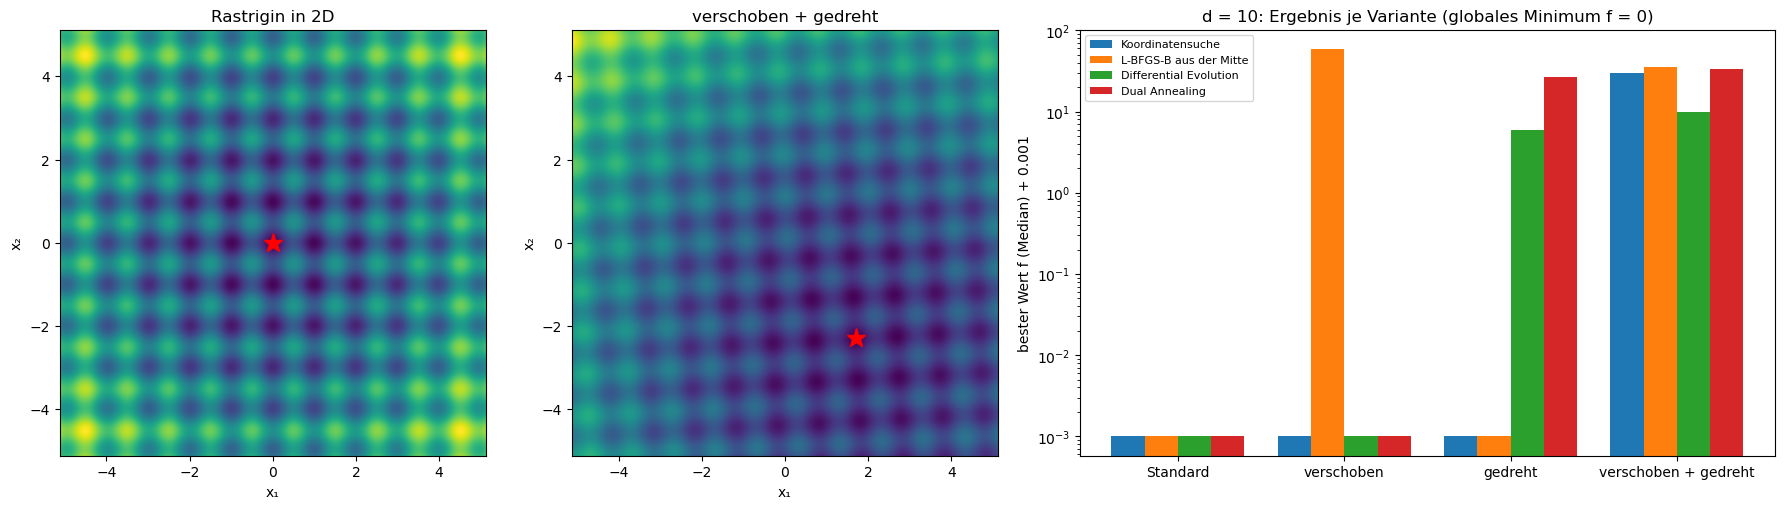

In [14]:
d, B = 10, 5.12
R = special_ortho_group.rvs(d, random_state=11)
z = np.random.default_rng(7).uniform(-3, 3, d)
spalte = lambda v, X: v.reshape((-1,) + (1,) * (np.ndim(X) - 1))      # Verschiebung passend zu (d,) oder (d, S)
varianten = {
    "Standard": lambda X: rastrigin(X),
    "verschoben": lambda X: rastrigin(np.asarray(X) - spalte(z, X)),
    "gedreht": lambda X: rastrigin(np.tensordot(R, np.asarray(X), axes=1)),
    "verschoben + gedreht": lambda X: rastrigin(np.tensordot(R, np.asarray(X) - spalte(z, X), axes=1)),
}
grenzen = [(-B, B)] * d


def koordinatensuche(f, durchgaenge=3, n=1025):
    x, gitter, auswertungen = np.zeros(d), np.linspace(-B, B, n), 0
    for _ in range(durchgaenge):
        for i in range(d):
            Xk = np.repeat(x[:, None], n, axis=1)
            Xk[i] = gitter
            x[i] = gitter[np.argmin(f(Xk))]
            auswertungen += n
    r = minimize(f, x, method="L-BFGS-B", bounds=grenzen)
    return r.fun, auswertungen + r.nfev


ergebnis11 = {}
for vname, f in varianten.items():
    werte = {"Koordinatensuche": [koordinatensuche(f)[0]],
             "L-BFGS-B aus der Mitte": [minimize(f, np.zeros(d), method="L-BFGS-B", bounds=grenzen).fun]}
    werte["Differential Evolution"] = [differential_evolution(f, grenzen, seed=s, tol=1e-10, vectorized=True,
                                                              updating="deferred").fun for s in range(3)]
    werte["Dual Annealing"] = [dual_annealing(f, grenzen, seed=s).fun for s in range(3)]
    ergebnis11[vname] = werte
    print(f"{vname:21s}: " + ";  ".join(f"{m} {', '.join(f'{w:.3g}' for w in ws)}" for m, ws in werte.items()))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw=dict(width_ratios=[1, 1, 1.6]))
R2 = special_ortho_group.rvs(2, random_state=3)
z2 = np.array([1.7, -2.3])
g2 = np.linspace(-5.12, 5.12, 400)
X, Y = np.meshgrid(g2, g2)
P = np.array([X, Y])
for ax, (titel, Z) in zip(axes[:2], [("Rastrigin in 2D", rastrigin(P)),
                                     ("verschoben + gedreht", rastrigin(np.tensordot(R2, P - z2[:, None, None], axes=1)))]):
    ax.imshow(Z, extent=[-5.12, 5.12, -5.12, 5.12], origin="lower", cmap="viridis")
    ax.set_title(titel)
    ax.set_xlabel("x₁")
    ax.set_ylabel("x₂")
axes[1].plot(*z2, "r*", ms=14)
axes[0].plot(0, 0, "r*", ms=14)
methoden = list(ergebnis11["Standard"])
breite = 0.2
for j, m in enumerate(methoden):
    median = [np.median(ergebnis11[v][m]) + 1e-3 for v in varianten]
    axes[2].bar(np.arange(len(varianten)) + (j - 1.5) * breite, median, breite, label=m)
axes[2].set_yscale("log")
axes[2].set_xticks(np.arange(len(varianten)))
axes[2].set_xticklabels(list(varianten))
axes[2].set_ylabel("bester Wert f (Median) + 0.001")
axes[2].set_title("d = 10: Ergebnis je Variante (globales Minimum f = 0)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt Rastrigin in zwei Dimensionen: ein Gitter aus Mulden, das an den Achsen ausgerichtet ist, mit dem Minimum in der Mitte (Stern). Das **mittlere Bild** zeigt dieselbe Funktion verschoben und gedreht: Das Muster ist schräg, das Minimum liegt bei etwa $(1.7, -2.3)$.
* Das **rechte Bild** zeigt den besten Wert (Median, plus 0.001 für die logarithmische Skala) für jede Variante. Auf Standard-Rastrigin lösen alle vier Verfahren das Problem. Verschoben scheitert nur der Start in der Mitte (58.7). Gedreht scheitern Differential Evolution (5 bis 13) und Dual Annealing (11 bis 37), die Separierbarkeit ausnutzen; Koordinatensuche und L-BFGS-B bleiben bei 0, aber nur, weil sie im Minimum starten. Verschoben und gedreht scheitern alle vier (7 bis 42).
* **Deutung:** Ein Teil des Erfolgs auf der Standardfunktion kommt nicht vom Verfahren, sondern von der Lage des Minimums und der Separierbarkeit. Dual Annealing, in Experiment 10 das beste Verfahren, verliert durch die Drehung am meisten. Deshalb vergleicht man an verschobenen und gedrehten Funktionen.

##### *12. Phasenschätzung mit Fenster*

Für $m = 10$ Qubits ($N = 1024$) und die Phase $\theta = 0.2718281828$, die nicht auf dem Gitter $y/N$ liegt: Wie verteilt sich das Messergebnis für das Rechteckfenster der Standard-Phasenschätzung, für das Sinus-Fenster (der für die mittlere quadratische Abweichung optimale Zustand), für Hann, Kaiser ($\beta = 10$) und die Bump-Funktion? Stimmt der Schwanz des Rechtecks mit $2\sin^2(\pi N\theta)/(\pi^2k)$ aus Abschnitt 8 der Theorie überein? Vorher vorhersagen: Welches Fenster hat bei $k = 100$ Gitterpunkten Abstand den kleinsten Schwanz, und warum fällt Kaiser am Ende nur noch langsam?

Für jedes Fenster wird die Wahrscheinlichkeit $P(y)$ aller 1024 Messergebnisse aus der Formel der Theorie exakt berechnet. Daraus folgen der mittlere quadratische Fehler (RMS) und die Schwanzwahrscheinlichkeiten $P(\vert y - N\theta\vert>k)$.

**Hintergrund & Fachbegriffe:**
- **Quanten-Phasenschätzung:** Ein Register aus $m$ Qubits steuert Potenzen $U^x$ eines Operators mit Eigenwert $e^{2\pi i\theta}$; nach der inversen Quanten-Fourier-Transformation liest man $y$ mit $y/N\approx\theta$ ab. Sie ist Kern von Shors Algorithmus und von Verfahren für Energieeigenwerte.
- **Fenster:** die Amplituden $w_x$, mit denen das Register vorbereitet wird. Das Standardverfahren nimmt alle gleich (Rechteck); andere Fenster sind glatte Funktionen über dem Register.
- **Sinus-, Hann-, Kaiser-Fenster:** $\sin(\pi(x + 1)/(N + 1))$ minimiert den mittleren quadratischen Fehler; Hann ist $\sin^2(\pi(x + \tfrac12)/N)$; Kaiser ist eine Bessel-Funktion mit Parameter $\beta$, sehr schmal im Spektrum, aber am Rand nicht exakt null.
- **RMS-Fehler und Schwanzwahrscheinlichkeit:** Der RMS-Fehler misst die typische Abweichung, die Schwanzwahrscheinlichkeit, wie oft man weit danebenliegt. Für Anwendungen, die viele Schätzungen kombinieren, zählen die Schwänze.

Fenster                   Σ P   RMS·N  P(|Fehler|>1)  P(|Fehler|>5) P(|Fehler|>20) P(|Fehler|>100)
Rechteck (Standard)  1.000000  10.721       1.54e-01       3.23e-02       8.09e-03       1.57e-03
Sinus                1.000000   0.500       6.54e-03       5.38e-05       8.76e-07       1.35e-08
Hann                 1.000000   0.577       5.06e-02       7.05e-06       6.76e-09       2.17e-12
Kaiser β = 10        1.000000   0.723       1.43e-01       1.08e-08       2.81e-09       6.31e-10
Bump                 1.000000   0.558       2.00e-02       1.09e-04       6.43e-09       5.75e-18
Rechteck bei k = 20 und 100: gemessen 8.085e-03, 1.568e-03; Vorhersage 2 sin²(πNθ)/(π²k) = 8.097e-03, 1.619e-03
Kaiser-Fenster am Rand: 3.6e-04 (relativ zur Mitte, nicht exakt 0)


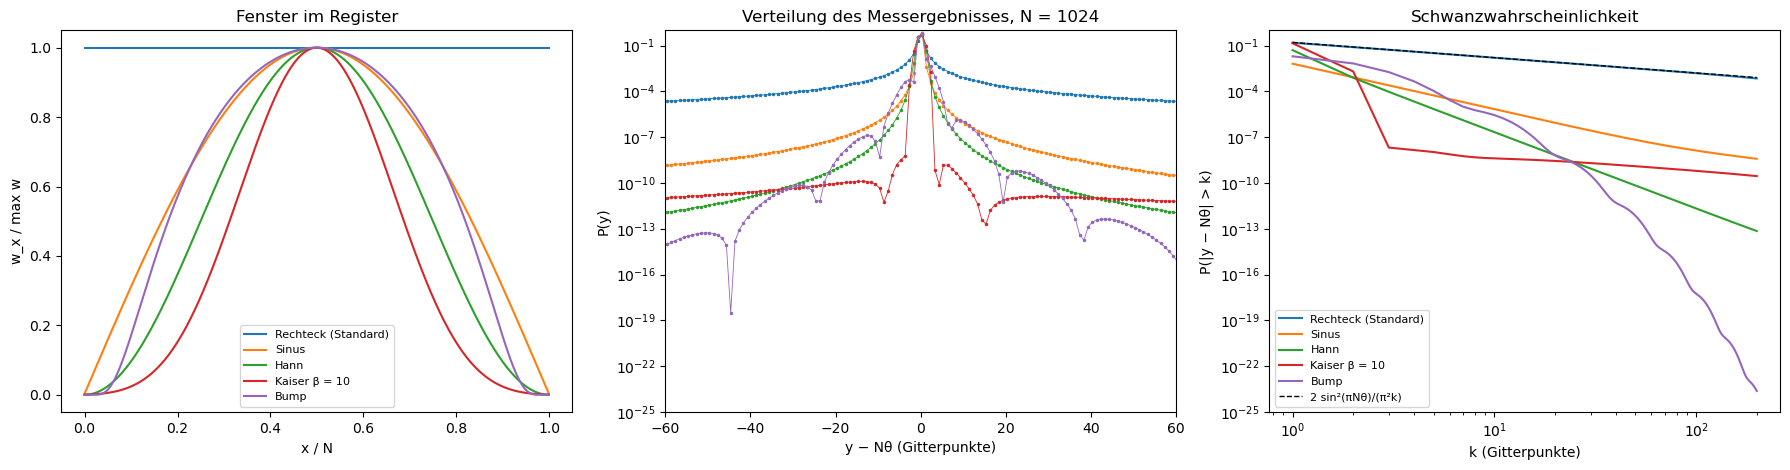

In [15]:
def qpe_verteilung(w, theta):
    """P(y) = |(1/√N) Σ_x w_x e^(2πix(θ − y/N))|² für ein normiertes Fenster w (ein FFT-Aufruf)."""
    w = np.asarray(w, dtype=float) / np.linalg.norm(w)
    N = w.size
    A = np.fft.fft(w * np.exp(2j * np.pi * np.arange(N) * theta)) / np.sqrt(N)
    return np.abs(A) ** 2


m_q, theta = 10, 0.2718281828
N = 2 ** m_q
xq = np.arange(N)
fenster = {
    "Rechteck (Standard)": np.ones(N),
    "Sinus": np.sin(np.pi * (xq + 1) / (N + 1)),
    "Hann": np.sin(np.pi * (xq + 0.5) / N) ** 2,
    "Kaiser β = 10": np.kaiser(N, 10),
    "Bump": bump(2 * (xq + 0.5) / N - 1),
}
fehler = ((theta - xq / N + 0.5) % 1 - 0.5) * N          # Abstand y ↔ Nθ in Gitterpunkten, zyklisch
ks = np.arange(1, 201)
schwaenze = {}
print(f"{'Fenster':20s} {'Σ P':>8s} {'RMS·N':>7s} " + " ".join(f"{'P(|Fehler|>' + str(k) + ')':>14s}" for k in [1, 5, 20, 100]))
for name, w in fenster.items():
    P = qpe_verteilung(w, theta)
    schwaenze[name] = np.array([P[np.abs(fehler) > k].sum() for k in ks])
    rms = np.sqrt(np.sum(P * fehler ** 2))
    print(f"{name:20s} {P.sum():8.6f} {rms:7.3f} " + " ".join(f"{schwaenze[name][k - 1]:14.2e}" for k in [1, 5, 20, 100]))
vorhersage = 2 * np.sin(np.pi * N * theta) ** 2 / (np.pi ** 2 * ks)
print(f"Rechteck bei k = 20 und 100: gemessen {schwaenze['Rechteck (Standard)'][19]:.3e}, {schwaenze['Rechteck (Standard)'][99]:.3e};"
      f" Vorhersage 2 sin²(πNθ)/(π²k) = {vorhersage[19]:.3e}, {vorhersage[99]:.3e}")
print(f"Kaiser-Fenster am Rand: {fenster['Kaiser β = 10'][0]:.1e} (relativ zur Mitte, nicht exakt 0)")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for name, w in fenster.items():
    axes[0].plot(xq / N, w / np.max(w), label=name)
    P = qpe_verteilung(w, theta)
    reihenfolge = np.argsort(fehler)
    axes[1].semilogy(fehler[reihenfolge], np.maximum(P[reihenfolge], 1e-30), ".-", ms=3, lw=0.6, label=name)
    axes[2].loglog(ks, np.maximum(schwaenze[name], 1e-30), label=name)
axes[2].loglog(ks, vorhersage, "k--", lw=1, label="2 sin²(πNθ)/(π²k)")
axes[0].set_xlabel("x / N")
axes[0].set_ylabel("w_x / max w")
axes[0].set_title("Fenster im Register")
axes[0].legend(fontsize=8)
axes[1].set_xlim(-60, 60)
axes[1].set_ylim(1e-25, 1)
axes[1].set_xlabel("y − Nθ (Gitterpunkte)")
axes[1].set_ylabel("P(y)")
axes[1].set_title(f"Verteilung des Messergebnisses, N = {N}")
axes[2].set_ylim(1e-25, 1)
axes[2].set_xlabel("k (Gitterpunkte)")
axes[2].set_ylabel("P(|y − Nθ| > k)")
axes[2].set_title("Schwanzwahrscheinlichkeit")
axes[2].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die fünf Fenster über dem Register: das konstante Rechteck und vier glatte Buckel, von denen Kaiser der schmalste ist. Das **mittlere Bild** zeigt die Verteilung des Messergebnisses um den wahren Wert. Alle haben ihre Spitze bei $y\approx N\theta$, aber die Schwänze unterscheiden sich um viele Größenordnungen: Beim Rechteck liegt $P(y)$ noch 60 Gitterpunkte entfernt bei $10^{-4}$, beim Sinus bei $10^{-8}$, bei Hann und Kaiser um $10^{-10}$ bis $10^{-12}$, bei der Bump-Funktion darunter.
* Das **rechte Bild** zeigt die Schwanzwahrscheinlichkeit gegen $k$ doppelt logarithmisch. Das Rechteck liegt genau auf der gestrichelten Vorhersage $2\sin^2(\pi N\theta)/(\pi^2k)$. Kaiser fällt anfangs am schnellsten (auf $10^{-8}$ schon bei $k = 3$), danach nur noch wie $1/k$, weil das Fenster am Rand $3.6\cdot10^{-4}$ statt 0 ist: ein kleiner Sprung. Die Bump-Funktion fällt für große $k$ am schnellsten.
* Die **Ausgabe** gibt die RMS-Fehler in Einheiten von $1/N$: Rechteck $10.7$, Sinus $0.500$ (der kleinste), Bump $0.558$, Hann $0.577$, Kaiser $0.723$. Bei $k = 100$ ist die Schwanzwahrscheinlichkeit $1.6\cdot10^{-3}$ (Rechteck), $1.4\cdot10^{-8}$ (Sinus), $2.2\cdot10^{-12}$ (Hann), $6.3\cdot10^{-10}$ (Kaiser) und $5.8\cdot10^{-18}$ (Bump). Für das Rechteck sind gemessen und vorhergesagt $8.09$ gegen $8.10\cdot10^{-3}$ bei $k = 20$ und $1.57$ gegen $1.62\cdot10^{-3}$ bei $k = 100$.

##### *13. Adiabatische Zeitpläne*

Ein Qubit wird mit $H(s) = -(1 - s)X - sZ$ in der Zeit $T$ vom Grundzustand $\vert+\rangle$ von $-X$ in den Grundzustand $\vert{\uparrow}\rangle$ von $-Z$ überführt ($\hbar = 1$, die minimale Lücke ist $\sqrt2$). Wie hängt die Fehlerwahrscheinlichkeit $P$ (am Ende im angeregten Zustand) für den linearen, kubischen, quintischen und den glatten Zeitplan $S(\tau)$ von $T$ ab, und stimmen die Vorhersagen aus Abschnitt 8 der Theorie samt Vorfaktoren, beim glatten Zeitplan also $\ln P\approx\text{const} - 4\sqrt T$? Werte unter etwa $10^{-23}$ sind nicht mehr verlässlich, weil der Integrator die Amplituden der Größe 1 nur auf etwa 13 Stellen genau rechnet. Vorher vorhersagen: Um wie viele Größenordnungen sinkt $P$ beim kubischen Zeitplan, wenn man $T$ verzehnfacht?

Die Schrödinger-Gleichung wird für jeden Zeitplan und viele Laufzeiten $T$ zwischen 2 und 250 numerisch gelöst. Die Vorhersagen der Randterme enthalten die aufintegrierte Lücke $\Phi$, die für jeden Zeitplan berechnet wird; beim glatten Zeitplan wird $\ln P$ gegen $\sqrt T$ angepasst.

**Hintergrund & Fachbegriffe:**
- **Adiabatisches Rechnen:** Man beginnt im leicht herstellbaren Grundzustand von $H(0)$ und verändert den Hamilton-Operator langsam zu $H(1)$, dessen Grundzustand die Lösung enthält. Nach dem **adiabatischen Theorem** bleibt das System im Grundzustand, wenn die Änderung langsam genug ist im Vergleich zur **Lücke** zwischen Grund- und erstem angeregtem Zustand.
- **Zeitplan:** die Funktion $s(\tau)$, $\tau = t/T$, die sagt, wie schnell man von $H(0)$ zu $H(1)$ geht. Linear ist $s = \tau$; kubisch und quintisch sind Polynome, deren erste bzw. erste zwei Ableitungen an den Enden verschwinden; $S(\tau)$ ist beliebig glatt.
- **Fehlerwahrscheinlichkeit und Randterme:** Was am Ende im angeregten Zustand landet, entsteht vor allem an Anfang und Ende, wo $s'$ springt oder schnell wechselt. Jede verschwindende Ableitung an den Enden bringt zwei Potenzen von $1/T$.
- **Vorfaktor und Schwingung:** Die Vorhersagen enthalten $\sin^2(T\Phi/2)$ oder $\cos^2(T\Phi/2)$, weil sich die Beiträge der beiden Enden je nach Laufzeit verstärken oder auslöschen.

Rechenzeit 7.3 s
linear    : Φ = 1.6232;  P/Vorhersage für T > 50: Median 1.000 (Quartile 0.984 bis 1.018)
kubisch   : Φ = 1.7114;  P/Vorhersage für T > 50: Median 1.010 (Quartile 0.985 bis 1.027)
quintisch : Φ = 1.7578;  P/Vorhersage für T > 50: Median 0.969 (Quartile 0.882 bis 1.006)
linear    : Steigung der Hülle P/sin² bzw. P/cos² gegen T (T > 50): -2.01  (Vorhersage -2)
kubisch   : Steigung der Hülle P/sin² bzw. P/cos² gegen T (T > 50): -4.00  (Vorhersage -4)
quintisch : Steigung der Hülle P/sin² bzw. P/cos² gegen T (T > 50): -6.05  (Vorhersage -6)
glatt     : ln P ≈ 4.37 -4.01·√T für T > 30 (Vorhersage für die Steigung: −4);  P(T = 250) = 1.2e-25


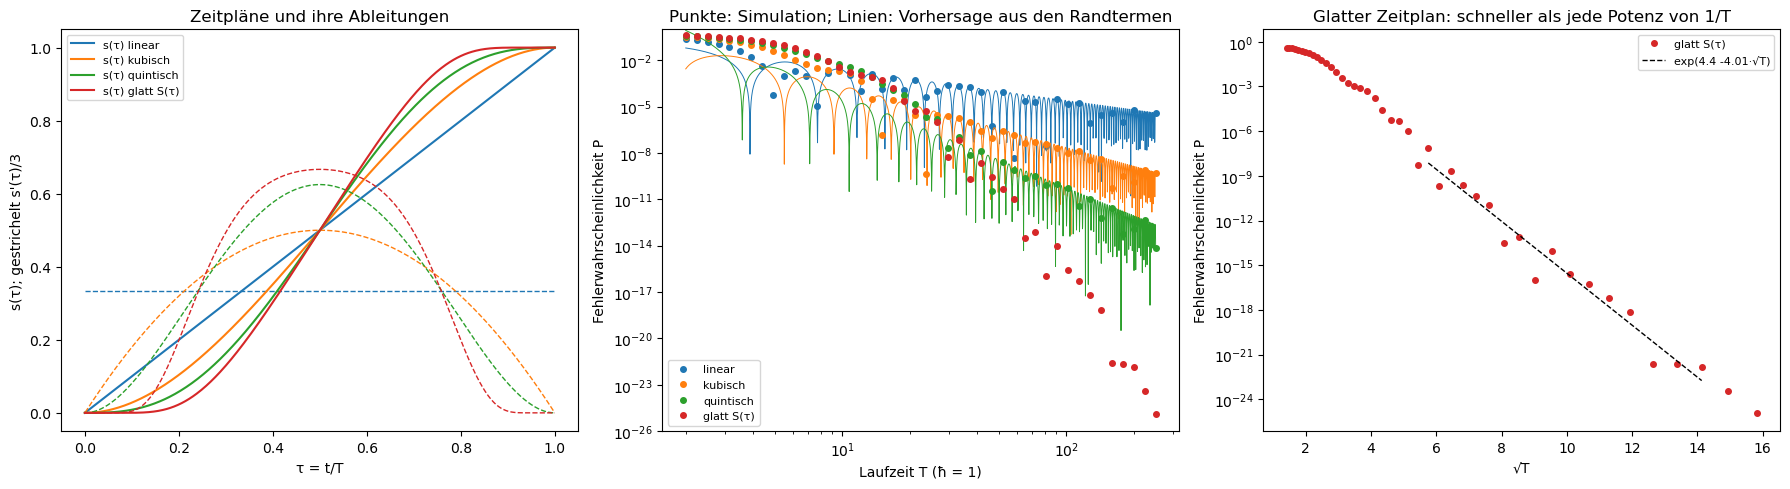

In [16]:
PX = np.array([[0, 1], [1, 0]], dtype=complex)
PZ = np.diag([1.0, -1.0]).astype(complex)
zeitplaene = {
    "linear": lambda t: t,
    "kubisch": lambda t: 3 * t ** 2 - 2 * t ** 3,
    "quintisch": lambda t: 6 * t ** 5 - 15 * t ** 4 + 10 * t ** 3,
    "glatt S(τ)": glatter_uebergang,
}
luecke = lambda s: 2 * np.sqrt(s ** 2 + (1 - s) ** 2)


def fehler_adiabatisch(s, T):
    """Wahrscheinlichkeit, am Ende im angeregten Zustand |↓⟩ von −Z zu sein; gemessen wird |ψ↓|²/‖ψ‖², damit die
    Normdrift des Integrators nicht in das Ergebnis eingeht."""
    rhs = lambda t, y: -1j * ((-(1 - s(t / T)) * PX - s(t / T) * PZ) @ y)
    y = solve_ivp(rhs, (0, T), np.array([1, 1], dtype=complex) / np.sqrt(2), method="DOP853", rtol=1e-13, atol=1e-15).y[:, -1]
    return abs(y[1]) ** 2 / np.sum(np.abs(y) ** 2)


T_werte = np.logspace(np.log10(2), np.log10(250), 44)
t0_ = time.time()
P_ad = {name: np.array([fehler_adiabatisch(s, T) for T in T_werte]) for name, s in zeitplaene.items()}
print(f"Rechenzeit {time.time() - t0_:.1f} s")
Phi = {name: quad(lambda t: luecke(float(s(t))), 0, 1, epsabs=1e-14)[0] for name, s in zeitplaene.items()}
vorher = {
    "linear": lambda T: np.sin(T * Phi["linear"] / 2) ** 2 / (4 * T ** 2),
    "kubisch": lambda T: 2.25 * np.cos(T * Phi["kubisch"] / 2) ** 2 / T ** 4,
    "quintisch": lambda T: 56.25 * np.sin(T * Phi["quintisch"] / 2) ** 2 / T ** 6,
}
gross = T_werte > 50
for name, f_vor in vorher.items():
    verhaeltnis = P_ad[name][gross] / f_vor(T_werte[gross])
    print(f"{name:10s}: Φ = {Phi[name]:.4f};  P/Vorhersage für T > 50: Median {np.median(verhaeltnis):.3f} "
          f"(Quartile {np.percentile(verhaeltnis, 25):.3f} bis {np.percentile(verhaeltnis, 75):.3f})")
for name, k_ in [("linear", 1), ("kubisch", 2), ("quintisch", 3)]:
    huelle = P_ad[name] / (np.sin(T_werte * Phi[name] / 2) ** 2 if k_ != 2 else np.cos(T_werte * Phi[name] / 2) ** 2)
    sicher = gross & (np.abs(np.sin(T_werte * Phi[name] / 2) if k_ != 2 else np.cos(T_werte * Phi[name] / 2)) > 0.5)
    steigung = np.polyfit(np.log(T_werte[sicher]), np.log(huelle[sicher]), 1)[0]
    print(f"{name:10s}: Steigung der Hülle P/sin² bzw. P/cos² gegen T (T > 50): {steigung:.2f}  (Vorhersage {-2 * k_})")
glatt = P_ad["glatt S(τ)"]
m_gl = (T_werte > 30) & (glatt > 1e-23)      # darunter begrenzt die Genauigkeit des Integrators
a_gl, b_gl = np.polyfit(np.sqrt(T_werte[m_gl]), np.log(glatt[m_gl]), 1)
print(f"glatt     : ln P ≈ {b_gl:.2f} {a_gl:+.2f}·√T für T > 30 (Vorhersage für die Steigung: −4);  "
      f"P(T = {T_werte[-1]:.0f}) = {glatt[-1]:.1e}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
tau = np.linspace(0, 1, 501)
for name, s in zeitplaene.items():
    linie, = axes[0].plot(tau, s(tau), label=f"s(τ) {name}")
    axes[0].plot(tau, np.gradient(s(tau), tau) / 3, "--", color=linie.get_color(), lw=1)
axes[0].set_xlabel("τ = t/T")
axes[0].set_ylabel("s(τ); gestrichelt s'(τ)/3")
axes[0].set_title("Zeitpläne und ihre Ableitungen")
axes[0].legend(fontsize=8)
TT = np.logspace(np.log10(2), np.log10(250), 3000)
for i, (name, P) in enumerate(P_ad.items()):
    axes[1].loglog(T_werte, P, "o", ms=4, color=f"C{i}", label=name)
    if name in vorher:
        axes[1].loglog(TT, vorher[name](TT), "-", lw=0.7, color=f"C{i}")
axes[1].set_ylim(1e-26, 1)
axes[1].set_xlabel("Laufzeit T (ħ = 1)")
axes[1].set_ylabel("Fehlerwahrscheinlichkeit P")
axes[1].set_title("Punkte: Simulation; Linien: Vorhersage aus den Randtermen")
axes[1].legend(fontsize=8, loc="lower left")
axes[2].semilogy(np.sqrt(T_werte), glatt, "o", ms=4, color="C3", label="glatt S(τ)")
axes[2].semilogy(np.sqrt(T_werte[m_gl]), np.exp(b_gl + a_gl * np.sqrt(T_werte[m_gl])), "k--", lw=1,
                 label=f"exp({b_gl:.1f} {a_gl:+.2f}·√T)")
axes[2].set_xlabel("√T")
axes[2].set_ylabel("Fehlerwahrscheinlichkeit P")
axes[2].set_title("Glatter Zeitplan: schneller als jede Potenz von 1/T")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die vier Zeitpläne (durchgezogen) und ihre Ableitungen $s'/3$ (gestrichelt). Beim linearen Zeitplan ist $s'$ konstant und springt an den Enden von 0 auf 1, beim kubischen beginnt und endet $s'$ bei null, beim quintischen auch $s''$, und beim glatten Zeitplan $S$ verschwinden alle Ableitungen an den Enden.
* Das **mittlere Bild** zeigt die Fehlerwahrscheinlichkeit gegen $T$, doppelt logarithmisch: Punkte aus der Simulation, Linien aus der Vorhersage der Randterme. Linear fällt $P$ wie $T^{-2}$, kubisch wie $T^{-4}$, quintisch wie $T^{-6}$, jeweils mit tiefen Einbrüchen, wo sich die Beiträge der Enden auslöschen. Der glatte Zeitplan (rot) fällt schneller als jede Potenz: bei $T = 250$ auf $10^{-25}$, während der lineare dort noch bei $10^{-5}$ liegt.
* Das **rechte Bild** zeigt den glatten Zeitplan gegen $\sqrt T$ mit logarithmischer $y$-Achse: Die Punkte liegen um die Gerade $e^{4.37 - 4.01\sqrt T}$, Steigung $-4$ wie vorhergesagt. In der **Ausgabe** liegt der Median von Simulation durch Vorhersage für $T>50$ bei $1.000$, $1.010$ und $0.969$, und die Hüllen fallen mit den Exponenten $-2.01$, $-4.00$ und $-6.05$ (Vorhersage $-2$, $-4$, $-6$).

##### *14. Grover-Minimumsuche auf einer diskretisierten Benchmark-Funktion*

Himmelblau wird auf einem Gitter mit $N = 2^n$ Punkten in $[-5, 5]^2$ ausgewertet; gesucht ist der kleinste Gitterwert. Wie viele Orakel-Abfragen braucht der Algorithmus von Dürr und Høyer im Mittel, wächst die Zahl wie $\sqrt N$, und wie viele Schwellen durchläuft er? Die Simulation ist exakt, ohne Zustandsvektor: Nach $j$ Grover-Iterationen ist ein markiertes Element mit Wahrscheinlichkeit $\sin^2((2j + 1)\vartheta)$ zu messen, und jedes gleich wahrscheinlich (Abschnitt 8 der Theorie). Gezählt wird jede Grover-Iteration und die eine Abfrage, mit der man das gemessene Element prüft; gestoppt wird, wenn das Minimum Schwelle ist (das echte Verfahren bricht nach $22.5\sqrt N$ Abfragen ab). Vorher vorhersagen: Wie viele Abfragen bei $N = 2^{20}$, wenn der Vorfaktor etwa 3 ist?

Für $N = 2^6$ bis $2^{20}$ wird der Algorithmus je 400-mal simuliert; aus den Ergebnissen folgen die mittlere Zahl der Abfragen, das 90-%-Quantil und die mittlere Zahl der Schwellen.

**Hintergrund & Fachbegriffe:**
- **Orakel und Abfrage:** Das Orakel markiert die gesuchten Elemente (hier: alle Gitterpunkte mit kleinerem Wert als die Schwelle); jede Anwendung zählt als eine Abfrage. Gemessen wird die Zahl der Abfragen, nicht die Rechenzeit.
- **Grover-Suche:** findet eines von $M$ markierten unter $N$ Elementen mit etwa $\frac\pi4\sqrt{N/M}$ Abfragen statt $N/M$ klassisch. Kennt man $M$ nicht, wählt man die Zahl der Iterationen zufällig und vergrößert den Bereich schrittweise (Boyer, Brassard, Høyer, Tapp).
- **Dürr–Høyer:** Man wählt eine zufällige Schwelle, sucht mit Grover einen kleineren Wert, macht ihn zur neuen Schwelle und wiederholt das; im Mittel $O(\sqrt N)$ Abfragen.
- **Rang und harmonische Zahl:** Der Rang eines Wertes ist seine Position in der sortierten Liste. Weil das Element vom Rang $r$ mit Wahrscheinlichkeit $1/r$ einmal Schwelle wird, ist die mittlere Zahl der Schwellen $H_N = 1 + \tfrac12 + \dots + \tfrac1N\approx\ln N + 0.577$.

N = 2^ 6 =       64: Abfragen im Mittel     18.8 = 2.35·√N (90 % unter 4.38·√N);  Schwellen 4.62 (H_N = 4.74);  Gitterminimum f = 1.5035 bei (+3.571, -2.143)
N = 2^ 8 =      256: Abfragen im Mittel     44.5 = 2.78·√N (90 % unter 4.88·√N);  Schwellen 6.24 (H_N = 6.12);  Gitterminimum f = 0.9136 bei (+3.667, -1.667)
N = 2^10 =     1024: Abfragen im Mittel     86.2 = 2.69·√N (90 % unter 4.66·√N);  Schwellen 7.38 (H_N = 7.51);  Gitterminimum f = 0.2971 bei (-2.742, +3.065)
N = 2^12 =     4096: Abfragen im Mittel    191.5 = 2.99·√N (90 % unter 5.16·√N);  Schwellen 8.99 (H_N = 8.90);  Gitterminimum f = 0.0143 bei (+3.571, -1.825)
N = 2^14 =    16384: Abfragen im Mittel    376.0 = 2.94·√N (90 % unter 5.00·√N);  Schwellen 10.45 (H_N = 10.28);  Gitterminimum f = 0.0003 bei (+3.583, -1.850)


N = 2^16 =    65536: Abfragen im Mittel    757.3 = 2.96·√N (90 % unter 4.85·√N);  Schwellen 11.72 (H_N = 11.67);  Gitterminimum f = 0.0035 bei (+3.588, -1.863)
N = 2^18 =   262144: Abfragen im Mittel   1401.6 = 2.74·√N (90 % unter 4.53·√N);  Schwellen 12.90 (H_N = 13.05);  Gitterminimum f = 0.0016 bei (+3.004, +2.006)


N = 2^20 =  1048576: Abfragen im Mittel   2934.5 = 2.87·√N (90 % unter 4.73·√N);  Schwellen 14.93 (H_N = 14.44);  Gitterminimum f = 0.0005 bei (+3.583, -1.852)
Angepasster Exponent: Abfragen ∝ N^0.514


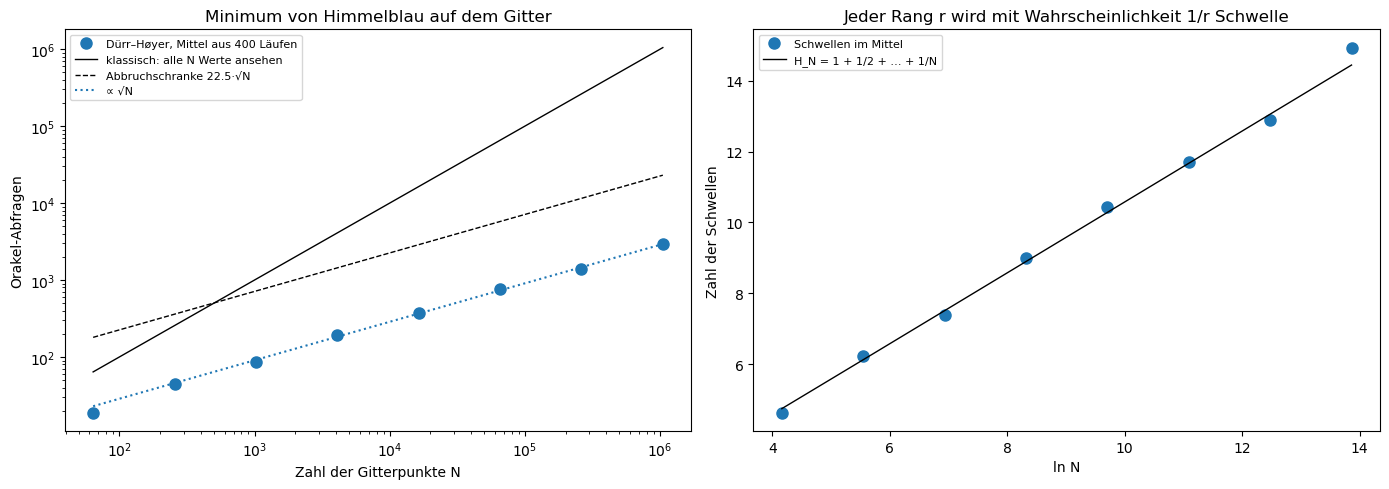

In [17]:
def bbht(M, N, r_, lam=6 / 5):
    """Grover-Suche mit unbekannter Zahl M markierter Elemente (Boyer, Brassard, Høyer, Tapp). Gibt die Zahl der
    Abfragen bis zum Fund zurück; exakt simuliert über die Erfolgswahrscheinlichkeit sin²((2j+1)ϑ)."""
    ziel = np.arcsin(np.sqrt(M / N))
    m, abfragen = 1.0, 0
    while True:
        j = r_.integers(0, int(np.ceil(m)))
        abfragen += j + 1                                # j Iterationen + 1 Abfrage zum Prüfen des Messergebnisses
        if r_.random() < np.sin((2 * j + 1) * ziel) ** 2:
            return abfragen
        m = min(lam * m, np.sqrt(N))


def duerr_hoyer(ordnung, r_):
    """ordnung: Indizes nach aufsteigendem Wert. Rang r = Position in ordnung (0 = Minimum)."""
    N = ordnung.size
    rang = r_.integers(N)                              # zufällige Startschwelle
    abfragen, schwellen = 0, 1
    while rang > 0:
        abfragen += bbht(rang, N, r_)                     # markiert: die rang Elemente unter der Schwelle
        rang = r_.integers(rang)                           # gemessen wird eines davon, gleichverteilt
        schwellen += 1
    return abfragen, schwellen


r_dh = np.random.default_rng(5)
groessen, mittel, mittel_schw = [], [], []
for n in range(6, 21, 2):
    s_ = 2 ** (n // 2)
    g = np.linspace(-5, 5, s_)
    werte = himmelblau(np.array(np.meshgrid(g, g))).ravel()
    ordnung = np.argsort(werte, kind="stable")
    N = werte.size
    laeufe_dh = np.array([duerr_hoyer(ordnung, r_dh) for _ in range(400)])
    groessen.append(N)
    mittel.append(laeufe_dh[:, 0].mean())
    mittel_schw.append(laeufe_dh[:, 1].mean())
    x_min = np.unravel_index(ordnung[0], (s_, s_))
    print(f"N = 2^{n:2d} = {N:8d}: Abfragen im Mittel {mittel[-1]:8.1f} = {mittel[-1] / np.sqrt(N):.2f}·√N "
          f"(90 % unter {np.percentile(laeufe_dh[:, 0], 90) / np.sqrt(N):.2f}·√N);  Schwellen {mittel_schw[-1]:.2f} "
          f"(H_N = {np.sum(1 / np.arange(1, N + 1)):.2f});  Gitterminimum f = {werte[ordnung[0]]:.4f} bei "
          f"({g[x_min[1]]:+.3f}, {g[x_min[0]]:+.3f})")
groessen, mittel = np.array(groessen, dtype=float), np.array(mittel)
exponent = np.polyfit(np.log(groessen), np.log(mittel), 1)[0]
print(f"Angepasster Exponent: Abfragen ∝ N^{exponent:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].loglog(groessen, mittel, "o", ms=8, label="Dürr–Høyer, Mittel aus 400 Läufen")
axes[0].loglog(groessen, groessen, "k-", lw=1, label="klassisch: alle N Werte ansehen")
axes[0].loglog(groessen, 22.5 * np.sqrt(groessen), "k--", lw=1, label="Abbruchschranke 22.5·√N")
axes[0].loglog(groessen, mittel[-1] / np.sqrt(groessen[-1]) * np.sqrt(groessen), "C0:", label="∝ √N")
axes[0].set_xlabel("Zahl der Gitterpunkte N")
axes[0].set_ylabel("Orakel-Abfragen")
axes[0].set_title("Minimum von Himmelblau auf dem Gitter")
axes[0].legend(fontsize=8)
HN = [np.sum(1 / np.arange(1, int(N) + 1)) for N in groessen]
axes[1].plot(np.log(groessen), mittel_schw, "o", ms=8, label="Schwellen im Mittel")
axes[1].plot(np.log(groessen), HN, "k-", lw=1, label="H_N = 1 + 1/2 + … + 1/N")
axes[1].set_xlabel("ln N")
axes[1].set_ylabel("Zahl der Schwellen")
axes[1].set_title("Jeder Rang r wird mit Wahrscheinlichkeit 1/r Schwelle")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

* Das **linke Bild** zeigt die mittlere Zahl der Abfragen gegen $N$, doppelt logarithmisch. Die Punkte liegen auf der gepunkteten Geraden $\propto\sqrt N$, weit unter der klassischen Linie $N$ und unter der Abbruchschranke $22.5\sqrt N$. Bei $N = 2^{20}\approx10^6$ sind es im Mittel 2935 Abfragen statt einer Million.
* Das **rechte Bild** zeigt die mittlere Zahl der Schwellen gegen $\ln N$: Die Punkte folgen der Linie $H_N$ von etwa 4.6 bei $N = 64$ bis 14.9 bei $N = 2^{20}$. Jede Verdopplung von $N$ kostet im Mittel nur $\ln2\approx0.7$ Schwellen mehr.
* Die **Ausgabe** gibt pro $N$: im Mittel $2.35\sqrt N$ bis $2.99\sqrt N$ Abfragen, 90 % der Läufe unter etwa $5\sqrt N$, angepasster Exponent $0.514$, also $\sqrt N$. Das Gitterminimum liegt jeweils nahe einem der vier Minima von Himmelblau, mit Werten zwischen $3\cdot10^{-4}$ und 1.5, je nachdem, wie nah ein Gitterpunkt dem Minimum kommt.

##### *15. VQE-Landschaften: ein Sinus pro Parameter und Barren Plateaus*

Ein Schaltkreis auf $n$ Qubits beginnt mit $R_Y(\pi/4)$ auf jedem Qubit; dann folgen $L$ Schichten aus Drehungen $e^{-i\theta P/2}$ um zufällig gewählte Achsen $P\in\{X, Y, Z\}$ und einer Kette von CZ-Gattern; die Kostenfunktion ist $E = \langle Z_1Z_2\rangle$ (Aufbau wie bei McClean et al. 2018). Ist $E$ in jedem Parameter exakt ein Sinus, und gibt die Parameter-Shift-Regel den exakten Gradienten? Wie fallen $\mathrm{Var}\,E$ und $\mathrm{Var}\,\partial E/\partial\theta_1$ über zufällige Parameter mit $n$ für tiefe ($L = 10n$) und flache ($L = 2$) Schaltkreise, und erreicht der tiefe Schaltkreis den Haar-Wert $1/(2^n + 1)$ aus Abschnitt 8 der Theorie? Vorher vorhersagen: Um welchen Faktor sinkt die Varianz pro zusätzlichem Qubit?

Ein kleiner Zustandsvektor-Simulator rechnet den Schaltkreis exakt. Für einen Parameter wird $E$ an 61 Stellen ausgewertet und mit dem Sinus aus drei Werten verglichen; die Parameter-Shift-Regel wird mit einer zentralen Differenz verglichen. Für $n = 2$ bis 10 werden die Varianzen über viele zufällige Parametersätze geschätzt, und zwei Schnitte durch die Landschaft zeigen $E$ über zwei Parametern.

**Hintergrund & Fachbegriffe:**
- **VQE (Variational Quantum Eigensolver):** Ein parametrisierter Schaltkreis erzeugt einen Zustand $\psi(\theta)$; ein klassischer Optimierer sucht die Parameter mit der kleinsten Energie $E(\theta) = \langle\psi(\theta)\vert H\vert\psi(\theta)\rangle$. Die Energielandschaft ist eine Testfunktion ohne bekanntes Minimum.
- **Pauli-Drehung und CZ:** $e^{-i\theta P/2}$ dreht ein Qubit um die Achse $P$; das CZ-Gatter gibt dem Zustand $\vert11\rangle$ zweier Qubits ein Minuszeichen und verschränkt sie.
- **Parameter-Shift-Regel:** $E'(\theta) = \big(E(\theta + \tfrac\pi2) - E(\theta - \tfrac\pi2)\big)/2$, exakt, weil $E$ in jedem Parameter ein Sinus ist. Auf echter Hardware misst man so Gradienten.
- **Barren Plateau:** Für tiefe, zufällig initialisierte Schaltkreise ist die Landschaft exponentiell flach: Energie und Gradient schwanken nur um etwa $2^{-n/2}$. Ein Optimierer sieht dann fast überall die Steigung null.
- **Haar-Wert und 2-Design:** Ein Haar-zufälliger Zustand gibt $\mathrm{Var}\,E = 1/(2^n + 1)$. Ein Schaltkreis, der in den ersten beiden Momenten so zufällig ist wie Haar-Zustände, heißt 2-Design und erreicht denselben Wert.

E(θ) aus drei Werten als a + b cos θ + c sin θ: größte Abweichung an 61 Stellen 2.5e-16
Gradient: Parameter-Shift -0.094038228181, zentrale Differenz (h = 1e−5) -0.094038228186
n =  2: Var E tief 2.03e-01 (Haar 1/(2^n+1) = 2.00e-01), Var ∂E tief 8.45e-02;  flach: Var E 2.20e-01, Var ∂E 8.98e-02


n =  4: Var E tief 6.03e-02 (Haar 1/(2^n+1) = 5.88e-02), Var ∂E tief 2.67e-02;  flach: Var E 1.68e-01, Var ∂E 8.86e-02


n =  6: Var E tief 1.67e-02 (Haar 1/(2^n+1) = 1.54e-02), Var ∂E tief 5.22e-03;  flach: Var E 1.80e-01, Var ∂E 8.49e-02


n =  8: Var E tief 4.93e-03 (Haar 1/(2^n+1) = 3.89e-03), Var ∂E tief 1.19e-03;  flach: Var E 1.82e-01, Var ∂E 8.82e-02


n = 10: Var E tief 1.25e-03 (Haar 1/(2^n+1) = 9.76e-04), Var ∂E tief 3.94e-04;  flach: Var E 1.37e-01, Var ∂E 1.19e-01
Var ∂E (tief) ∝ 2^(-1.02·n);  Rechenzeit 7.0 s
Schnitt durch die Landschaft, n = 2: E zwischen -0.866 und +0.920


Schnitt durch die Landschaft, n = 8: E zwischen -0.027 und +0.030


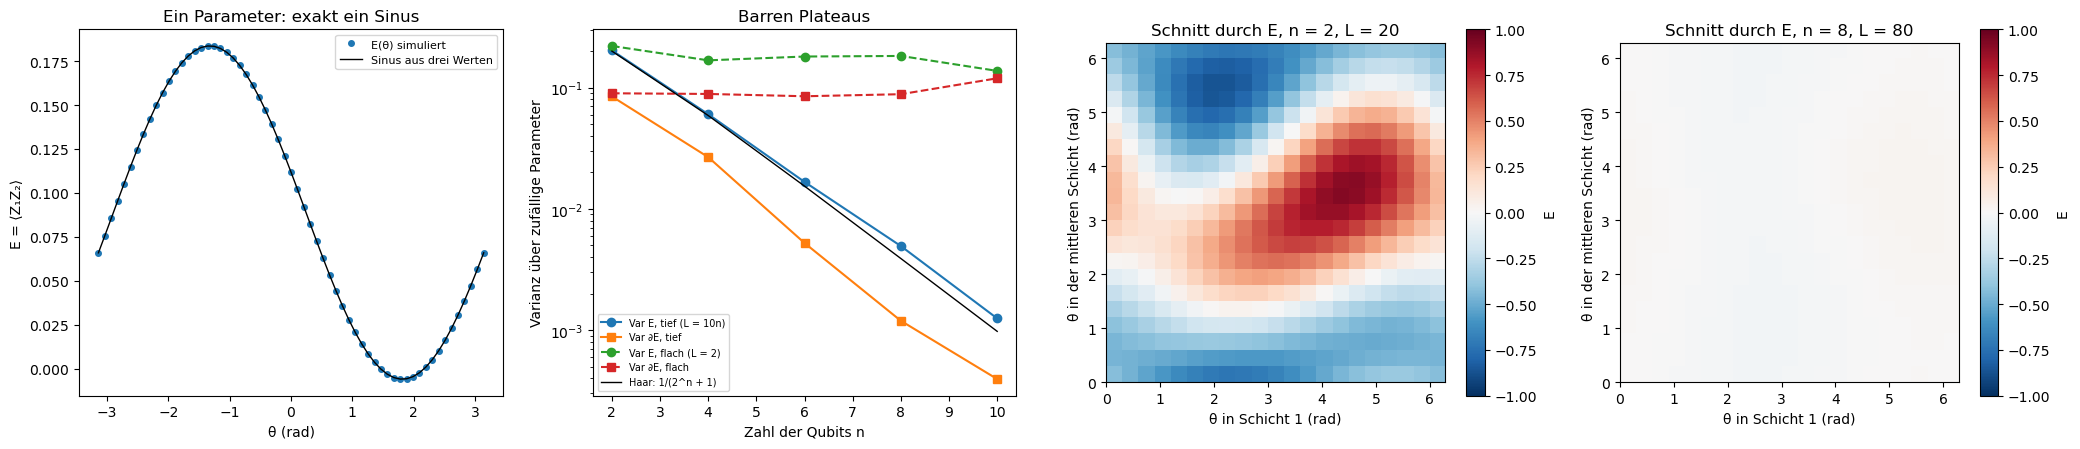

In [18]:
PAULI = {"X": np.array([[0, 1], [1, 0]], dtype=complex), "Y": np.array([[0, -1j], [1j, 0]]),
         "Z": np.diag([1.0, -1.0]).astype(complex)}


def drehung(achse, th):
    return np.cos(th / 2) * np.eye(2) - 1j * np.sin(th / 2) * PAULI[achse]


def gatter1(psi, U, q, n):
    """Ein-Qubit-Gatter U auf Qubit q (q = 0 ist das höchstwertige Bit)."""
    v = psi.reshape(2 ** q, 2, 2 ** (n - q - 1))
    a, b = v[:, 0, :], v[:, 1, :]
    return np.stack([U[0, 0] * a + U[0, 1] * b, U[1, 0] * a + U[1, 1] * b], axis=1).reshape(-1)


def diagonalen(n):
    bits = (np.arange(2 ** n)[:, None] >> np.arange(n - 1, -1, -1)) & 1
    cz = np.prod(np.where(bits[:, :-1] & bits[:, 1:], -1.0, 1.0), axis=1)        # CZ-Kette (0,1), (1,2), …
    zz = np.where(bits[:, 0] ^ bits[:, 1], -1.0, 1.0)                              # Z₁Z₂
    return cz, zz


def energie(theta, achsen, cz, zz):
    L, n = theta.shape
    psi = np.zeros(2 ** n, dtype=complex)
    psi[0] = 1
    ry = drehung("Y", np.pi / 4)
    for q in range(n):
        psi = gatter1(psi, ry, q, n)
    for l in range(L):
        for q in range(n):
            psi = gatter1(psi, drehung(achsen[l, q], theta[l, q]), q, n)
        psi = cz * psi
    return float(np.real(np.vdot(psi, zz * psi)))


r_vqe = np.random.default_rng(15)
n, L = 4, 8
cz, zz = diagonalen(n)
th = r_vqe.uniform(0, 2 * np.pi, (L, n))
achsen = r_vqe.choice(list("XYZ"), size=(L, n))
pos = (3, 2)


def E_von(t):
    th_ = th.copy()
    th_[pos] = t
    return energie(th_, achsen, cz, zz)


e0, ep, em = E_von(0.0), E_von(np.pi / 2), E_von(-np.pi / 2)
a_s, c_s = (ep + em) / 2, (ep - em) / 2
b_s = e0 - a_s
tt = np.linspace(-np.pi, np.pi, 61)
E_tt = np.array([E_von(t) for t in tt])
print(f"E(θ) aus drei Werten als a + b cos θ + c sin θ: größte Abweichung an 61 Stellen {np.max(np.abs(E_tt - (a_s + b_s * np.cos(tt) + c_s * np.sin(tt)))):.1e}")
t_test = th[pos]
shift = (E_von(t_test + np.pi / 2) - E_von(t_test - np.pi / 2)) / 2
zentral = (E_von(t_test + 1e-5) - E_von(t_test - 1e-5)) / 2e-5
print(f"Gradient: Parameter-Shift {shift:+.12f}, zentrale Differenz (h = 1e−5) {zentral:+.12f}")

t0_ = time.time()
n_werte = [2, 4, 6, 8, 10]
var = {"tief": ([], []), "flach": ([], [])}
for n in n_werte:
    cz, zz = diagonalen(n)
    for art, L in [("tief", 10 * n), ("flach", 2)]:
        E_s, G_s = [], []
        for _ in range(100):
            th = r_vqe.uniform(0, 2 * np.pi, (L, n))
            achsen = r_vqe.choice(list("XYZ"), size=(L, n))
            tp, tm = th.copy(), th.copy()
            tp[0, 0] += np.pi / 2
            tm[0, 0] -= np.pi / 2
            E_s.append(energie(th, achsen, cz, zz))
            G_s.append((energie(tp, achsen, cz, zz) - energie(tm, achsen, cz, zz)) / 2)
        var[art][0].append(np.var(E_s))
        var[art][1].append(np.var(G_s))
    print(f"n = {n:2d}: Var E tief {var['tief'][0][-1]:.2e} (Haar 1/(2^n+1) = {1 / (2 ** n + 1):.2e}), "
          f"Var ∂E tief {var['tief'][1][-1]:.2e};  flach: Var E {var['flach'][0][-1]:.2e}, Var ∂E {var['flach'][1][-1]:.2e}")
steig = np.polyfit(n_werte[1:], np.log2(var["tief"][1][1:]), 1)[0]
print(f"Var ∂E (tief) ∝ 2^({steig:.2f}·n);  Rechenzeit {time.time() - t0_:.1f} s")

schnitte = {}
for n in [2, 8]:
    cz, zz = diagonalen(n)
    L = 10 * n
    th = r_vqe.uniform(0, 2 * np.pi, (L, n))
    achsen = r_vqe.choice(list("XYZ"), size=(L, n))
    gitter = np.linspace(0, 2 * np.pi, 21)
    Z = np.zeros((21, 21))
    for i, a1 in enumerate(gitter):
        for j, a2 in enumerate(gitter):
            th_ = th.copy()
            th_[0, 0], th_[L // 2, n - 1] = a1, a2
            Z[j, i] = energie(th_, achsen, cz, zz)
    schnitte[n] = Z
    print(f"Schnitt durch die Landschaft, n = {n}: E zwischen {Z.min():+.3f} und {Z.max():+.3f}")

fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
axes[0].plot(tt, E_tt, "o", ms=4, label="E(θ) simuliert")
axes[0].plot(tt, a_s + b_s * np.cos(tt) + c_s * np.sin(tt), "k-", lw=1, label="Sinus aus drei Werten")
axes[0].set_xlabel("θ (rad)")
axes[0].set_ylabel("E = ⟨Z₁Z₂⟩")
axes[0].set_title("Ein Parameter: exakt ein Sinus")
axes[0].legend(fontsize=8)
nn = np.array(n_werte)
axes[1].semilogy(nn, var["tief"][0], "o-", label="Var E, tief (L = 10n)")
axes[1].semilogy(nn, var["tief"][1], "s-", label="Var ∂E, tief")
axes[1].semilogy(nn, var["flach"][0], "o--", label="Var E, flach (L = 2)")
axes[1].semilogy(nn, var["flach"][1], "s--", label="Var ∂E, flach")
axes[1].semilogy(nn, 1 / (2.0 ** nn + 1), "k-", lw=1, label="Haar: 1/(2^n + 1)")
axes[1].set_xlabel("Zahl der Qubits n")
axes[1].set_ylabel("Varianz über zufällige Parameter")
axes[1].set_title("Barren Plateaus")
axes[1].legend(fontsize=7)
for ax, n in zip(axes[2:], [2, 8]):
    bild = ax.imshow(schnitte[n], extent=[0, 2 * np.pi, 0, 2 * np.pi], origin="lower", cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xlabel("θ in Schicht 1 (rad)")
    ax.set_ylabel("θ in der mittleren Schicht (rad)")
    ax.set_title(f"Schnitt durch E, n = {n}, L = {10 * n}")
    plt.colorbar(bild, ax=ax, label="E")
plt.tight_layout()
plt.show()

* Das **erste Bild** zeigt $E$ als Funktion eines einzelnen Parameters: Die 61 simulierten Punkte liegen auf dem Sinus, der aus nur drei Werten bestimmt wurde (Abweichung $2.5\cdot10^{-16}$). Die Ausgabe vergleicht den Gradienten: Parameter-Shift $-0.094038228181$, zentrale Differenz $-0.094038228186$, gleich auf elf Stellen.
* Das **zweite Bild** zeigt die Varianzen gegen $n$ mit logarithmischer $y$-Achse. Bei tiefen Schaltkreisen (durchgezogen) fallen sie exponentiell: $\mathrm{Var}\,E$ liegt nahe an der schwarzen Haar-Linie $1/(2^n + 1)$ (bei $n = 10$: $1.25\cdot10^{-3}$ gegen $0.98\cdot10^{-3}$), $\mathrm{Var}\,\partial E$ fällt wie $2^{-1.02n}$, also um den Faktor 2 pro Qubit. Flache Schaltkreise mit $L = 2$ (gestrichelt) behalten Varianzen um 0.1: Sie sind nicht zufällig genug für ein Plateau.
* Das **dritte und vierte Bild** zeigen Schnitte durch die Landschaft über zwei Parametern. Bei $n = 2$ ($L = 20$) ist sie deutlich strukturiert, $E$ reicht von $-0.87$ bis $0.92$. Bei $n = 8$ ($L = 80$) ist das Bild gleichmäßig weiß: $E$ liegt nur zwischen $-0.027$ und $0.030$. Das ist ein Barren Plateau, die Easom-Ebene ohne erkennbare Nadel.

#### **Ergebnis**

Beim Lauf vom 2026-10-17:

- **Bump-Funktion:** Alle Ableitungen bis $n = 12$ gehen am Rand gegen null, aber erst sehr nahe daran: $\Psi^{(8)}(0.99) = 1.6\cdot10^7$, $\Psi^{(8)}(0.998) = 10^{-68}$. $\max\vert\Psi^{(n)}\vert/(n!)^2$ wächst geometrisch mit dem Faktor 3.5, $\max\vert\Psi^{(n)}\vert/n!$ schneller als jede geometrische Folge: Gevrey-Klasse 2, nicht analytisch.
- **Bausteine:** $S$ ist exakt 0 für $x\leq0$ und exakt 1 für $x\geq1$, das Plateau exakt 1 auf $[-1, 1]$ und exakt 0 ab $\vert x\vert = 2$. Die Zerlegung der Eins summiert sich bis auf $2\cdot10^{-16}$ zu 1, mit ein oder zwei Termen an jeder Stelle.
- **Mollifier:** $m_1 = 0.33445$. Der größte Fehler für $\vert x\vert$ liegt bei $x = 0$ und ist für alle sechs $\varepsilon$ auf fünf Stellen gleich $\varepsilon m_1$. Der $L^1$-Fehler des Kastens liegt um eine Gitterweite ($2\cdot10^{-4}$) unter $2\varepsilon m_1$, der Träger des geglätteten Kastens ist $[-1 - \varepsilon, 1 + \varepsilon]$ bis auf $2\cdot10^{-4}$.
- **Distributionen:** Für vier zufällige Testfunktionen gelten $-\int H\varphi' = \varphi(0)$, $-\int\vert x\vert\varphi' = \int\mathrm{sign}\,\varphi$ und $-\int\mathrm{sign}\,\varphi' = 2\varphi(0)$ auf sieben Stellen. $\langle\varphi_\varepsilon, g\rangle - g(0)$ folgt $-\varepsilon^2m_2/2$ ($m_2 = 0.15811$) bis auf 0.7 % bei $\varepsilon = 0.5$ und auf vier Stellen ab $\varepsilon = 0.05$, während $\Vert\varphi_\varepsilon\Vert_2$ wie $1/\sqrt\varepsilon$ wächst (8.2 bei $\varepsilon = 0.01$). Real- und Imaginärteil von $\int\varphi/(x + i\varepsilon)$ gehen gegen $\mathrm P\int\varphi/x = -0.3068$ und $-\pi\varphi(0) = -1.1062$; bei $\varepsilon = 10^{-4}$ ist die Abweichung $4\cdot10^{-5}$ bzw. $1\cdot10^{-4}$, von der Ordnung $\varepsilon$.
- **Schwache Lösung:** Für $c = 1$ ist $\vert\langle u, \square\varphi\rangle\vert\leq3\cdot10^{-16}$ bei allen fünf Testfunktionen, bei einer Größe des Integranden $\int\vert u\,\square\varphi\vert$ von 0.7 bis 1.3: Die Dreieckswelle ist eine schwache Lösung. Für $c = 2$ liegen die Werte zwischen $-0.28$ und $-0.43$ und stimmen auf vier Stellen mit dem Linienintegral aus der Theorie (Abschnitt 5) überein.
- **Fourier-Abfall:** Die geschlossenen Formeln für Rechteck, Dreieck und Hann stimmen bis auf $2\cdot10^{-16}$ mit den numerischen Integralen. Die Sattelpunkt-Formel trifft $\hat\Psi$ bei $k = 25$ auf 2.5 %, bei $k = 200$ auf 0.3 % und bei $k = 700$ auf 0.5 %. Bei $k = 400$ ist $\vert\hat\Psi\vert = 1.4\cdot10^{-11}$, acht Größenordnungen unter der Hülle $2/k = 5\cdot10^{-3}$ des Rechtecks.
- **Galerie:** Alle zwölf tabellierten Minima sind bestätigt; die Gittersuche mit Verfeinerung findet keinen kleineren Wert. Der Gradient ist an den Minima bis auf die Rundung der Tabellenwerte null ($\leq10^{-3}$), nur bei Eggholder nicht ($\vert\nabla f\vert = 3.4$), weil das Minimum auf dem Rand $x = 512$ liegt. Bei Schwefel liegen die nächstbesten Minima einer Koordinate bei $-302.5$ und $203.8$, weit vom besten bei $420.97$.
- **Himmelblau:** Die Resultante hat den Grad 9 und neun reelle Nullstellen: vier Minima mit $f = 0$, vier Sattelpunkte ($f = 13.3$, $67.7$, $104.0$, $178.3$) und ein Maximum ($f = 181.6$ bei $(-0.271, -0.923)$); $4 - 4 + 1 = 1$. Der Gradientenabstieg teilt das Quadrat in vier Becken von 24 bis 26 % mit glatten Grenzen, die durch die Sattelpunkte laufen. Newton landet nur in 58 % der Fälle in einem Minimum, in 36 % in einem Sattel und in 6 % im Maximum, mit zerfransten Grenzen.
- **Rosenbrock:** $\kappa = 2508$, Stabilitätsgrenze $\eta<0.001997$. Gradientenabstieg mit $\eta = 0.001$: 34 374 Schritte (Vorhersage 34 594); mit $\eta = 0.002$ keine Konvergenz, der Abstand bleibt bei $3\cdot10^{-3}$. Momentum braucht 3241 Schritte, Adam 5559, Nelder–Mead 249 Funktionsauswertungen, BFGS 41 Auswertungen mit Gradient, Newton 6 Schritte, mit einem Umweg über $(0.76, -3.18)$.
- **Rastrigin, Ackley:** Der Rand des Einzugsgebiets von 0 liegt bei $b = 0.50255$, also $p_1 = 0.0982$. Gemessen: $9.8\cdot10^{-2}$, $9.4\cdot10^{-3}$, $8.4\cdot10^{-4}$ und $9.0\cdot10^{-5}$ für $d = 1$ bis 4, im Rahmen der Statistik gleich $p_1^d$; für $d = 5$ (Vorhersage $9\cdot10^{-6}$) kein Treffer in $10^5$ Starts. Gefunden wurden 11, 121 und 1331 verschiedene lokale Minima für $d = 1, 2, 3$. In $d = 10$ scheitern Multistart und Basin-Hopping auf beiden Funktionen (Rastrigin 3 bis 29, Ackley 15 bis 20). Dual Annealing löst beide in 3 von 3 Läufen mit 21 000 bis 23 000 Auswertungen, Differential Evolution Ackley in 3 von 3 und Rastrigin in 2 von 3 mit 70 000 bis 110 000.
- **Fair vergleichen:** Auf Standard-Rastrigin lösen alle vier Verfahren das Problem (Differential Evolution in 2 von 3 Läufen). Verschieben trifft nur den Start in der Mitte (58.7 statt 0). Drehen trifft Differential Evolution (5 bis 13) und Dual Annealing (11 bis 37), die die Separierbarkeit ausnutzen; Koordinatensuche und Start in der Mitte bleiben bei 0, aber nur, weil sie im Optimum starten. Verschoben und gedreht scheitern alle vier (7 bis 42). Dual Annealing, in Experiment 10 das beste Verfahren, verliert durch die Drehung am meisten.
- **Phasenschätzung:** Das Rechteck hat den RMS-Fehler $10.7/N$ und Schwänze wie $2\sin^2(\pi N\theta)/(\pi^2k)$ (gemessen $8.09\cdot10^{-3}$ und $1.57\cdot10^{-3}$ bei $k = 20$ und $100$, Vorhersage $8.10\cdot10^{-3}$ und $1.62\cdot10^{-3}$). RMS-Fehler der anderen: Sinus $0.500/N$, Hann $0.577/N$, Kaiser $0.723/N$, Bump $0.558/N$. Bei $k = 100$: Sinus $1.4\cdot10^{-8}$, Hann $2.2\cdot10^{-12}$, Kaiser $6.3\cdot10^{-10}$, Bump $5.8\cdot10^{-18}$. Kaiser ist bei $k = 5$ am besten ($1.1\cdot10^{-8}$), fällt danach aber nur wie $1/k$, weil das Fenster am Rand $3.6\cdot10^{-4}$ statt 0 ist.
- **Adiabatisch:** Für $T>50$ liegt der Median von $P$/Vorhersage bei 1.000 (linear), 1.010 (kubisch) und 0.969 (quintisch); die Hüllen fallen mit den Steigungen $-2.01$, $-4.00$ und $-6.05$. Beim glatten Zeitplan ist $\ln P\approx4.37 - 4.01\sqrt T$, wie vom Sattelpunkt vorhergesagt; bei $T = 250$ ist $P = 1.2\cdot10^{-25}$, beim linearen Zeitplan bis zu $1/(4T^2) = 4\cdot10^{-6}$.
- **Grover-Minimumsuche:** Im Mittel $2.35\sqrt N$ bis $2.99\sqrt N$ Abfragen für $N = 2^6$ bis $2^{20}$, angepasster Exponent 0.514, weit unter der Abbruchschranke $22.5\sqrt N$. Bei $N = 2^{20}$ sind es 2935 Abfragen statt $10^6$ klassisch. Die mittlere Zahl der Schwellen folgt $H_N$ (14.9 gegen 14.4 bei $N = 2^{20}$). Das Gitterminimum liegt jeweils nahe einem der vier Minima, mit $f$ zwischen $3\cdot10^{-4}$ und 1.5 je nach Gitter.
- **VQE:** Der Sinus aus drei Werten stimmt an 61 Stellen bis auf $2.5\cdot10^{-16}$, Parameter-Shift und zentrale Differenz stimmen auf 11 Stellen überein. Für tiefe Schaltkreise liegt $\mathrm{Var}\,E$ nahe am Haar-Wert $1/(2^n + 1)$ (bei $n = 10$: $1.25\cdot10^{-3}$ gegen $0.98\cdot10^{-3}$), und $\mathrm{Var}\,\partial E\propto2^{-1.02n}$; flache Schaltkreise mit $L = 2$ behalten Varianzen um 0.1. Der Schnitt durch die Landschaft reicht bei $n = 2$ von $-0.87$ bis $0.92$, bei $n = 8$ nur von $-0.027$ bis $0.030$.

#### **Variationen**

Jeweils zuerst die Vorhersage aufschreiben, dann den Code ändern.

1. **Andere Bump-Funktion** (Experiment 6): $e^{-1/(1 - x^2)^2}$ statt $\Psi$. *(Vorhersage: schnellerer Abfall, etwa $e^{-ck^{2/3}}$, weil der Sattel jetzt im Abstand $\sim k^{-1/3}$ vom Rand liegt.)*
2. **Unsymmetrischer Kern** (Experiment 3): Verschiebe den Kern um $\varepsilon/2$, also $\varphi_\varepsilon(y - \varepsilon/2)$. *(Vorhersage: Der Fehler für $\vert x\vert$ ist jetzt überall ungefähr $\varepsilon/2$, nicht nur in $(-\varepsilon, \varepsilon)$; für glattes $g$ ist $\langle\varphi_\varepsilon, g\rangle - g(0)$ von der Ordnung $\varepsilon$ statt $\varepsilon^2$.)*
3. **Andere Halbebene** (Experiment 4): $1/(x - i\varepsilon)$. *(Vorhersage: Der Imaginärteil geht gegen $+\pi\varphi(0)$.)*
4. **Sprung statt Knick** (Experiment 5): $F = H(\xi)$. *(Vorhersage: für $c = 1$ wieder 0; für $c = 2$ ist $F'' = \delta'$ und der Wert $-3\int\partial_x\varphi(2t, t)\,dt$.)*
5. **Zu großer Schritt** (Experiment 8): $\eta = 0.02$ im Gradientenabstieg. *(Vorhersage: Ein Minimum zieht nur an, wenn $\eta\lambda_{\max}<2$ ist. Die größten Hesse-Eigenwerte an den vier Minima sind 133.8, 80.6, 82.3 und 105.4, also bleiben nur $(-2.81, 3.13)$ und $(3, 2)$ Attraktoren; Startpunkte mit großer Krümmung laufen weg.)*
6. **Lernrate von Adam** (Experiment 9): $0.1$ und $0.001$ statt $0.01$. *(Vorhersage: Adam normiert den Schritt pro Koordinate, die Lernrate ist also ungefähr die Schrittlänge. Mit 0.1 etwa 1800 Schritte, mit 0.001 etwa 13 000.)*
7. **Weniger Mulden** (Experiment 10): $t^2 - A\cos2\pi t + A$ mit $A = 1$ und $A = 0.5$. *(Vorhersage: 7 bzw. 3 lokale Minima pro Koordinate, nur noch nahe der Mitte; die Erfolgswahrscheinlichkeit der lokalen Suche steigt stark.)*
8. **Phase auf dem Gitter** (Experiment 12): $\theta = 0.25$, also $N\theta = 256$. *(Vorhersage: Das Rechteck liefert mit Wahrscheinlichkeit 1 das exakte Ergebnis, weil $\sin^2(\pi N\theta) = 0$; die glatten Fenster nicht. Ihr Vorteil gilt für Phasen zwischen den Gitterpunkten, also im Normalfall.)*
9. **Nur ein Ende glatt** (Experiment 13): $s = \tau^2$. *(Vorhersage: $s'(0) = 0$, aber $s'(1) = 2$; es bleibt nur der Randterm bei $\tau = 1$, und $P\approx1/(4T^2)$ ohne Interferenz-Nullstellen.)*
10. **Andere Schrittregel** (Experiment 14): Faktor $8/7$ statt $6/5$ in der Grover-Suche. *(Vorhersage: Der Vorfaktor ändert sich wenig, der Exponent bleibt $1/2$.)*
11. **Globale Kostenfunktion** (Experiment 15): $O = Z^{\otimes n}$ statt $Z_1Z_2$ beim flachen Schaltkreis. *(Vorhersage: auch mit $L = 2$ exponentiell kleine Varianz, weil sich der Erwartungswert für wenig verschränkte Zustände ungefähr als Produkt von $n$ Faktoren kleiner als 1 schreibt; Cerezo et al. 2021.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was ist eine Testfunktion im Sinne der Analysis, und wozu braucht man beide Eigenschaften?</summary>

Eine $C^\infty$-Funktion mit kompaktem Träger. Glattheit, damit man beliebig viele Ableitungen auf sie abwälzen kann; kompakter Träger, damit bei der partiellen Integration keine Randterme entstehen und alle Integrale endlich und lokal sind.
</details>

<details><summary>2. Warum gibt es außer 0 keine analytische Testfunktion?</summary>

Eine analytische Funktion, die auf einem offenen Intervall verschwindet, verschwindet nach dem Identitätssatz überall. Die Bump-Funktion ist glatt, aber ihre Taylor-Reihe am Rand ist null, obwohl sie selbst daneben positiv ist.
</details>

<details><summary>3. Wie baut man aus e^(−1/x) einen glatten Übergang und eine Zerlegung der Eins?</summary>

$S(x) = f(x)/(f(x) + f(1 - x))$ mit $f(x) = e^{-1/x}$ für $x>0$; der Nenner ist nie null. Zerlegung der Eins: verschobene Bump-Funktionen mit überlappenden Trägern durch ihre Summe teilen.
</details>

<details><summary>4. Was macht ein Mollifier, und wie groß ist der Fehler für eine Lipschitz-stetige Funktion?</summary>

$u\ast\varphi_\varepsilon$ ist glatt, der Träger wächst um höchstens $\varepsilon$, und für Lipschitz-stetiges $u$ ist der Fehler höchstens $L\varepsilon m_1$ mit $m_1 = \int\vert z\vert\varphi$. Bei $\vert x\vert$ wird die Schranke bei 0 erreicht.
</details>

<details><summary>5. Was ist eine Distribution, und wie leitet man sie ab? Was sind H′ und |x|″?</summary>

Eine stetige lineare Abbildung auf den Testfunktionen; $\langle T',\varphi\rangle = -\langle T,\varphi'\rangle$. $H' = \delta$, $\vert x\vert' = \mathrm{sign}$, $\vert x\vert'' = 2\delta$.
</details>

<details><summary>6. Was sagt die Sokhotski–Plemelj-Formel, und wo braucht man sie?</summary>

$1/(x\pm i0) = \mathrm P(1/x)\mp i\pi\delta$. Sie zerlegt retardierte Green-Funktionen und Antwortfunktionen in einen dispersiven Teil (Hauptwert) und einen absorptiven Teil ($\delta$, Energieerhaltung, Fermis goldene Regel); daraus folgen die Kramers–Kronig-Relationen.
</details>

<details><summary>7. Was ist eine schwache Lösung, und warum ist eine Welle F(x − t) mit Knick eine?</summary>

$u$ löst $Lu = 0$ schwach, wenn $\langle u, L^\ast\varphi\rangle = 0$ für alle Testfunktionen gilt. Für $\square = -4\partial_\xi\partial_\eta$ zerfällt das Integral in ein inneres Integral über $\partial_\eta(\ldots)$, das für jede Testfunktion null ist, egal wie rau $F$ ist.
</details>

<details><summary>8. Wie hängen Glattheit und Fourier-Abfall zusammen, und warum fällt die Bump-Funktion wie e^(−√k), nicht wie e^(−k)?</summary>

Jede Ableitung ohne Randterme bringt einen Faktor $1/k$: Sprung $1/k$, Knick $1/k^2$, $C^\infty$ mit kompaktem Träger schneller als jede Potenz. Ein Abfall wie $e^{-a\vert k\vert}$ würde Analytizität im Streifen erzwingen, und analytisch mit kompaktem Träger heißt null. Der Sattelpunkt liegt im Abstand $1/\sqrt{2k}$ vom Rand, wo $e^{-1/(2u)}\approx e^{-\sqrt k}$ ist.
</details>

<details><summary>9. Was ist eine Benchmark-Funktion, und welche Schwierigkeiten stellt man mit ihr ein?</summary>

Eine Funktion mit Formel und bekanntem Optimum, an der man Verfahren misst. Schwierigkeiten: Kondition (Rosenbrock), mehrere gleich gute Minima (Himmelblau), viele lokale Minima (Rastrigin, Ackley), Plateaus (Easom), Täuschung (Schwefel), Minimum am Rand (Eggholder), Separierbarkeit, Dimension.
</details>

<details><summary>10. Warum hat Himmelblau vier Minima mit f = 0, und woher weiß man, dass es vier Sattel und ein Maximum gibt?</summary>

$f = A^2 + B^2$ ist null genau im Schnitt zweier Parabeln, und die Quartik $x^4 - 22x^2 + x + 114$ hat vier reelle Nullstellen. Bézout gibt höchstens neun kritische Punkte, die Resultante zeigt, dass alle reell sind, und Poincaré–Hopf verlangt $\#\text{Min} - \#\text{Sattel} + \#\text{Max} = 1$.
</details>

<details><summary>11. Warum ist Rosenbrock für den Gradientenabstieg schwer, und was hilft?</summary>

Die Hesse-Matrix am Minimum hat die Kondition 2508. Der Schritt muss unter $2/\lambda_{\max}$ bleiben, und dann kriecht die flache Richtung mit $1 - \eta\lambda_{\min}$: über 30 000 Schritte. Momentum, Adam und vor allem Verfahren mit Krümmungsinformation (BFGS, Newton) helfen.
</details>

<details><summary>12. Warum scheitert lokale Suche auf Rastrigin exponentiell in d, und warum muss man Benchmark-Funktionen verschieben und drehen?</summary>

Es gibt $11^d$ lokale Minima, und bei separabler Struktur ist die Erfolgswahrscheinlichkeit $p_1^d$. Ohne Verschiebung und Drehung belohnt der Test Verfahren, die in der Mitte starten oder koordinatenweise suchen; echte Probleme haben weder ihr Optimum in der Mitte noch separable Struktur.
</details>

<details><summary>13. Warum hilft ein glattes Fenster in der Phasenschätzung, und was kostet es?</summary>

Die Fehlerverteilung ist das Betragsquadrat der Fourier-Transformierten des Fensters. Das Rechteck hat Schwänze wie $1/k$, die Bump-Funktion schneller als jede Potenz. Der Preis ist ein breiteres Hauptmaximum und die Vorbereitung des Fensterzustands.
</details>

<details><summary>14. Wie hängt der Fehler eines adiabatischen Algorithmus mit dem Zeitplan zusammen?</summary>

Der Fehler kommt aus Randtermen. Verschwinden $s', \dots, s^{(k)}$ an beiden Enden, ist $P = O(T^{-2(k+1)})$; beim glatten Übergang verschwinden alle, und $P\sim e^{-4\sqrt T}$.
</details>

<details><summary>15. Was leistet die Grover-Minimumsuche auf einer Benchmark-Funktion, und warum ist das für glatte Funktionen kein praktischer Vorteil?</summary>

Sie findet das Minimum von $N$ Gitterwerten mit $O(\sqrt N)$ Abfragen statt $N$. Der Gewinn ist quadratisch und gilt für unstrukturierte Suche; das Orakel muss $f$ kohärent ausrechnen, und für glatte Funktionen kommen Verfahren mit Gradienten mit viel weniger Auswertungen aus (BFGS auf Rosenbrock: 41).
</details>

<details><summary>16. Was sind Barren Plateaus, und worin unterscheiden sie sich von Easom?</summary>

Für Schaltkreise, die so zufällig wie Haar-Zustände sind, ist $\mathrm{Var}\,E = 1/(2^n + 1)$ und der Gradient ebenso exponentiell klein: Die ganze Landschaft ist flach. Easom ist nur außerhalb einer bekannten Nadel flach und in festen zwei Dimensionen; bei Barren Plateaus wächst die Flachheit exponentiell mit der Zahl der Qubits.
</details>

#### **Nächste Schritte**

- **Sobolev-Räume und Finite Elemente:** schwache Ableitungen in $L^2$, Lax–Milgram, die Galerkin-Methode für $-u'' = f$.
- **Green-Funktionen:** $\Delta\frac{-1}{4\pi\vert x\vert} = \delta$ in drei Dimensionen, Fundamentallösungen und Faltung mit Quellen.
- **Fenster und Konzentration:** Slepian-Folgen (DPSS) als Fenster mit der größten Energie in einem Frequenzband, die Unschärfe nach Slepian, Pollak und Landau; das Kaiser-Fenster als Näherung dafür.
- **Polynomiale Filter in Quantenalgorithmen:** Quantum Signal Processing und QSVT nähern Stufen- und Fensterfunktionen durch Polynome an; derselbe Zielkonflikt zwischen Steilheit und Grad wie zwischen Träger und Fourier-Abfall.
- **Benchmarking im Ernst:** die BBOB-Funktionen der Plattform COCO (24 Funktionen, verschoben, gedreht, verrauscht), CMA-ES als Referenzverfahren, Bayessche Optimierung für teure Funktionen.
- **Variationelle Quantenalgorithmen:** QAOA-Landschaften für MaxCut, lokale gegen globale Kostenfunktionen, Initialisierungen gegen Barren Plateaus.

#### **Referenzen**

- L. Hörmander: *The Analysis of Linear Partial Differential Operators I*, 2. Aufl., Springer 1990, Kapitel 1 (Testfunktionen, Faltung, Denjoy–Carleman, Zerlegung der Eins), Kapitel 2 und 3 (Distributionen und ihre Ableitungen), Satz 7.3.1 (Paley–Wiener–Schwartz).
- E. H. Lieb, M. Loss: *Analysis*, 2. Aufl., AMS 2001, Kapitel 6 (Distributionen).
- L. C. Evans: *Partial Differential Equations*, 2. Aufl., AMS 2010, Anhang C.4 (Faltung und Glättung) und Abschnitt 3.4 (schwache Lösungen von Erhaltungsgleichungen, Stoßwellen).
- S. G. Johnson: *Saddle-point integration of $C^\infty$ „bump“ functions*, arXiv:1508.04376 (2015).
- R. de la Madrid: *The role of the rigged Hilbert space in quantum mechanics*, Eur. J. Phys. 26, 287 (2005).
- R. F. Streater, A. S. Wightman: *PCT, Spin and Statistics, and All That*, Benjamin 1964, Kapitel 3 (Felder als operatorwertige Distributionen).
- D. M. Himmelblau: *Applied Nonlinear Programming*, McGraw-Hill 1972.
- H. H. Rosenbrock: *An automatic method for finding the greatest or least value of a function*, Comput. J. 3, 175 (1960).
- M. Jamil, X.-S. Yang: *A literature survey of benchmark functions for global optimisation problems*, Int. J. Math. Model. Numer. Optim. 4, 150 (2013), arXiv:1308.4008.
- S. Surjanovic, D. Bingham: *Virtual Library of Simulation Experiments: Test Functions and Datasets*, Simon Fraser University, https://www.sfu.ca/~ssurjano (Formeln, Gebiete und Minima der Galerie).
- N. Hansen, A. Auger, R. Ros, O. Mersmann, T. Tušar, D. Brockhoff: *COCO: a platform for comparing continuous optimizers in a black-box setting*, Optim. Methods Softw. 36, 114 (2021).
- J. Nocedal, S. J. Wright: *Numerical Optimization*, 2. Aufl., Springer 2006, Kapitel 3 (Liniensuche, Konvergenzrate des Gradientenverfahrens) und 6 (Quasi-Newton, BFGS).
- D. H. Wolpert, W. G. Macready: *No free lunch theorems for optimization*, IEEE Trans. Evol. Comput. 1, 67 (1997).
- D. P. Kingma, J. Ba: *Adam: A method for stochastic optimization*, arXiv:1412.6980 (2014).
- R. Storn, K. Price: *Differential evolution*, J. Global Optim. 11, 341 (1997); C. Tsallis, D. A. Stariolo: *Generalized simulated annealing*, Physica A 233, 395 (1996); D. J. Wales, J. P. K. Doye, J. Phys. Chem. A 101, 5111 (1997) (Basin-Hopping).
- G. Rendon, T. Izubuchi, Y. Kikuchi: *Effects of cosine tapering window on quantum phase estimation*, Phys. Rev. D 106, 034503 (2022).
- D. W. Berry, H. M. Wiseman: *Optimal states and almost optimal adaptive measurements for quantum interferometry*, Phys. Rev. Lett. 85, 5098 (2000) (das Sinus-Fenster).
- T. Albash, D. A. Lidar: *Adiabatic quantum computation*, Rev. Mod. Phys. 90, 015002 (2018), Abschnitt II (adiabatische Sätze und Randterme).
- A. Elgart, G. A. Hagedorn: *A note on the switching adiabatic theorem*, J. Math. Phys. 53, 102202 (2012).
- C. Dürr, P. Høyer: *A quantum algorithm for finding the minimum*, arXiv:quant-ph/9607014 (1996); M. Boyer, G. Brassard, P. Høyer, A. Tapp: *Tight bounds on quantum searching*, Fortschr. Phys. 46, 493 (1998).
- K. Mitarai, M. Negoro, M. Kitagawa, K. Fujii: *Quantum circuit learning*, Phys. Rev. A 98, 032309 (2018); M. Schuld, V. Bergholm, C. Gogolin, J. Izaac, N. Killoran: *Evaluating analytic gradients on quantum hardware*, Phys. Rev. A 99, 032331 (2019) (Parameter-Shift-Regel).
- J. R. McClean, S. Boixo, V. N. Smelyanskiy, R. Babbush, H. Neven: *Barren plateaus in quantum neural network training landscapes*, Nat. Commun. 9, 4812 (2018).
- M. Cerezo, A. Sone, T. Volkoff, L. Cincio, P. J. Coles: *Cost function dependent barren plateaus in shallow parametrized quantum circuits*, Nat. Commun. 12, 1791 (2021).